# Classical and Quantum-Wave Dynamics of Self-Gravitating Systems

## Research question

How do an initially Gaussian self-gravitating cloud's **global size**, **central concentration**, and **coarse-grained spatial entropy** respond to the competition between gravity and wave dispersion? Where do a 3D wave model and an energy-matched 3D particle model agree or differ?

## Numerical sections

1. **Exploratory planar N-body dynamics** — particles confined to an x–y plane, interacting through a softened 3D Newtonian inverse-square force law; Gaussian velocity statistics, entropy estimators, virial diagnostics and numerical sensitivity studies. This is not fundamental 2D Poisson gravity.
2. **3D classical dynamics** — Gaussian clouds, Plummer models and exploratory gravitational caloric relationships.
3. **3D wave dynamics** — dimensionless Schrödinger–Poisson gravity with a Fourier Poisson solver and symmetric split-step evolution.
4. **Controls** — gravity on/off, matched initial Gaussian position and kinetic-energy distributions, multiple particle seeds, grid/timestep/box-size checks.
5. **Comparisons** — density profiles, spatial Shannon entropy, initial energy ratio and contraction versus dispersion.
6. **Reproducibility** — numerical diagnostics, exported datasets and figures, one final archive.

## Interpretation rules

- **Dimensionless** simulation units are used throughout; no astrophysical physical scale is inferred.
- The Schrödinger–Poisson model uses **Newtonian self-gravity coupled to a wave field**; it is **not a quantum-gravity theory**.
- The early planar N-body model uses a 3D inverse-square force law restricted to two spatial coordinates; it is **not** fundamental 2D gravity and is **not** the same parameter-matched experiment as the later 3D wave comparison.
- Spatial Shannon entropy is a distributional statistic, **not** total thermodynamic entropy.
- The Plummer energy–temperature relationship is an exploratory/model-dependent diagnostic, **not** proof of equilibrium negative heat capacity.
- Numerical conservation and limited convergence checks support the calculations but **do not** establish universal physical laws or research novelty.
- A clean sequential run in a new Google Colab runtime is required to regenerate all results.

## Specific finite-time structural question

Can an expanding cloud become **more centrally concentrated** at the same time, and can multi-scale concentration and entropy diagnostics identify that regime? The accompanying parameter/grid tests are limited checks of this behaviour; it is **not** claimed as a new physical phenomenon.


## Revision note (November 2026)
Some previously exported labels overstated scientific interpretation. This revision removes the false implication that the Plummer E–T fits establish equilibrium heat capacity, distinguishes a periodic energy ratio from a virial ratio, clarifies that the observed structural crossover is finite-time, and ensures the last export updates its README. **Run all code cells in a fresh Colab runtime before republishing figures or quoting new validation results.**

## Public presentation guidance

Use the `figures/` files generated by the **final clean execution**, not thumbnails from web searches. In particular, Figure 10 has four dots because it compares four independent effective-ℏ simulations; Figure 11 shows a finer parameter sweep. Avoid calling the latter a quantum-gravitational phase transition.


INITIAL SIMULATION CONFIGURATION
--------------------------------
Number of particles : 120
Gravity constant    : 2.0
Time step           : 0.0001
Number of steps     : 1000
Softening length    : 0.05
Position sigma      : 0.5
Velocity sigma      : 0.02
Random seed         : 42

INITIAL SYSTEM PROPERTIES
--------------------------------
Mean position : [1.85037171e-18 3.70074342e-18]
Mean velocity : [6.64977332e-19 2.89120579e-19]


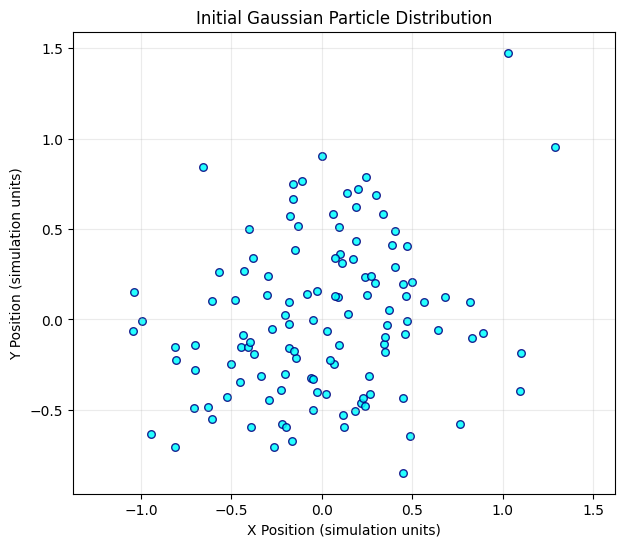

In [2]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 1: CLASSICAL SELF-GRAVITATING SYSTEM
# CELL 1: IMPORTS, PARAMETERS AND INITIAL CONDITIONS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- SIMULATION PARAMETERS ----------

N = 120
G = 2.0
DT = 0.0001
STEPS = 1000
EPSILON = 0.05

PARTICLE_MASS = 1.0

# Gaussian initial-condition parameters
POSITION_SIGMA = 0.5
VELOCITY_SIGMA = 0.02

# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# ---------- INITIAL PARTICLE POSITIONS ----------

positions = rng.normal(
    loc=0.0,
    scale=POSITION_SIGMA,
    size=(N, 2)
)

# ---------- INITIAL PARTICLE VELOCITIES ----------

velocities = rng.normal(
    loc=0.0,
    scale=VELOCITY_SIGMA,
    size=(N, 2)
)

# ---------- REMOVE CENTER-OF-MASS MOTION ----------

positions -= np.mean(positions, axis=0)
velocities -= np.mean(velocities, axis=0)

# ---------- PARTICLE MASSES ----------

masses = np.full(N, PARTICLE_MASS)

# ---------- SAVE INITIAL STATE ----------

initial_positions = positions.copy()
initial_velocities = velocities.copy()

# ---------- DISPLAY INITIAL CONDITIONS ----------

print("INITIAL SIMULATION CONFIGURATION")
print("--------------------------------")
print(f"Number of particles : {N}")
print(f"Gravity constant    : {G}")
print(f"Time step           : {DT}")
print(f"Number of steps     : {STEPS}")
print(f"Softening length    : {EPSILON}")
print(f"Position sigma      : {POSITION_SIGMA}")
print(f"Velocity sigma      : {VELOCITY_SIGMA}")
print(f"Random seed         : {SEED}")

print("\nINITIAL SYSTEM PROPERTIES")
print("--------------------------------")
print("Mean position :", np.mean(positions, axis=0))
print("Mean velocity :", np.mean(velocities, axis=0))

# ---------- INITIAL PARTICLE DISTRIBUTION ----------

plt.figure(figsize=(7, 6))

plt.scatter(
    positions[:, 0],
    positions[:, 1],
    s=30,
    color="cyan",
    edgecolor="navy",
    alpha=0.85
)

plt.title("Initial Gaussian Particle Distribution")
plt.xlabel("X Position (simulation units)")
plt.ylabel("Y Position (simulation units)")

plt.axis("equal")
plt.grid(True, alpha=0.25)

plt.show()



GRAVITATIONAL FORCE VERIFICATION
--------------------------------
Acceleration array shape: (120, 2)
All values finite: True

First 5 particle accelerations:
[[  57.48780185  770.42825156]
 [-389.9565817  -517.92532636]
 [ 283.87442992  120.05477623]
 [-302.66368897  -32.82531252]
 [-407.69070266  395.62394237]]

Total gravitational force: [-2.50111043e-12  1.73372428e-12]
Total force magnitude: 3.0432471547739125e-12


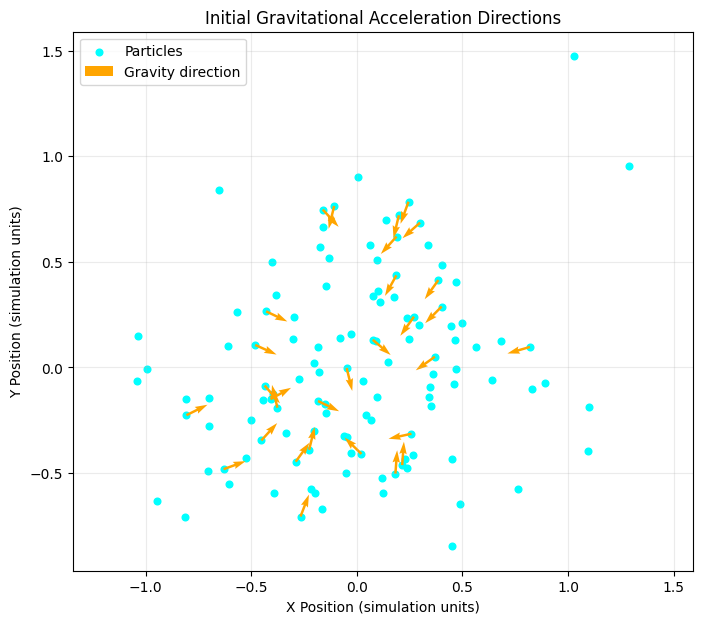

In [3]:

# ============================================================
# PHASE 1: CLASSICAL SELF-GRAVITATING SYSTEM
# CELL 2: PLANAR PARTICLES WITH SOFTENED 3D NEWTONIAN FORCE LAW
# ============================================================

def compute_accelerations(pos, masses, G, epsilon):

    # Relative displacement between every pair of particles
    diff = pos[:, None, :] - pos[None, :, :]

    # Softened squared separation
    dist2 = np.sum(diff**2, axis=2) + epsilon**2

    # Inverse cubed softened distance
    inv_dist3 = dist2**(-1.5)

    # A particle must not exert gravity on itself
    np.fill_diagonal(inv_dist3, 0.0)

    # Gravitational acceleration on every particle
    accelerations = -G * np.sum(
        diff * inv_dist3[:, :, None] * masses[None, :, None],
        axis=1
    )

    return accelerations


# ---------- CALCULATE INITIAL ACCELERATIONS ----------

accelerations = compute_accelerations(
    positions,
    masses,
    G,
    EPSILON
)

# ---------- VERIFY GRAVITATIONAL CALCULATION ----------

forces = masses[:, None] * accelerations
total_force = np.sum(forces, axis=0)

print("GRAVITATIONAL FORCE VERIFICATION")
print("--------------------------------")

print("Acceleration array shape:", accelerations.shape)
print("All values finite:", np.all(np.isfinite(accelerations)))

print("\nFirst 5 particle accelerations:")
print(accelerations[:5])

print("\nTotal gravitational force:", total_force)
print("Total force magnitude:", np.linalg.norm(total_force))

assert accelerations.shape == (N, 2)
assert np.all(np.isfinite(accelerations))
assert np.linalg.norm(total_force) < 1e-9 * max(
    1.0, np.sum(np.linalg.norm(forces, axis=1))
)

# ---------- VISUALIZE GRAVITATIONAL FORCE DIRECTIONS ----------

arrow_length = np.linalg.norm(accelerations, axis=1)

unit_directions = accelerations / np.maximum(
    arrow_length[:, None], 1e-12
)

plt.figure(figsize=(8, 7))

plt.scatter(
    positions[:, 0],
    positions[:, 1],
    s=23,
    color="cyan",
    label="Particles"
)

# Show arrows for every fourth particle for clarity
idx = np.arange(0, N, 4)

plt.quiver(
    positions[idx, 0],
    positions[idx, 1],
    unit_directions[idx, 0],
    unit_directions[idx, 1],
    color="orange",
    angles="xy",
    scale_units="xy",
    scale=9,
    width=0.004,
    label="Gravity direction"
)

plt.title("Initial Gravitational Acceleration Directions")
plt.xlabel("X Position (simulation units)")
plt.ylabel("Y Position (simulation units)")
plt.axis("equal")
plt.grid(alpha=0.25)
plt.legend()
plt.show()



GRAVITATIONAL MOTION SIMULATION
--------------------------------
Particles: 120
Completed steps: 1000
Simulated time: 0.1

INITIAL CENTER OF MASS: [1.85037171e-18 3.70074342e-18]
FINAL CENTER OF MASS: [ 8.82829689e-17 -4.00142882e-17]

Initial RMS radius: 0.6354640490440069
Final RMS radius: 0.5509379444344603


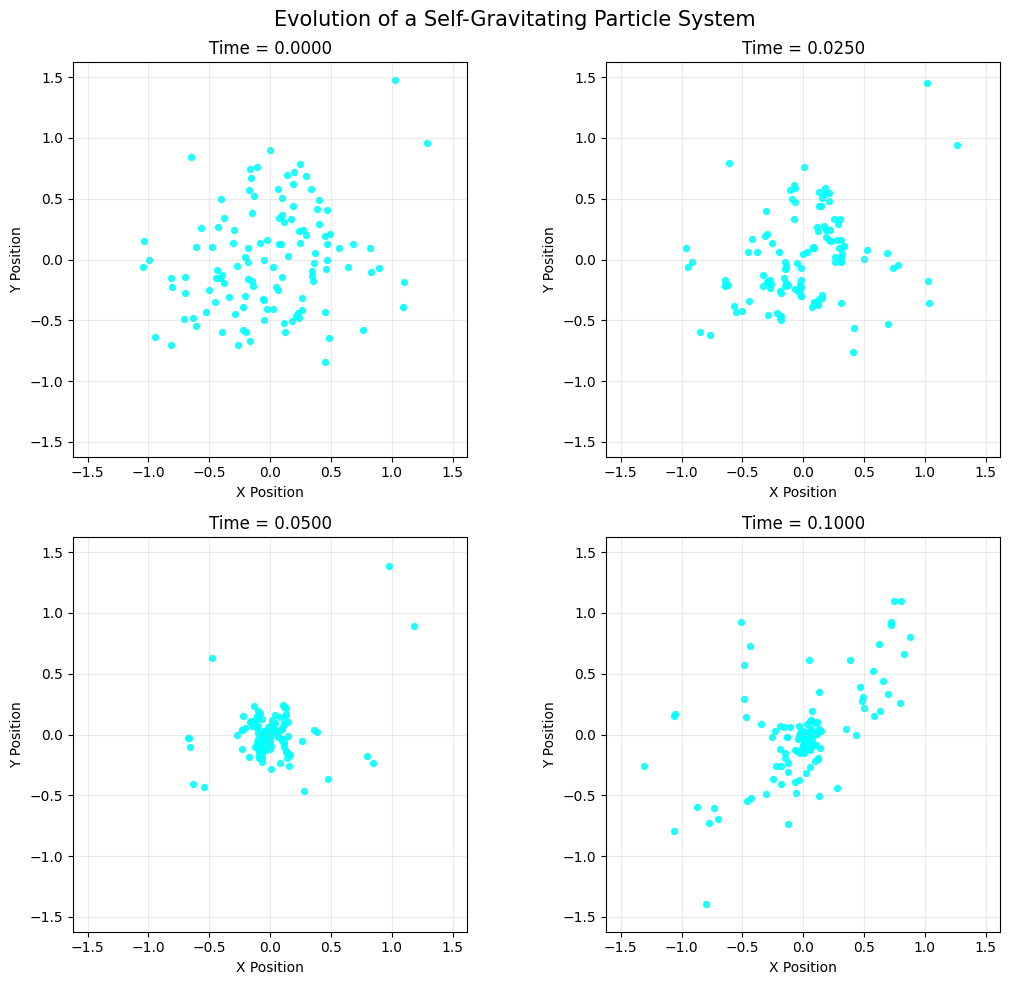

In [4]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 1: CLASSICAL GRAVITATIONAL DYNAMICS
# CELL 3: VELOCITY VERLET TIME EVOLUTION
# ============================================================

# Start from the original Gaussian initial conditions
sim_positions = initial_positions.copy()
sim_velocities = initial_velocities.copy()

# Store the complete evolution for later entropy analysis
position_history = np.zeros((STEPS + 1, N, 2))
velocity_history = np.zeros((STEPS + 1, N, 2))

position_history[0] = sim_positions
velocity_history[0] = sim_velocities

# Initial gravitational accelerations
a = compute_accelerations(
    sim_positions, masses, G, EPSILON
)

# ---------- VELOCITY VERLET INTEGRATION ----------

for step in range(1, STEPS + 1):

    # 1. Update particle positions
    sim_positions = (
        sim_positions
        + sim_velocities * DT
        + 0.5 * a * DT**2
    )

    # 2. Calculate accelerations at new positions
    a_new = compute_accelerations(
        sim_positions, masses, G, EPSILON
    )

    # 3. Update particle velocities
    sim_velocities = (
        sim_velocities
        + 0.5 * (a + a_new) * DT
    )

    # 4. Prepare for the next time step
    a = a_new

    # 5. Save the current state
    position_history[step] = sim_positions
    velocity_history[step] = sim_velocities

# ---------- BASIC VALIDATION ----------

assert np.all(np.isfinite(position_history))
assert np.all(np.isfinite(velocity_history))

initial_com = np.average(
    position_history[0], axis=0, weights=masses
)

final_com = np.average(
    position_history[-1], axis=0, weights=masses
)

initial_rms_radius = np.sqrt(
    np.mean(np.sum(position_history[0]**2, axis=1))
)

final_rms_radius = np.sqrt(
    np.mean(np.sum(position_history[-1]**2, axis=1))
)

print("GRAVITATIONAL MOTION SIMULATION")
print("--------------------------------")
print("Particles:", N)
print("Completed steps:", STEPS)
print("Simulated time:", STEPS * DT)

print("\nINITIAL CENTER OF MASS:", initial_com)
print("FINAL CENTER OF MASS:", final_com)

print("\nInitial RMS radius:", initial_rms_radius)
print("Final RMS radius:", final_rms_radius)

# ---------- VISUALIZE EVOLUTION ----------

snapshot_steps = [
    0,
    STEPS // 4,
    STEPS // 2,
    STEPS
]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

axis_limit = max(
    1.5,
    1.1 * np.max(np.abs(position_history))
)

for ax, s in zip(axes.flat, snapshot_steps):

    p = position_history[s]

    ax.scatter(
        p[:, 0],
        p[:, 1],
        s=18,
        color="cyan",
        alpha=0.85
    )

    ax.set_title(f"Time = {s * DT:.4f}")
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")

    ax.set_xlim(-axis_limit, axis_limit)
    ax.set_ylim(-axis_limit, axis_limit)

    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Evolution of a Self-Gravitating Particle System",
    fontsize=15
)

plt.tight_layout()
plt.show()



ENERGY CONSERVATION VERIFICATION
--------------------------------
Initial kinetic energy   : 0.049513
Initial potential energy : -26302.923679
Initial total energy     : -26302.874166

Final kinetic energy     : 24301.608579
Final potential energy   : -50605.176129
Final total energy       : -26303.567550

Maximum relative energy error : 0.005791%
Final relative energy error   : 0.002636%


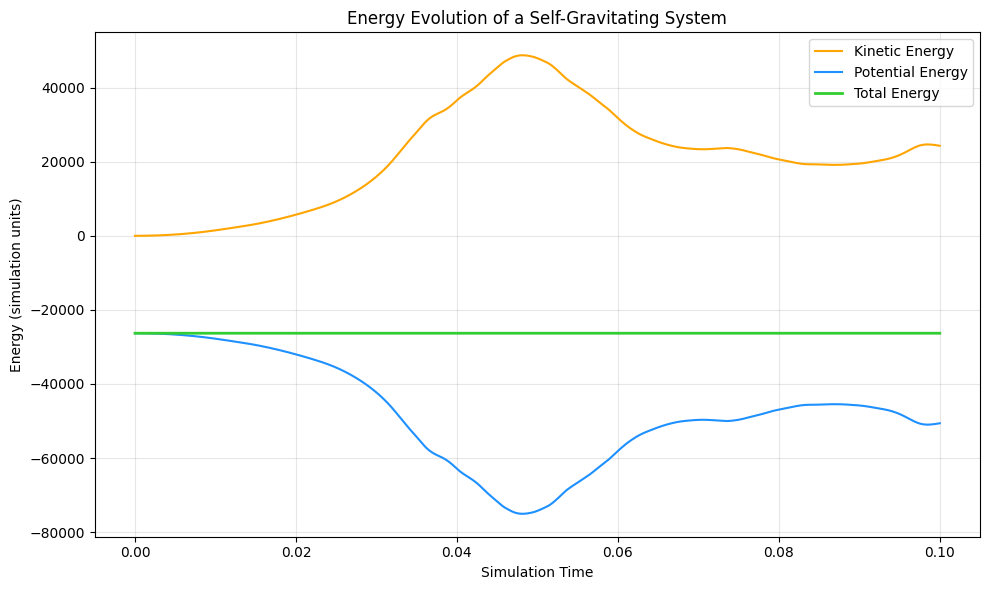

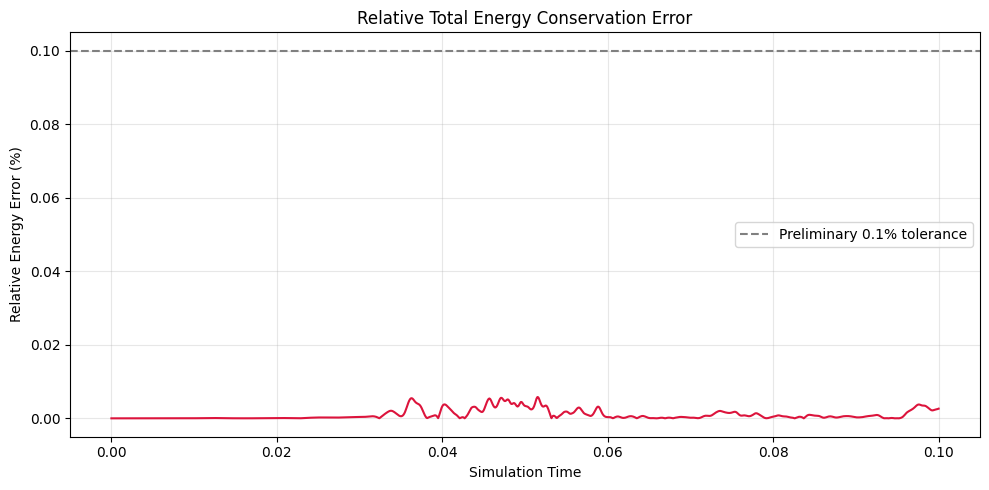


ENERGY CONSERVATION: PRELIMINARY PASS


In [5]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 1: CLASSICAL GRAVITATIONAL DYNAMICS
# CELL 4: ENERGY CONSERVATION AND NUMERICAL ACCURACY
# ============================================================

# ---------- ENERGY CALCULATION FUNCTION ----------

def calculate_energy(pos, vel):

    # Kinetic energy of all particles
    kinetic = 0.5 * np.sum(
        masses[:, None] * vel**2
    )

    # Pairwise separations
    diff = pos[:, None, :] - pos[None, :, :]

    dist2 = np.sum(diff**2, axis=2) + EPSILON**2

    # Select each unique particle pair only once
    i, j = np.triu_indices(N, k=1)

    # Softened Newtonian gravitational potential energy
    potential = -G * np.sum(
        masses[i] * masses[j] / np.sqrt(dist2[i, j])
    )

    return kinetic, potential


# ---------- COMPUTE ENERGY AT EVERY TIME STEP ----------

kinetic_history = np.zeros(STEPS + 1)
potential_history = np.zeros(STEPS + 1)

for step in range(STEPS + 1):

    K, U = calculate_energy(
        position_history[step],
        velocity_history[step]
    )

    kinetic_history[step] = K
    potential_history[step] = U


total_energy_history = (
    kinetic_history + potential_history
)

time_array = np.arange(STEPS + 1) * DT


# ---------- CALCULATE NUMERICAL ENERGY ERROR ----------

initial_energy = total_energy_history[0]

relative_energy_error = (
    np.abs(total_energy_history - initial_energy)
    / abs(initial_energy)
) * 100

maximum_error = np.max(relative_energy_error)
final_error = relative_energy_error[-1]


# ---------- PRINT RESULTS ----------

print("ENERGY CONSERVATION VERIFICATION")
print("--------------------------------")

print(f"Initial kinetic energy   : {kinetic_history[0]:.6f}")
print(f"Initial potential energy : {potential_history[0]:.6f}")
print(f"Initial total energy     : {initial_energy:.6f}")

print(f"\nFinal kinetic energy     : {kinetic_history[-1]:.6f}")
print(f"Final potential energy   : {potential_history[-1]:.6f}")
print(f"Final total energy       : {total_energy_history[-1]:.6f}")

print(f"\nMaximum relative energy error : {maximum_error:.6f}%")
print(f"Final relative energy error   : {final_error:.6f}%")


# ---------- ENERGY EVOLUTION GRAPH ----------

plt.figure(figsize=(10, 6))

plt.plot(
    time_array,
    kinetic_history,
    label="Kinetic Energy",
    color="orange"
)

plt.plot(
    time_array,
    potential_history,
    label="Potential Energy",
    color="dodgerblue"
)

plt.plot(
    time_array,
    total_energy_history,
    label="Total Energy",
    color="limegreen",
    linewidth=2
)

plt.title("Energy Evolution of a Self-Gravitating System")
plt.xlabel("Simulation Time")
plt.ylabel("Energy (simulation units)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- ENERGY CONSERVATION ERROR GRAPH ----------

plt.figure(figsize=(10, 5))

plt.plot(
    time_array,
    relative_energy_error,
    color="crimson",
    linewidth=1.5
)

plt.axhline(
    0.1,
    color="gray",
    linestyle="--",
    label="Preliminary 0.1% tolerance"
)

plt.title("Relative Total Energy Conservation Error")
plt.xlabel("Simulation Time")
plt.ylabel("Relative Energy Error (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- INITIAL VALIDATION ----------

assert np.all(np.isfinite(total_energy_history))
assert initial_energy != 0

if maximum_error < 0.1:
    print("\nENERGY CONSERVATION: PRELIMINARY PASS")
else:
    print("\nENERGY CONSERVATION: NEEDS INVESTIGATION")



GAUSSIAN DISTRIBUTION ANALYSIS

Initial Vx
Mean velocity       : 0.000000
Standard deviation  : 0.019943
Shapiro-Wilk p-value: 0.781043
Outside plotted range: 0
Result: Gaussian distribution not rejected

Initial Vy
Mean velocity       : 0.000000
Standard deviation  : 0.020843
Shapiro-Wilk p-value: 0.616952
Outside plotted range: 0
Result: Gaussian distribution not rejected

Final Vx
Mean velocity       : 0.000000
Standard deviation  : 15.542573
Shapiro-Wilk p-value: 0.297497
Outside plotted range: 0
Result: Gaussian distribution not rejected

Final Vy
Mean velocity       : -0.000000
Standard deviation  : 12.917384
Shapiro-Wilk p-value: 0.0748811
Outside plotted range: 0
Result: Gaussian distribution not rejected


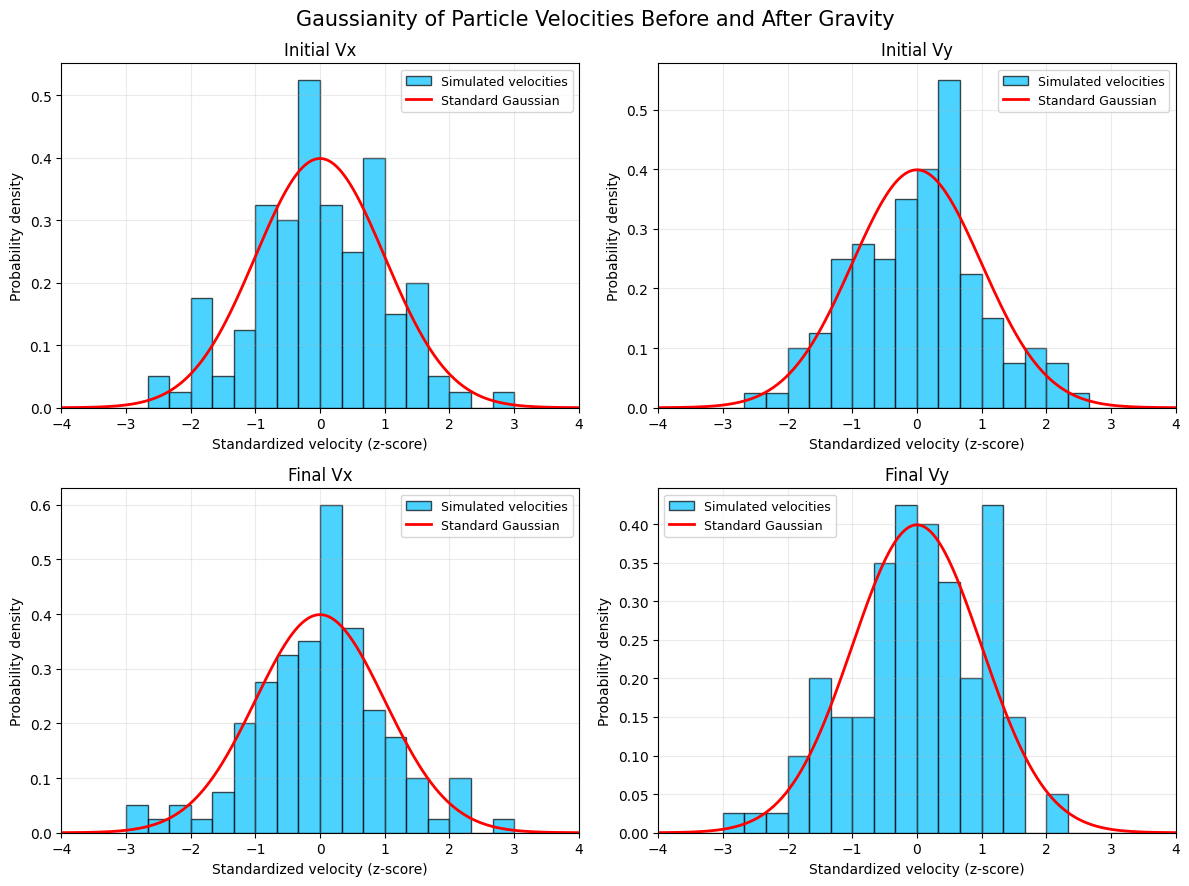


GRAVITATIONAL VELOCITY EVOLUTION
Initial RMS speed: 0.028727
Final RMS speed  : 20.125278


In [6]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 2: APPLIED STATISTICAL MECHANICS
# CELL 5: GAUSSIAN VELOCITY DISTRIBUTION ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro, norm

# ---------- INITIAL AND FINAL VELOCITIES ----------

v_initial = velocity_history[0]
v_final = velocity_history[-1]

datasets = [
    ("Initial Vx", v_initial[:, 0]),
    ("Initial Vy", v_initial[:, 1]),
    ("Final Vx", v_final[:, 0]),
    ("Final Vy", v_final[:, 1])
]

# ---------- GAUSSIAN COMPARISON ----------

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

z_grid = np.linspace(-4, 4, 400)
bins = np.linspace(-4, 4, 25)
bin_width = bins[1] - bins[0]

print("GAUSSIAN DISTRIBUTION ANALYSIS")
print("=" * 60)

for ax, (name, data) in zip(axes.flat, datasets):

    mean = np.mean(data)
    std = np.std(data, ddof=1)

    # Standardize to compare distribution shapes
    z = (data - mean) / std

    # Shapiro-Wilk normality test
    statistic, p_value = shapiro(data)

    # Histogram normalized by full sample size
    ax.hist(
        z,
        bins=bins,
        weights=np.full(len(z), 1.0 / (len(z) * bin_width)),
        color="deepskyblue",
        alpha=0.7,
        edgecolor="black",
        label="Simulated velocities"
    )

    # Reference Gaussian probability density
    ax.plot(
        z_grid,
        norm.pdf(z_grid),
        color="red",
        linewidth=2,
        label="Standard Gaussian"
    )

    ax.set_title(name)
    ax.set_xlabel("Standardized velocity (z-score)")
    ax.set_ylabel("Probability density")
    ax.set_xlim(-4, 4)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

    outliers = np.sum(np.abs(z) > 4)

    print(f"\n{name}")
    print(f"Mean velocity       : {mean:.6f}")
    print(f"Standard deviation  : {std:.6f}")
    print(f"Shapiro-Wilk p-value: {p_value:.6g}")
    print(f"Outside plotted range: {outliers}")

    if p_value < 0.05:
        print("Result: Evidence against a Gaussian distribution")
    else:
        print("Result: Gaussian distribution not rejected")

plt.suptitle(
    "Gaussianity of Particle Velocities Before and After Gravity",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ---------- ACTUAL VELOCITY MAGNITUDES ----------

initial_rms_speed = np.sqrt(
    np.mean(np.sum(v_initial**2, axis=1))
)

final_rms_speed = np.sqrt(
    np.mean(np.sum(v_final**2, axis=1))
)

print("\n" + "=" * 60)
print("GRAVITATIONAL VELOCITY EVOLUTION")
print("=" * 60)

print(f"Initial RMS speed: {initial_rms_speed:.6f}")
print(f"Final RMS speed  : {final_rms_speed:.6f}")



COARSE-GRAINED SHANNON ENTROPY ANALYSIS
Particles: 120
Grid: 15 x 15
Logarithm: Natural (entropy in nats)

Time       Spatial H      Velocity H
---------------------------------------------
0.0000     3.909429       -0.000000
0.0250     3.449690       3.040611
0.0500     2.293008       3.969446
0.0750     2.943840       3.700020
0.1000     3.077314       3.631125

CHANGE FROM INITIAL TO FINAL
---------------------------------------------
Spatial entropy change : -0.832114
Velocity entropy change: +3.631125


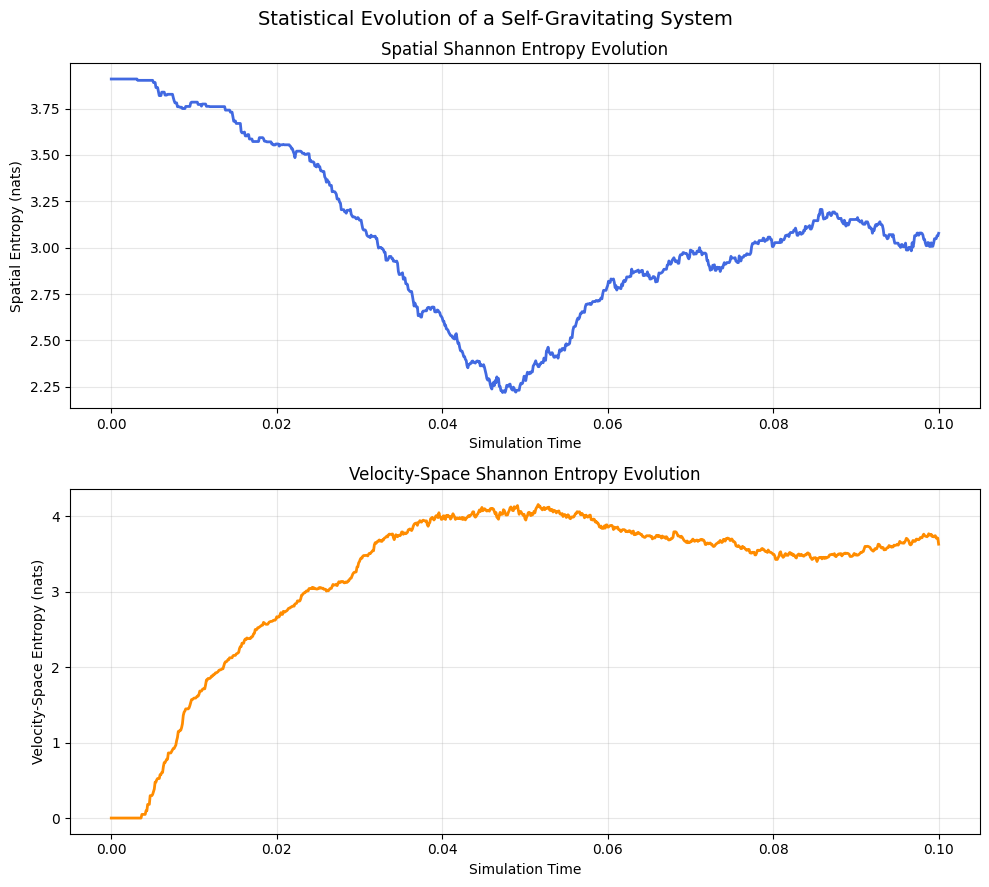

In [7]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 2: APPLIED STATISTICAL MECHANICS
# CELL 6: FIXED-GRID SHANNON ENTROPY EVOLUTION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- FIXED HISTOGRAM RESOLUTION ----------

BINS = 15

# Fixed boundaries for the complete simulation
position_limit = 1.001 * np.max(
    np.abs(position_history)
) + 1e-9

velocity_limit = 1.001 * np.max(
    np.abs(velocity_history)
) + 1e-9

position_edges = np.linspace(
    -position_limit, position_limit, BINS + 1
)

velocity_edges = np.linspace(
    -velocity_limit, velocity_limit, BINS + 1
)

# ---------- SHANNON ENTROPY FUNCTION ----------

def calculate_shannon_entropy_2d(data, edges):

    counts, _, _ = np.histogram2d(
        data[:, 0],
        data[:, 1],
        bins=(edges, edges)
    )

    # Verify that no particles fall outside the grid
    assert int(counts.sum()) == len(data)

    probabilities = counts[counts > 0] / len(data)

    entropy = -np.sum(
        probabilities * np.log(probabilities)
    )

    occupied_cells = np.count_nonzero(counts)

    return entropy, occupied_cells


# ---------- ENTROPY THROUGH TIME ----------

spatial_entropy = np.zeros(STEPS + 1)
velocity_entropy = np.zeros(STEPS + 1)

spatial_occupied = np.zeros(STEPS + 1, dtype=int)
velocity_occupied = np.zeros(STEPS + 1, dtype=int)

for step in range(STEPS + 1):

    spatial_entropy[step], spatial_occupied[step] = (
        calculate_shannon_entropy_2d(
            position_history[step],
            position_edges
        )
    )

    velocity_entropy[step], velocity_occupied[step] = (
        calculate_shannon_entropy_2d(
            velocity_history[step],
            velocity_edges
        )
    )

# ---------- VALIDATION ----------

assert np.all(np.isfinite(spatial_entropy))
assert np.all(np.isfinite(velocity_entropy))

assert np.all(spatial_entropy >= -1e-10)
assert np.all(velocity_entropy >= -1e-10)

assert np.max(spatial_entropy) <= np.log(N) + 1e-10
assert np.max(velocity_entropy) <= np.log(N) + 1e-10

# ---------- PRINT RESULTS ----------

print("COARSE-GRAINED SHANNON ENTROPY ANALYSIS")
print("=" * 55)

print(f"Particles: {N}")
print(f"Grid: {BINS} x {BINS}")
print("Logarithm: Natural (entropy in nats)")

print("\nTime       Spatial H      Velocity H")
print("-" * 45)

for step in [0, 250, 500, 750, 1000]:
    print(
        f"{time_array[step]:.4f}     "
        f"{spatial_entropy[step]:.6f}       "
        f"{velocity_entropy[step]:.6f}"
    )

print("\nCHANGE FROM INITIAL TO FINAL")
print("-" * 45)

print(
    "Spatial entropy change :",
    f"{spatial_entropy[-1] - spatial_entropy[0]:+.6f}"
)

print(
    "Velocity entropy change:",
    f"{velocity_entropy[-1] - velocity_entropy[0]:+.6f}"
)

# ---------- ENTROPY EVOLUTION GRAPHS ----------

fig, axes = plt.subplots(2, 1, figsize=(10, 9))

axes[0].plot(
    time_array,
    spatial_entropy,
    color="royalblue",
    linewidth=2
)

axes[0].set_title("Spatial Shannon Entropy Evolution")
axes[0].set_xlabel("Simulation Time")
axes[0].set_ylabel("Spatial Entropy (nats)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    time_array,
    velocity_entropy,
    color="darkorange",
    linewidth=2
)

axes[1].set_title("Velocity-Space Shannon Entropy Evolution")
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("Velocity-Space Entropy (nats)")
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Statistical Evolution of a Self-Gravitating System",
    fontsize=14
)

plt.tight_layout()
plt.show()



ORIGINAL HISTOGRAM DIAGNOSTIC
--------------------------------
Velocity grid: 15 x 15
Initially occupied velocity cells: 1
Total particles: 120
Original initial velocity entropy: -0.0

KNN DIFFERENTIAL ENTROPY RESULTS
--------------------------------

k = 3
Initial spatial entropy  : 1.099668
Final spatial entropy    : -0.014968
Spatial entropy change   : -1.114636
Initial velocity entropy : -5.119249
Final velocity entropy   : 8.016454
Velocity entropy change  : +13.135703

k = 5
Initial spatial entropy  : 1.183334
Final spatial entropy    : -0.053031
Spatial entropy change   : -1.236365
Initial velocity entropy : -5.012032
Final velocity entropy   : 7.979878
Velocity entropy change  : +12.991910

k = 8
Initial spatial entropy  : 1.187623
Final spatial entropy    : -0.089056
Spatial entropy change   : -1.276679
Initial velocity entropy : -5.044182
Final velocity entropy   : 7.986307
Velocity entropy change  : +13.030489


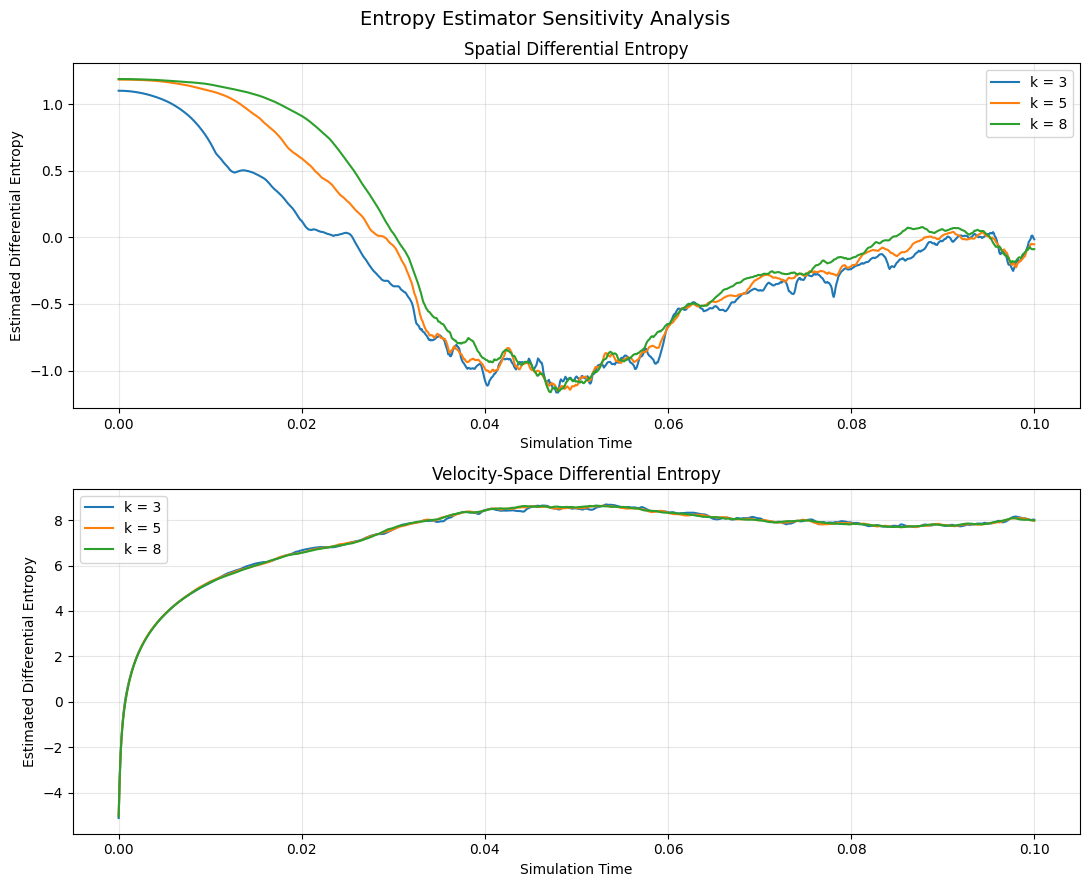

In [8]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 2: APPLIED STATISTICAL MECHANICS
# CELL 7: ENTROPY MEASUREMENT VALIDATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.special import digamma

# ---------- CHECK ORIGINAL HISTOGRAM RESOLUTION ----------

initial_counts, _, _ = np.histogram2d(
    velocity_history[0, :, 0],
    velocity_history[0, :, 1],
    bins=(velocity_edges, velocity_edges)
)

initial_occupied_cells = np.count_nonzero(initial_counts)

print("ORIGINAL HISTOGRAM DIAGNOSTIC")
print("--------------------------------")
print("Velocity grid:", BINS, "x", BINS)
print("Initially occupied velocity cells:", initial_occupied_cells)
print("Total particles:", N)
print("Original initial velocity entropy:", velocity_entropy[0])

# ---------- DIFFERENTIAL ENTROPY ESTIMATOR ----------

def knn_differential_entropy(data, k=5):

    data = np.asarray(data, dtype=float)

    n, dimensions = data.shape

    if dimensions != 2:
        raise ValueError("This estimator expects 2D data.")

    if not (1 <= k < n):
        raise ValueError("Invalid number of neighbors.")

    tree = cKDTree(data)

    distances, _ = tree.query(
        data,
        k=k + 1
    )

    # Distance to the kth neighbor, excluding itself
    neighbor_radius = distances[:, -1]

    if np.any(neighbor_radius <= 0):
        raise ValueError("Duplicate points detected.")

    # Area of a unit circle in two dimensions
    unit_ball_area = np.pi

    entropy = (
        digamma(n)
        - digamma(k)
        + np.log(unit_ball_area)
        + dimensions * np.mean(np.log(neighbor_radius))
    )

    return entropy

# ---------- COMPARE NEIGHBOR COUNTS ----------

neighbor_choices = [3, 5, 8]

spatial_knn_results = {}
velocity_knn_results = {}

for k in neighbor_choices:

    spatial_values = np.zeros(STEPS + 1)
    velocity_values = np.zeros(STEPS + 1)

    for step in range(STEPS + 1):

        spatial_values[step] = knn_differential_entropy(
            position_history[step],
            k=k
        )

        velocity_values[step] = knn_differential_entropy(
            velocity_history[step],
            k=k
        )

    spatial_knn_results[k] = spatial_values
    velocity_knn_results[k] = velocity_values

# ---------- PRINT RESULTS ----------

print("\nKNN DIFFERENTIAL ENTROPY RESULTS")
print("--------------------------------")

for k in neighbor_choices:

    sp = spatial_knn_results[k]
    ve = velocity_knn_results[k]

    print(f"\nk = {k}")
    print(f"Initial spatial entropy  : {sp[0]:.6f}")
    print(f"Final spatial entropy    : {sp[-1]:.6f}")
    print(f"Spatial entropy change   : {sp[-1] - sp[0]:+.6f}")

    print(f"Initial velocity entropy : {ve[0]:.6f}")
    print(f"Final velocity entropy   : {ve[-1]:.6f}")
    print(f"Velocity entropy change  : {ve[-1] - ve[0]:+.6f}")

# ---------- PLOT ESTIMATOR SENSITIVITY ----------

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

for k in neighbor_choices:

    axes[0].plot(
        time_array,
        spatial_knn_results[k],
        label=f"k = {k}",
        linewidth=1.5
    )

    axes[1].plot(
        time_array,
        velocity_knn_results[k],
        label=f"k = {k}",
        linewidth=1.5
    )

axes[0].set_title("Spatial Differential Entropy")
axes[0].set_xlabel("Simulation Time")
axes[0].set_ylabel("Estimated Differential Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Velocity-Space Differential Entropy")
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("Estimated Differential Entropy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Entropy Estimator Sensitivity Analysis",
    fontsize=14
)

plt.tight_layout()
plt.show()



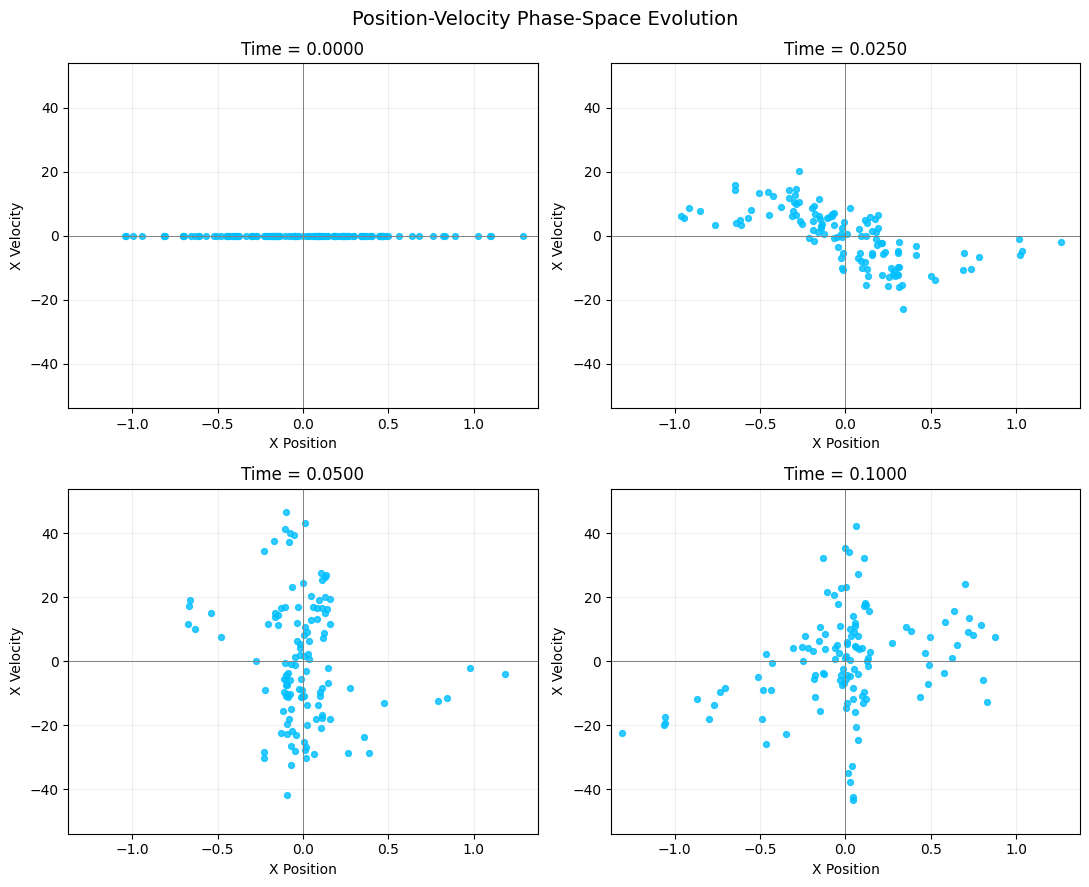

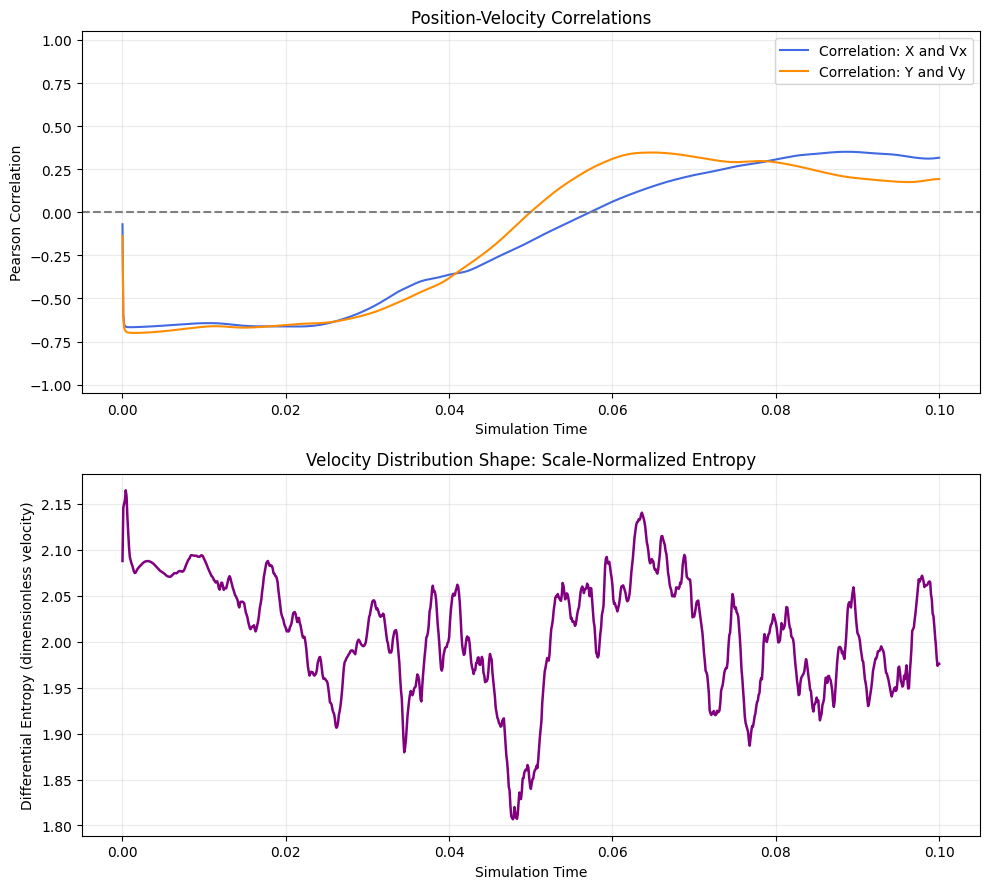

PHASE-SPACE AND ENTROPY-SCALING RESULTS
Initial X-Vx correlation: -0.069503
Final X-Vx correlation  : +0.316880

Initial Y-Vy correlation: -0.137867
Final Y-Vy correlation  : +0.193179

Velocity entropy change (k=5): +12.991910
Contribution from velocity scaling: +13.103811
Scale-normalized entropy change: -0.111901


In [9]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 3: PHASE-SPACE STATISTICAL MECHANICS
# CELL 8: POSITION-VELOCITY CORRELATIONS
#         AND VELOCITY ENTROPY SCALING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- PHASE-SPACE SNAPSHOTS ----------

snapshot_steps = [0, STEPS // 4, STEPS // 2, STEPS]

x_limit = 1.05 * np.max(
    np.abs(position_history[:, :, 0])
)

vx_limit = 1.05 * np.max(
    np.abs(velocity_history[:, :, 0])
)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, step in zip(axes.flat, snapshot_steps):

    x = position_history[step, :, 0]
    vx = velocity_history[step, :, 0]

    ax.scatter(
        x, vx,
        s=18,
        color="deepskyblue",
        alpha=0.8
    )

    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)

    ax.set_xlim(-x_limit, x_limit)
    ax.set_ylim(-vx_limit, vx_limit)

    ax.set_title(f"Time = {time_array[step]:.4f}")
    ax.set_xlabel("X Position")
    ax.set_ylabel("X Velocity")
    ax.grid(alpha=0.2)

plt.suptitle(
    "Position-Velocity Phase-Space Evolution",
    fontsize=14
)
plt.tight_layout()
plt.show()


# ---------- POSITION-VELOCITY CORRELATION ----------

correlation_x = np.zeros(STEPS + 1)
correlation_y = np.zeros(STEPS + 1)

for step in range(STEPS + 1):

    p = position_history[step]
    v = velocity_history[step]

    correlation_x[step] = np.corrcoef(
        p[:, 0], v[:, 0]
    )[0, 1]

    correlation_y[step] = np.corrcoef(
        p[:, 1], v[:, 1]
    )[0, 1]


# ---------- REMOVE VELOCITY-SCALE EFFECT ----------

rms_speed_history = np.sqrt(
    np.mean(
        np.sum(velocity_history**2, axis=2),
        axis=1
    )
)

# Differential entropy in two velocity dimensions:
# h(V / a) = h(V) - 2*ln(a)

normalized_velocity_entropy = (
    velocity_knn_results[5]
    - 2.0 * np.log(rms_speed_history)
)

scale_contribution = 2.0 * np.log(
    rms_speed_history[-1] / rms_speed_history[0]
)

# ---------- PLOT CORRELATION AND SHAPE ENTROPY ----------

fig, axes = plt.subplots(2, 1, figsize=(10, 9))

axes[0].plot(
    time_array, correlation_x,
    label="Correlation: X and Vx",
    color="royalblue"
)

axes[0].plot(
    time_array, correlation_y,
    label="Correlation: Y and Vy",
    color="darkorange"
)

axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_ylabel("Pearson Correlation")
axes[0].set_xlabel("Simulation Time")
axes[0].set_title("Position-Velocity Correlations")
axes[0].set_ylim(-1.05, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    time_array,
    normalized_velocity_entropy,
    color="purple",
    linewidth=1.8
)

axes[1].set_title(
    "Velocity Distribution Shape: Scale-Normalized Entropy"
)
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("Differential Entropy (dimensionless velocity)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ---------- FINAL RESULTS ----------

assert np.all(np.isfinite(correlation_x))
assert np.all(np.isfinite(correlation_y))
assert np.all(np.isfinite(normalized_velocity_entropy))

print("PHASE-SPACE AND ENTROPY-SCALING RESULTS")
print("=" * 55)

print(f"Initial X-Vx correlation: {correlation_x[0]:+.6f}")
print(f"Final X-Vx correlation  : {correlation_x[-1]:+.6f}")

print(f"\nInitial Y-Vy correlation: {correlation_y[0]:+.6f}")
print(f"Final Y-Vy correlation  : {correlation_y[-1]:+.6f}")

print(
    "\nVelocity entropy change (k=5):",
    f"{velocity_knn_results[5][-1] - velocity_knn_results[5][0]:+.6f}"
)

print(
    "Contribution from velocity scaling:",
    f"{scale_contribution:+.6f}"
)

print(
    "Scale-normalized entropy change:",
    f"{normalized_velocity_entropy[-1] - normalized_velocity_entropy[0]:+.6f}"
)



VIRIAL THEOREM AND GRAVITATIONAL COLLAPSE
Initial virial ratio : 0.000004
Final virial ratio   : 1.212384

MAXIMUM CONCENTRATION
----------------------------------------
Time              : 0.052700
Minimum RMS radius: 0.327562
Virial ratio      : 1.565108

RADIUS COMPARISON
----------------------------------------
Initial RMS radius: 0.635464
Final RMS radius  : 0.550938


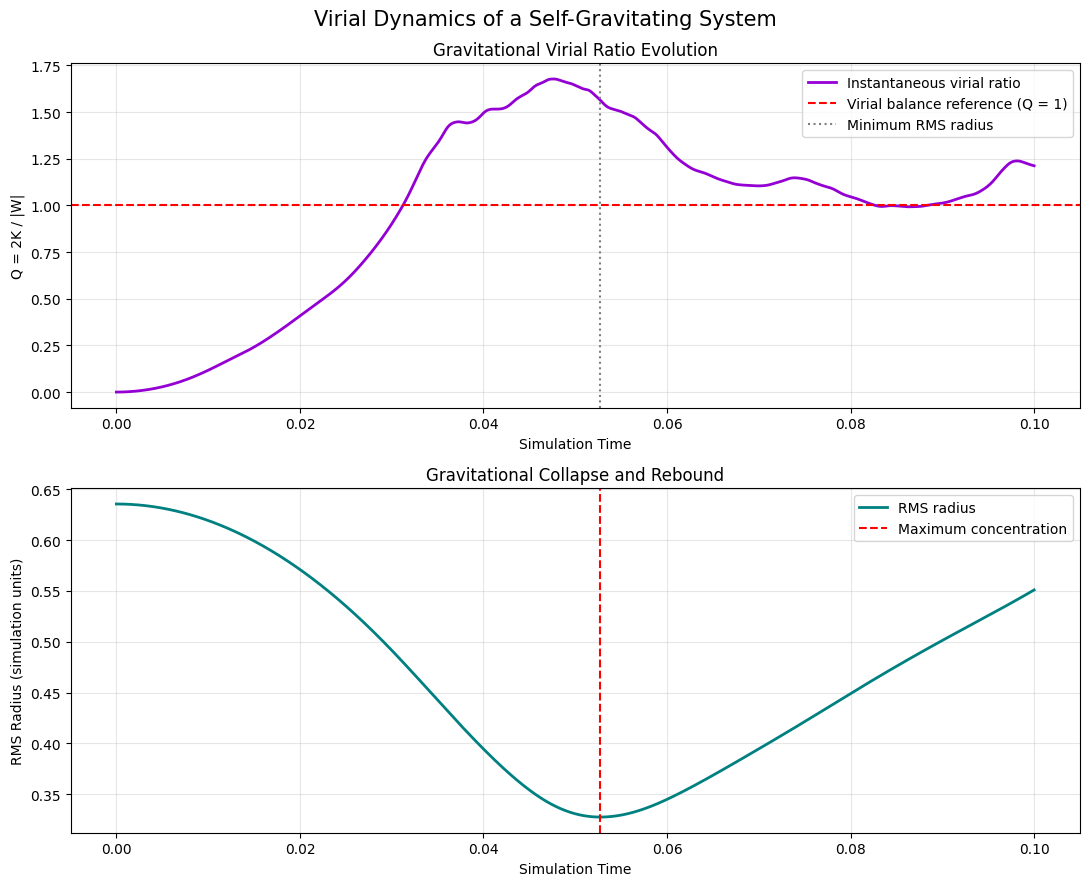

In [10]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 3: GRAVITATIONAL THERMODYNAMICS
# CELL 9: VIRIAL THEOREM AND COLLAPSE DIAGNOSTICS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- STORAGE ----------

virial_kinetic = np.zeros(STEPS + 1)
virial_W = np.zeros(STEPS + 1)
virial_ratio = np.zeros(STEPS + 1)
rms_radius = np.zeros(STEPS + 1)

# ---------- CALCULATE VIRIAL QUANTITIES ----------

for step in range(STEPS + 1):

    pos = position_history[step]
    vel = velocity_history[step]

    # Work in the center-of-mass reference frame
    center_pos = np.average(
        pos, axis=0, weights=masses
    )

    center_vel = np.average(
        vel, axis=0, weights=masses
    )

    r = pos - center_pos
    v = vel - center_vel

    # Internal kinetic energy
    K = 0.5 * np.sum(
        masses[:, None] * v**2
    )

    # Gravitational acceleration using our original model
    a = compute_accelerations(
        pos, masses, G, EPSILON
    )

    # Exact virial term for our softened force law
    W = np.sum(
        masses[:, None] * r * a
    )

    # Radius of the particle cloud
    R = np.sqrt(
        np.sum(masses[:, None] * r**2)
        / np.sum(masses)
    )

    virial_kinetic[step] = K
    virial_W[step] = W
    rms_radius[step] = R

    virial_ratio[step] = 2 * K / abs(W)


# ---------- VALIDATION ----------

assert np.all(np.isfinite(virial_ratio))
assert np.all(np.isfinite(rms_radius))
assert np.all(virial_W < 0)

# ---------- IMPORTANT TIME POINTS ----------

collapse_step = np.argmin(rms_radius)

print("VIRIAL THEOREM AND GRAVITATIONAL COLLAPSE")
print("=" * 58)

print(f"Initial virial ratio : {virial_ratio[0]:.6f}")
print(f"Final virial ratio   : {virial_ratio[-1]:.6f}")

print("\nMAXIMUM CONCENTRATION")
print("-" * 40)
print(f"Time              : {time_array[collapse_step]:.6f}")
print(f"Minimum RMS radius: {rms_radius[collapse_step]:.6f}")
print(f"Virial ratio      : {virial_ratio[collapse_step]:.6f}")

print("\nRADIUS COMPARISON")
print("-" * 40)
print(f"Initial RMS radius: {rms_radius[0]:.6f}")
print(f"Final RMS radius  : {rms_radius[-1]:.6f}")


# ---------- GRAPH 1: VIRIAL RATIO ----------

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

axes[0].plot(
    time_array,
    virial_ratio,
    color="darkviolet",
    linewidth=2,
    label="Instantaneous virial ratio"
)

axes[0].axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Virial balance reference (Q = 1)"
)

axes[0].axvline(
    time_array[collapse_step],
    color="gray",
    linestyle=":",
    label="Minimum RMS radius"
)

axes[0].set_title("Gravitational Virial Ratio Evolution")
axes[0].set_xlabel("Simulation Time")
axes[0].set_ylabel("Q = 2K / |W|")
axes[0].legend()
axes[0].grid(alpha=0.3)


# ---------- GRAPH 2: COLLAPSE AND REBOUND ----------

axes[1].plot(
    time_array,
    rms_radius,
    color="teal",
    linewidth=2,
    label="RMS radius"
)

axes[1].axvline(
    time_array[collapse_step],
    color="red",
    linestyle="--",
    label="Maximum concentration"
)

axes[1].set_title("Gravitational Collapse and Rebound")
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("RMS Radius (simulation units)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Virial Dynamics of a Self-Gravitating System",
    fontsize=15
)

plt.tight_layout()
plt.show()



Running refinement = 1...
Running refinement = 2...
Running refinement = 4...

NUMERICAL CONVERGENCE RESULTS
Time step     Max error (%)     Final RMS radius    Minimum RMS radius
----------------------------------------------------------------------
0.0001000     0.00579135        0.55093794          0.32758247
0.0000500     0.00144658        0.55093427          0.32758141
0.0000250     0.00036157        0.55093336          0.32758115

ENERGY ERROR REDUCTION
---------------------------------------------
Refinement 1 to 2: 4.0035x smaller error
Refinement 2 to 4: 4.0009x smaller error


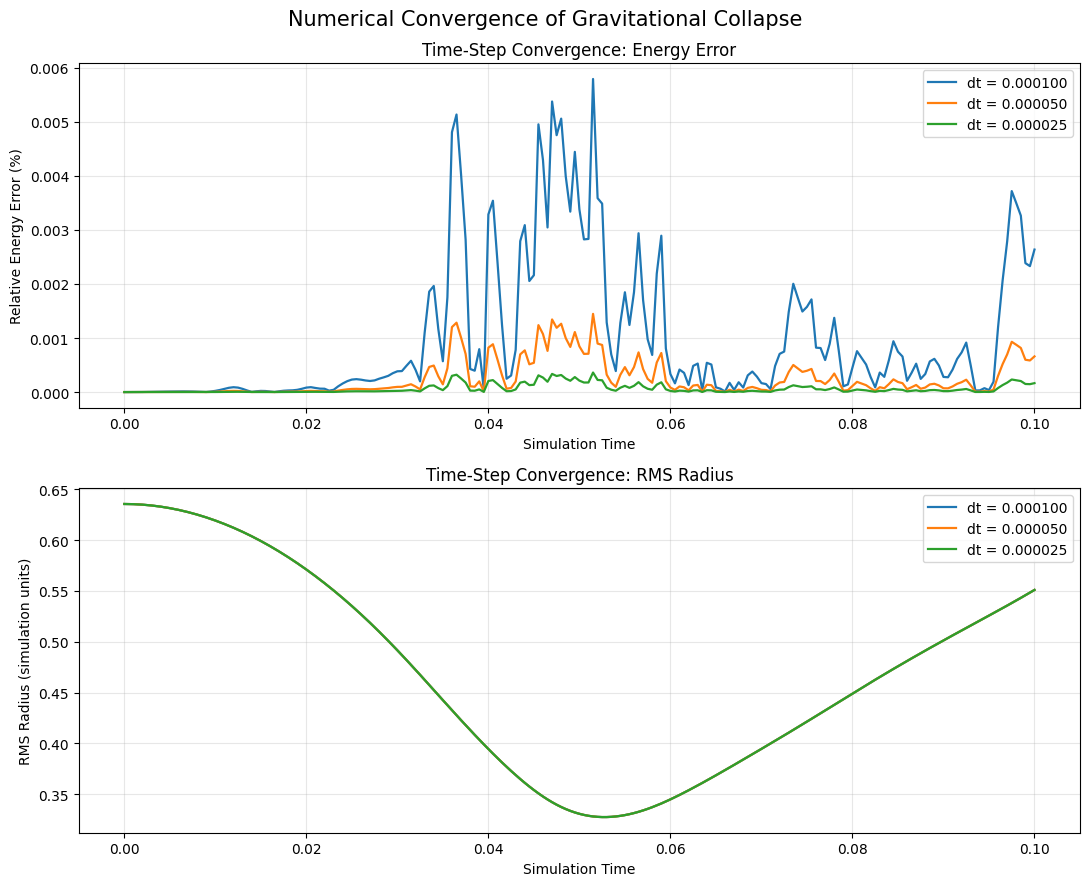

In [11]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 3: NUMERICAL VALIDATION
# CELL 10: TIME-STEP CONVERGENCE TEST
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- COMMON PHYSICAL SIMULATION TIME ----------

SAMPLES = 200

assert STEPS % SAMPLES == 0

conv_time = np.linspace(
    0.0, STEPS * DT, SAMPLES + 1
)

reference_energy = sum(
    calculate_energy(
        initial_positions,
        initial_velocities
    )
)

# ---------- INDEPENDENT RE-RUN FUNCTION ----------

def run_convergence_test(refinement):

    dt_test = DT / refinement
    steps_test = STEPS * refinement

    sample_every = steps_test // SAMPLES

    p = initial_positions.copy()
    v = initial_velocities.copy()

    a = compute_accelerations(
        p, masses, G, EPSILON
    )

    energy_error = np.zeros(SAMPLES + 1)
    radius_history = np.zeros(SAMPLES + 1)

    radius_history[0] = np.sqrt(
        np.average(
            np.sum(
                (p - np.average(p, axis=0, weights=masses))**2,
                axis=1
            ),
            weights=masses
        )
    )

    # ---------- VELOCITY VERLET ----------

    for step in range(1, steps_test + 1):

        p = p + v * dt_test + 0.5 * a * dt_test**2

        a_new = compute_accelerations(
            p, masses, G, EPSILON
        )

        v = v + 0.5 * (a + a_new) * dt_test

        a = a_new

        # Measure at the same physical times in all runs
        if step % sample_every == 0:

            index = step // sample_every

            K, U = calculate_energy(p, v)
            current_energy = K + U

            energy_error[index] = (
                abs(current_energy - reference_energy)
                / abs(reference_energy)
            ) * 100

            center = np.average(
                p, axis=0, weights=masses
            )

            radius_history[index] = np.sqrt(
                np.average(
                    np.sum((p - center)**2, axis=1),
                    weights=masses
                )
            )

    return {
        "dt": dt_test,
        "steps": steps_test,
        "energy_error": energy_error,
        "radius": radius_history,
        "maximum_error": np.max(energy_error),
        "final_radius": radius_history[-1],
        "minimum_radius": np.min(radius_history)
    }


# ---------- RUN THREE RESOLUTIONS ----------

convergence_results = {}

for refinement in [1, 2, 4]:

    print(f"Running refinement = {refinement}...")

    convergence_results[refinement] = (
        run_convergence_test(refinement)
    )


# ---------- PRINT COMPARISON ----------

print("\nNUMERICAL CONVERGENCE RESULTS")
print("=" * 70)

print(
    f"{'Time step':<14}"
    f"{'Max error (%)':<18}"
    f"{'Final RMS radius':<20}"
    f"{'Minimum RMS radius'}"
)

print("-" * 70)

for refinement, result in convergence_results.items():

    print(
        f"{result['dt']:<14.7f}"
        f"{result['maximum_error']:<18.8f}"
        f"{result['final_radius']:<20.8f}"
        f"{result['minimum_radius']:.8f}"
    )


# ---------- ERROR REDUCTION FACTORS ----------

print("\nENERGY ERROR REDUCTION")
print("-" * 45)

for coarse, fine in [(1, 2), (2, 4)]:

    ratio = (
        convergence_results[coarse]["maximum_error"]
        / convergence_results[fine]["maximum_error"]
    )

    print(
        f"Refinement {coarse} to {fine}: "
        f"{ratio:.4f}x smaller error"
    )


# ---------- VISUAL COMPARISON ----------

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

for refinement, result in convergence_results.items():

    label = f"dt = {result['dt']:.6f}"

    axes[0].plot(
        conv_time,
        result["energy_error"],
        label=label,
        linewidth=1.6
    )

    axes[1].plot(
        conv_time,
        result["radius"],
        label=label,
        linewidth=1.6
    )

axes[0].set_title("Time-Step Convergence: Energy Error")
axes[0].set_xlabel("Simulation Time")
axes[0].set_ylabel("Relative Energy Error (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Time-Step Convergence: RMS Radius")
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("RMS Radius (simulation units)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Numerical Convergence of Gravitational Collapse",
    fontsize=15
)

plt.tight_layout()
plt.show()



Original initial virial ratio: 0.00000399
Running Original cold...
Running Q = 0.10...
Running Q = 0.50...
Running Q = 1.00...
Running Q = 1.50...

INITIAL CONDITION SENSITIVITY ANALYSIS
Experiment       Initial Q    Min radius     Time of min    Final radius   Max error (%)
----------------------------------------------------------------------------------------
Original cold    0.000004     0.327582       0.052500       0.550938       0.005791
Q = 0.10         0.100000     0.346295       0.049000       0.584994       0.016571
Q = 0.50         0.500000     0.452335       0.052500       0.606632       0.005767
Q = 1.00         1.000000     0.600831       0.034500       0.847702       0.001584
Q = 1.50         1.500000     0.625858       0.010500       1.142060       0.001977


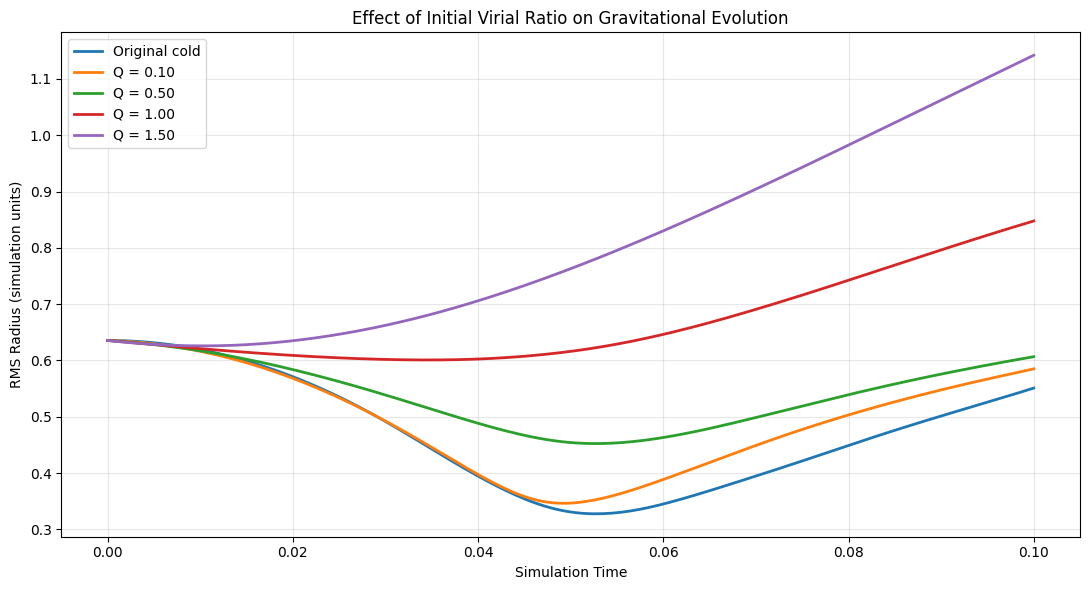

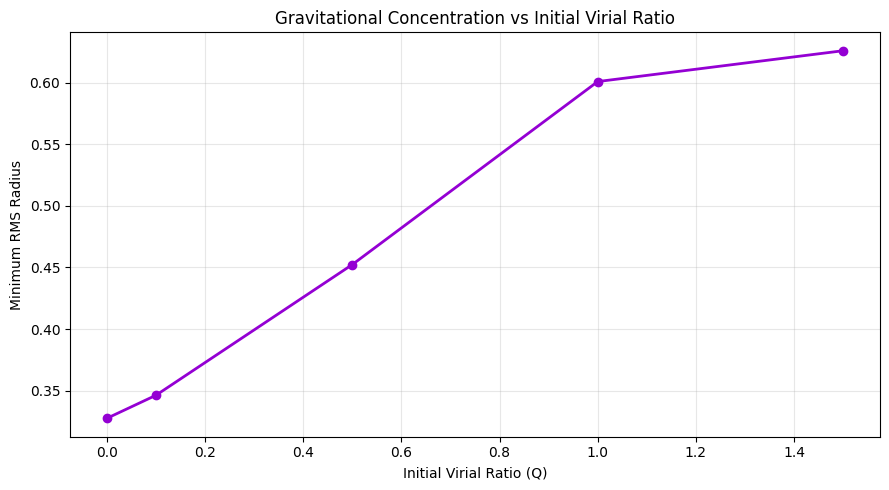

In [12]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 4: CONTROLLED GRAVITATIONAL EXPERIMENTS
# CELL 11: INITIAL VIRIAL RATIO PARAMETER SWEEP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- ORIGINAL INITIAL VIRIAL RATIO ----------

p0 = initial_positions.copy()
v0 = initial_velocities.copy()

a0 = compute_accelerations(
    p0, masses, G, EPSILON
)

K0 = 0.5 * np.sum(masses[:, None] * v0**2)

W0 = np.sum(
    masses[:, None] * p0 * a0
)

Q0 = 2 * K0 / abs(W0)

print(f"Original initial virial ratio: {Q0:.8f}")

# ---------- EXPERIMENTAL CONDITIONS ----------

Q_CASES = {
    "Original cold": Q0,
    "Q = 0.10": 0.10,
    "Q = 0.50": 0.50,
    "Q = 1.00": 1.00,
    "Q = 1.50": 1.50
}

SAMPLE_EVERY = 5

sweep_results = {}

# ---------- INDEPENDENT SIMULATION FUNCTION ----------

def run_virial_experiment(target_Q):

    p = p0.copy()

    # Change velocity magnitude to achieve target virial ratio
    velocity_scale = np.sqrt(target_Q / Q0)
    v = v0.copy() * velocity_scale

    a = compute_accelerations(
        p, masses, G, EPSILON
    )

    initial_energy = sum(calculate_energy(p, v))

    times = []
    radii = []
    errors = []

    for step in range(STEPS + 1):

        if step % SAMPLE_EVERY == 0:

            center = np.average(
                p, axis=0, weights=masses
            )

            radius = np.sqrt(
                np.average(
                    np.sum((p - center)**2, axis=1),
                    weights=masses
                )
            )

            current_energy = sum(
                calculate_energy(p, v)
            )

            error = (
                abs(current_energy - initial_energy)
                / max(abs(initial_energy), 1e-12)
            ) * 100

            times.append(step * DT)
            radii.append(radius)
            errors.append(error)

        if step == STEPS:
            break

        # Velocity Verlet integration
        p = p + v * DT + 0.5 * a * DT**2

        a_new = compute_accelerations(
            p, masses, G, EPSILON
        )

        v = v + 0.5 * (a + a_new) * DT

        a = a_new

    times = np.array(times)
    radii = np.array(radii)
    errors = np.array(errors)

    assert np.all(np.isfinite(radii))
    assert np.all(np.isfinite(errors))

    return {
        "Q": target_Q,
        "time": times,
        "radius": radii,
        "error": errors,
        "minimum_radius": np.min(radii),
        "collapse_time": times[np.argmin(radii)],
        "final_radius": radii[-1],
        "maximum_error": np.max(errors)
    }


# ---------- RUN ALL EXPERIMENTS ----------

for name, target_Q in Q_CASES.items():

    print(f"Running {name}...")

    sweep_results[name] = run_virial_experiment(
        target_Q
    )


# ---------- RESULTS TABLE ----------

print("\nINITIAL CONDITION SENSITIVITY ANALYSIS")
print("=" * 88)

print(
    f"{'Experiment':<17}"
    f"{'Initial Q':<13}"
    f"{'Min radius':<15}"
    f"{'Time of min':<15}"
    f"{'Final radius':<15}"
    f"{'Max error (%)'}"
)

print("-" * 88)

for name, result in sweep_results.items():

    print(
        f"{name:<17}"
        f"{result['Q']:<13.6f}"
        f"{result['minimum_radius']:<15.6f}"
        f"{result['collapse_time']:<15.6f}"
        f"{result['final_radius']:<15.6f}"
        f"{result['maximum_error']:.6f}"
    )


# ---------- GRAPH 1: RADIUS EVOLUTION ----------

plt.figure(figsize=(11, 6))

for name, result in sweep_results.items():

    plt.plot(
        result["time"],
        result["radius"],
        linewidth=2,
        label=name
    )

plt.title("Effect of Initial Virial Ratio on Gravitational Evolution")
plt.xlabel("Simulation Time")
plt.ylabel("RMS Radius (simulation units)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- GRAPH 2: MINIMUM RADIUS VS INITIAL Q ----------

q_values = [
    result["Q"]
    for result in sweep_results.values()
]

minimum_radii = [
    result["minimum_radius"]
    for result in sweep_results.values()
]

plt.figure(figsize=(9, 5))

plt.plot(
    q_values,
    minimum_radii,
    marker="o",
    linewidth=2,
    color="darkviolet"
)

plt.title("Gravitational Concentration vs Initial Virial Ratio")
plt.xlabel("Initial Virial Ratio (Q)")
plt.ylabel("Minimum RMS Radius")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



Running Gaussian cloud seed 11...
Running Gaussian cloud seed 23...
Running Gaussian cloud seed 37...
Running Gaussian cloud seed 41...
Running Gaussian cloud seed 53...

MULTI-SEED GRAVITATIONAL RESULTS
Initial Q      Mean min R/R0      Std deviation      Max energy error (%)
------------------------------------------------------------------------
0.000004       0.478413           0.026397           0.009910
0.100000       0.507162           0.017182           0.008469
0.500000       0.718320           0.057090           0.002622
1.000000       0.980369           0.031373           0.001469
1.500000       0.995264           0.008286           0.001537


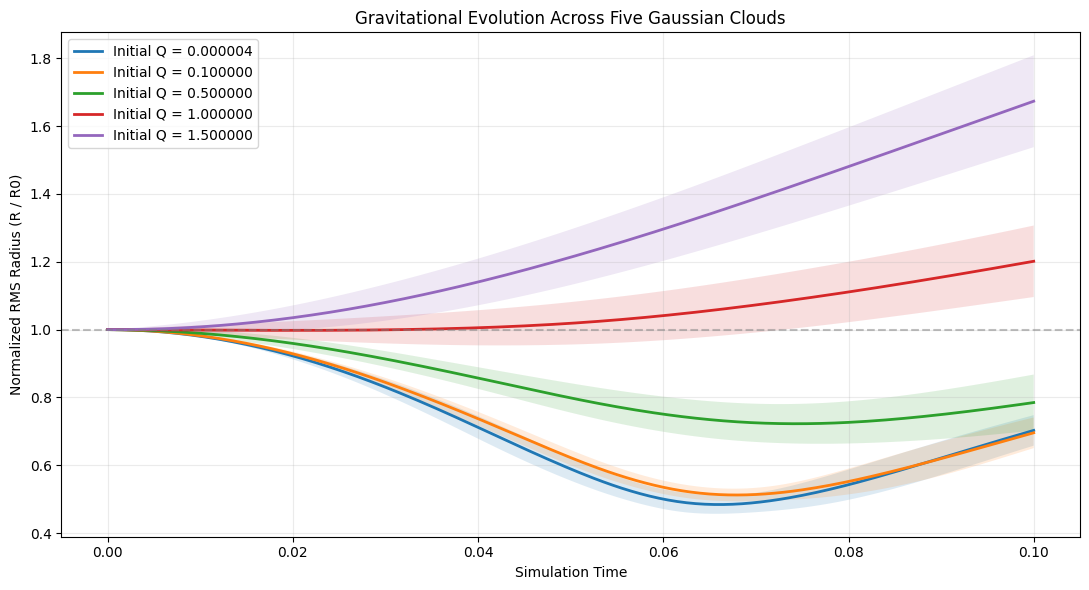

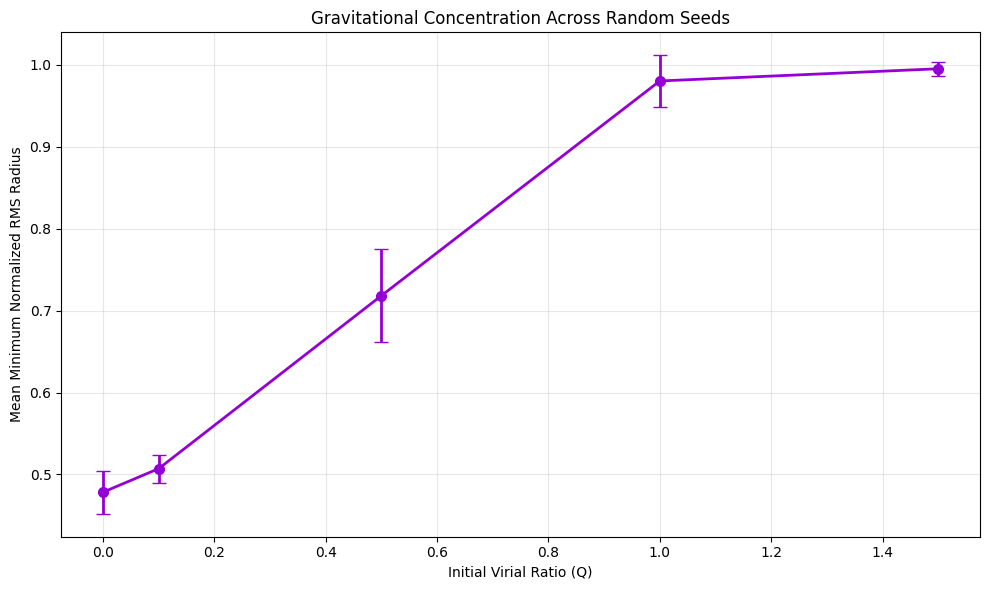


NUMERICAL VALIDATION
---------------------------------------------
Total simulations: 25
Maximum energy error: 0.009910%
Energy accuracy: PRELIMINARY PASS


In [13]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 4: REPRODUCIBILITY AND UNCERTAINTY
# CELL 12: MULTI-SEED GRAVITATIONAL PARAMETER STUDY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- EXPERIMENT SETTINGS ----------

SEED_LIST = [11, 23, 37, 41, 53]
Q_LEVELS = np.array([4e-6, 0.10, 0.50, 1.00, 1.50])

SAMPLE_EVERY = 5
sample_steps = np.arange(0, STEPS + 1, SAMPLE_EVERY)
sample_time = sample_steps * DT

# ---------- GENERATE INDEPENDENT GAUSSIAN CLOUDS ----------

def seeded_start(seed):

    local_rng = np.random.default_rng(seed)

    p = local_rng.normal(
        0.0, POSITION_SIGMA, size=(N, 2)
    )

    v = local_rng.normal(
        0.0, VELOCITY_SIGMA, size=(N, 2)
    )

    p -= np.average(p, axis=0, weights=masses)
    v -= np.average(v, axis=0, weights=masses)

    return p, v


# ---------- RUN ONE CONTROLLED EXPERIMENT ----------

def integrate_case(p_start, v_start, target_q):

    p = p_start.copy()

    a = compute_accelerations(
        p, masses, G, EPSILON
    )

    W0 = np.sum(masses[:, None] * p * a)
    K0 = 0.5 * np.sum(masses[:, None] * v_start**2)

    # Set the exact intended initial virial ratio
    velocity_scale = np.sqrt(
        target_q * abs(W0) / (2.0 * K0)
    )

    v = v_start.copy() * velocity_scale

    initial_energy = sum(calculate_energy(p, v))

    radii = np.empty(len(sample_steps))
    energy_errors = np.empty(len(sample_steps))

    for step in range(STEPS + 1):

        if step % SAMPLE_EVERY == 0:

            index = step // SAMPLE_EVERY

            center = np.average(
                p, axis=0, weights=masses
            )

            radii[index] = np.sqrt(
                np.average(
                    np.sum((p - center)**2, axis=1),
                    weights=masses
                )
            )

            current_energy = sum(calculate_energy(p, v))

            energy_errors[index] = (
                abs(current_energy - initial_energy)
                / abs(initial_energy)
            ) * 100

        if step == STEPS:
            break

        # Velocity Verlet integration
        p = p + v * DT + 0.5 * a * DT**2

        a_new = compute_accelerations(
            p, masses, G, EPSILON
        )

        v = v + 0.5 * (a + a_new) * DT

        a = a_new

    return radii, energy_errors


# ---------- STORE ALL 25 SIMULATIONS ----------

all_radius = np.empty((
    len(Q_LEVELS),
    len(SEED_LIST),
    len(sample_steps)
))

all_energy_error = np.empty((
    len(Q_LEVELS),
    len(SEED_LIST)
))

for seed_index, seed in enumerate(SEED_LIST):

    print(f"Running Gaussian cloud seed {seed}...")

    p0_seed, v0_seed = seeded_start(seed)

    for q_index, target_q in enumerate(Q_LEVELS):

        radius, error = integrate_case(
            p0_seed, v0_seed, target_q
        )

        # Normalize by each cloud's initial radius
        all_radius[q_index, seed_index] = (
            radius / radius[0]
        )

        all_energy_error[q_index, seed_index] = (
            np.max(error)
        )


# ---------- STATISTICAL ANALYSIS ----------

mean_radius = np.mean(all_radius, axis=1)
std_radius = np.std(all_radius, axis=1, ddof=1)

minimum_ratios = np.min(all_radius, axis=2)

mean_minimum = np.mean(minimum_ratios, axis=1)
std_minimum = np.std(minimum_ratios, axis=1, ddof=1)

# ---------- DISPLAY NUMERICAL RESULTS ----------

print("\nMULTI-SEED GRAVITATIONAL RESULTS")
print("=" * 72)

print(
    f"{'Initial Q':<15}"
    f"{'Mean min R/R0':<19}"
    f"{'Std deviation':<19}"
    f"{'Max energy error (%)'}"
)

print("-" * 72)

for i, q in enumerate(Q_LEVELS):

    print(
        f"{q:<15.6f}"
        f"{mean_minimum[i]:<19.6f}"
        f"{std_minimum[i]:<19.6f}"
        f"{np.max(all_energy_error[i]):.6f}"
    )


# ---------- GRAPH 1: MEAN EVOLUTION WITH VARIATION ----------

plt.figure(figsize=(11, 6))

for i, q in enumerate(Q_LEVELS):

    label = f"Initial Q = {q:.6f}"

    plt.plot(
        sample_time,
        mean_radius[i],
        linewidth=2,
        label=label
    )

    plt.fill_between(
        sample_time,
        mean_radius[i] - std_radius[i],
        mean_radius[i] + std_radius[i],
        alpha=0.15
    )

plt.axhline(1, color="gray", linestyle="--", alpha=0.5)

plt.title("Gravitational Evolution Across Five Gaussian Clouds")
plt.xlabel("Simulation Time")
plt.ylabel("Normalized RMS Radius (R / R0)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ---------- GRAPH 2: INITIAL CONDITION SENSITIVITY ----------

plt.figure(figsize=(10, 6))

plt.errorbar(
    Q_LEVELS,
    mean_minimum,
    yerr=std_minimum,
    fmt="o-",
    capsize=5,
    linewidth=2,
    markersize=7,
    color="darkviolet"
)

plt.title("Gravitational Concentration Across Random Seeds")
plt.xlabel("Initial Virial Ratio (Q)")
plt.ylabel("Mean Minimum Normalized RMS Radius")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- NUMERICAL VALIDATION ----------

assert np.all(np.isfinite(all_radius))
assert np.all(np.isfinite(all_energy_error))

maximum_error = np.max(all_energy_error)

print("\nNUMERICAL VALIDATION")
print("-" * 45)
print("Total simulations:", len(SEED_LIST) * len(Q_LEVELS))
print("Maximum energy error:", f"{maximum_error:.6f}%")

if maximum_error < 0.1:
    print("Energy accuracy: PRELIMINARY PASS")
else:
    print("Energy accuracy: REQUIRES INVESTIGATION")



Running particle count N = 60...
Running particle count N = 120...
Running particle count N = 240...

PARTICLE-COUNT SENSITIVITY RESULTS
Total system mass: 120.0
Target initial virial ratio: 0.5
Softening length: 0.05
Number of random seeds: 5

-------------------------------------------------------------------------
N         Mass/particle     Mean min R/R0     Std dev      Max error %
-------------------------------------------------------------------------
60        2.000000          0.798773          0.048672     0.005015
120       1.000000          0.718326          0.057085     0.002622
240       0.500000          0.713732          0.048160     0.001894


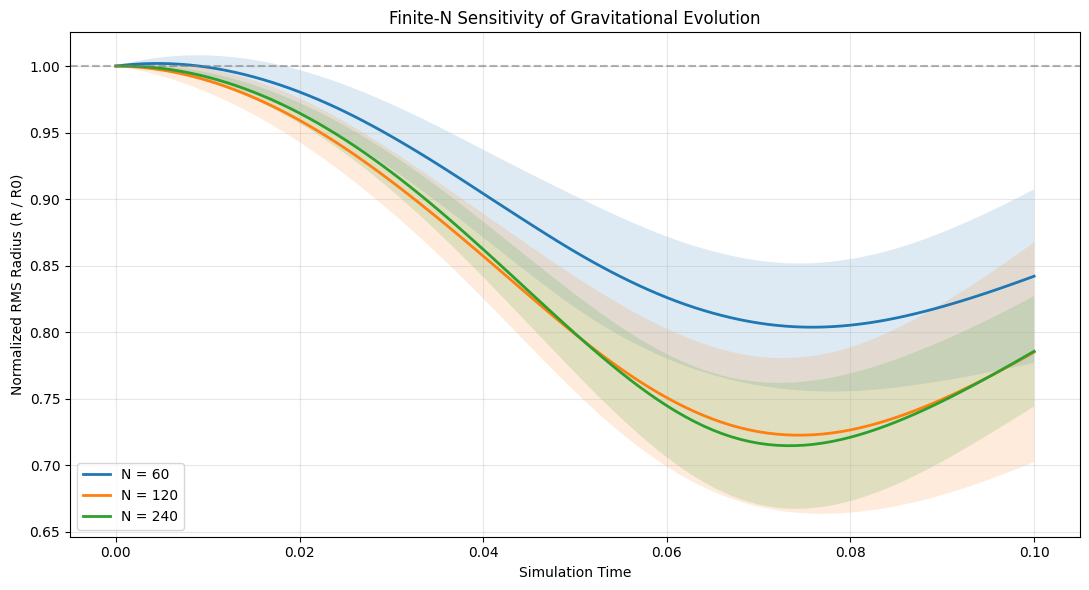

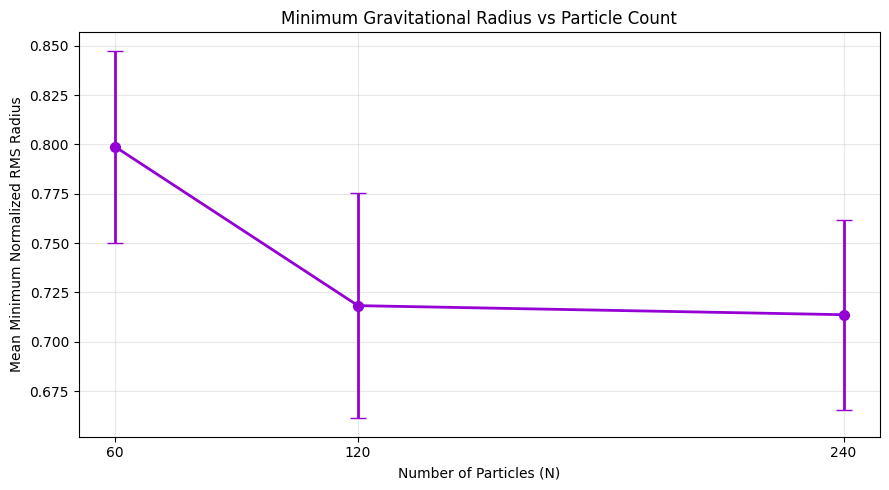


NUMERICAL VALIDATION
---------------------------------------------
Total simulations: 15
Maximum sampled energy error: 0.005015%
Energy accuracy: PRELIMINARY PASS


In [14]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 4: MODEL VALIDATION
# CELL 13: PARTICLE-COUNT SENSITIVITY STUDY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- EXPERIMENT PARAMETERS ----------

PARTICLE_COUNTS = [60, 120, 240]
TEST_SEEDS = [11, 23, 37, 41, 53]

TOTAL_MASS = float(np.sum(masses))
TARGET_Q = 0.50

SAVE_EVERY = 10

test_times = np.arange(
    0, STEPS + 1, SAVE_EVERY
) * DT

# ---------- MASS-AWARE GRAVITATIONAL ACCELERATION ----------

def acceleration_variable_N(pos, particle_masses):

    diff = pos[:, None, :] - pos[None, :, :]

    dist2 = np.sum(diff**2, axis=2) + EPSILON**2

    inv_dist3 = dist2**(-1.5)

    np.fill_diagonal(inv_dist3, 0.0)

    acceleration = -G * np.sum(
        diff
        * inv_dist3[:, :, None]
        * particle_masses[None, :, None],
        axis=1
    )

    return acceleration


# ---------- ENERGY FOR ANY PARTICLE COUNT ----------

def energy_variable_N(pos, vel, particle_masses):

    n = len(pos)

    kinetic = 0.5 * np.sum(
        particle_masses[:, None] * vel**2
    )

    i, j = np.triu_indices(n, k=1)

    separation = pos[i] - pos[j]

    softened_distance = np.sqrt(
        np.sum(separation**2, axis=1) + EPSILON**2
    )

    potential = -G * np.sum(
        particle_masses[i]
        * particle_masses[j]
        / softened_distance
    )

    return kinetic + potential


# ---------- RUN ONE PARTICLE-COUNT EXPERIMENT ----------

def simulate_particle_count(n, seed):

    local_rng = np.random.default_rng(seed)

    particle_masses = np.full(
        n, TOTAL_MASS / n
    )

    # Gaussian initial positions and velocities
    pos = local_rng.normal(
        0.0, POSITION_SIGMA, size=(n, 2)
    )

    vel = local_rng.normal(
        0.0, VELOCITY_SIGMA, size=(n, 2)
    )

    # Remove center-of-mass position and velocity
    pos -= np.average(
        pos, axis=0, weights=particle_masses
    )

    vel -= np.average(
        vel, axis=0, weights=particle_masses
    )

    # Initial gravitational acceleration
    a = acceleration_variable_N(
        pos, particle_masses
    )

    # Initial kinetic energy
    K0 = 0.5 * np.sum(
        particle_masses[:, None] * vel**2
    )

    # Virial term for softened gravity
    W0 = np.sum(
        particle_masses[:, None] * pos * a
    )

    # Set the same initial virial ratio for every case
    velocity_factor = np.sqrt(
        TARGET_Q * abs(W0) / (2.0 * K0)
    )

    vel *= velocity_factor

    initial_energy = energy_variable_N(
        pos, vel, particle_masses
    )

    number_of_samples = len(test_times)

    radius_values = np.zeros(number_of_samples)
    energy_errors = np.zeros(number_of_samples)

    for step in range(STEPS + 1):

        if step % SAVE_EVERY == 0:

            index = step // SAVE_EVERY

            center = np.average(
                pos, axis=0, weights=particle_masses
            )

            rms_radius = np.sqrt(
                np.average(
                    np.sum((pos - center)**2, axis=1),
                    weights=particle_masses
                )
            )

            current_energy = energy_variable_N(
                pos, vel, particle_masses
            )

            radius_values[index] = rms_radius

            energy_errors[index] = (
                abs(current_energy - initial_energy)
                / abs(initial_energy)
            ) * 100

        if step == STEPS:
            break

        # Velocity Verlet method
        pos = (
            pos
            + vel * DT
            + 0.5 * a * DT**2
        )

        a_new = acceleration_variable_N(
            pos, particle_masses
        )

        vel = (
            vel
            + 0.5 * (a + a_new) * DT
        )

        a = a_new

    # Normalize by the initial cloud size
    normalized_radius = (
        radius_values / radius_values[0]
    )

    assert np.all(np.isfinite(normalized_radius))
    assert np.all(np.isfinite(energy_errors))

    return normalized_radius, np.max(energy_errors)


# ---------- RUN ALL EXPERIMENTS ----------

particle_results = {}

for n in PARTICLE_COUNTS:

    print(f"Running particle count N = {n}...")

    trajectories = []
    maximum_errors = []

    for seed in TEST_SEEDS:

        radius, error = simulate_particle_count(
            n, seed
        )

        trajectories.append(radius)
        maximum_errors.append(error)

    trajectories = np.array(trajectories)

    minimum_values = np.min(
        trajectories, axis=1
    )

    particle_results[n] = {
        "mean_curve": np.mean(trajectories, axis=0),
        "std_curve": np.std(
            trajectories, axis=0, ddof=1
        ),
        "mean_minimum": np.mean(minimum_values),
        "std_minimum": np.std(
            minimum_values, ddof=1
        ),
        "maximum_error": np.max(maximum_errors)
    }


# ---------- PRINT RESULTS ----------

print("\nPARTICLE-COUNT SENSITIVITY RESULTS")
print("=" * 73)

print(f"Total system mass: {TOTAL_MASS}")
print(f"Target initial virial ratio: {TARGET_Q}")
print(f"Softening length: {EPSILON}")
print(f"Number of random seeds: {len(TEST_SEEDS)}")

print("\n" + "-" * 73)

print(
    f"{'N':<10}"
    f"{'Mass/particle':<18}"
    f"{'Mean min R/R0':<18}"
    f"{'Std dev':<13}"
    f"{'Max error %'}"
)

print("-" * 73)

for n in PARTICLE_COUNTS:

    result = particle_results[n]

    print(
        f"{n:<10}"
        f"{TOTAL_MASS/n:<18.6f}"
        f"{result['mean_minimum']:<18.6f}"
        f"{result['std_minimum']:<13.6f}"
        f"{result['maximum_error']:.6f}"
    )


# ---------- GRAPH 1: PARTICLE-COUNT COMPARISON ----------

plt.figure(figsize=(11, 6))

for n in PARTICLE_COUNTS:

    result = particle_results[n]

    mean = result["mean_curve"]
    std = result["std_curve"]

    plt.plot(
        test_times,
        mean,
        linewidth=2,
        label=f"N = {n}"
    )

    plt.fill_between(
        test_times,
        mean - std,
        mean + std,
        alpha=0.15
    )

plt.axhline(
    1.0, color="gray", linestyle="--", alpha=0.6
)

plt.title("Finite-N Sensitivity of Gravitational Evolution")
plt.xlabel("Simulation Time")
plt.ylabel("Normalized RMS Radius (R / R0)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- GRAPH 2: MINIMUM RADIUS SENSITIVITY ----------

mean_values = [
    particle_results[n]["mean_minimum"]
    for n in PARTICLE_COUNTS
]

std_values = [
    particle_results[n]["std_minimum"]
    for n in PARTICLE_COUNTS
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    PARTICLE_COUNTS,
    mean_values,
    yerr=std_values,
    fmt="o-",
    color="darkviolet",
    linewidth=2,
    markersize=7,
    capsize=6
)

plt.title("Minimum Gravitational Radius vs Particle Count")
plt.xlabel("Number of Particles (N)")
plt.ylabel("Mean Minimum Normalized RMS Radius")
plt.xticks(PARTICLE_COUNTS)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- FINAL VALIDATION ----------

all_errors = [
    particle_results[n]["maximum_error"]
    for n in PARTICLE_COUNTS
]

print("\nNUMERICAL VALIDATION")
print("-" * 45)

print("Total simulations:",
      len(PARTICLE_COUNTS) * len(TEST_SEEDS))

print("Maximum sampled energy error:",
      f"{max(all_errors):.6f}%")

if max(all_errors) < 0.1:
    print("Energy accuracy: PRELIMINARY PASS")
else:
    print("Energy accuracy: NEEDS FURTHER TESTING")



Running softening length = 0.025...
Running softening length = 0.05...
Running softening length = 0.1...

GRAVITATIONAL SOFTENING SENSITIVITY
Softening      Mean min R/R0       Std deviation     Max error (%)
-----------------------------------------------------------------
0.0250         0.731745            0.058830          0.009357
0.0500         0.718326            0.057085          0.002622
0.1000         0.706062            0.053102          0.000795


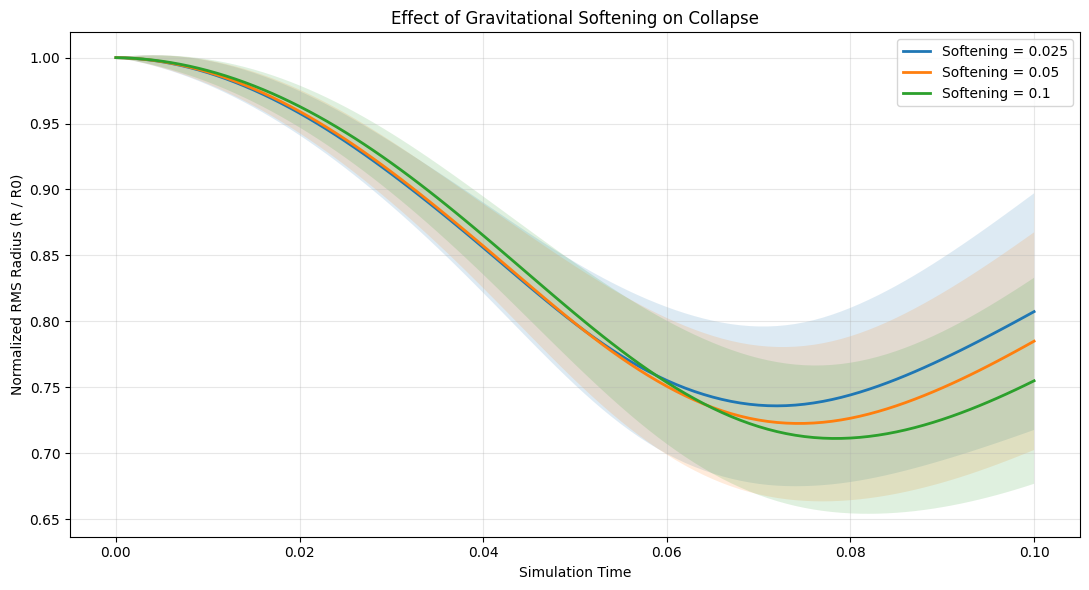

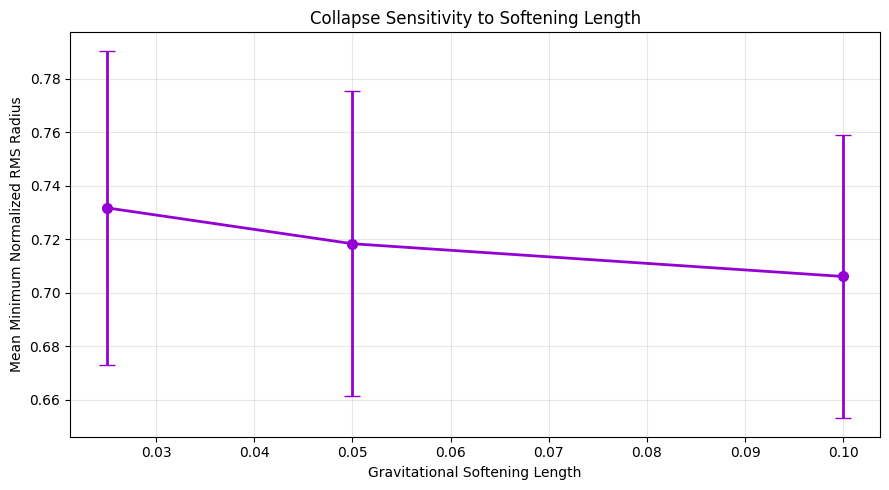


NUMERICAL VALIDATION
---------------------------------------------
Total simulations: 15
Maximum sampled energy error: 0.009357%
Energy accuracy: PRELIMINARY PASS


In [15]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 4: MODEL VALIDATION
# CELL 14: GRAVITATIONAL SOFTENING SENSITIVITY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- EXPERIMENT SETTINGS ----------

SOFTENING_VALUES = [0.025, 0.05, 0.10]
SOFTENING_SEEDS = [11, 23, 37, 41, 53]

TARGET_Q_SOFT = 0.50
N_SOFT = 120
TOTAL_MASS_SOFT = float(np.sum(masses))
SAVE_EVERY_SOFT = 10

soft_times = np.arange(
    0, STEPS + 1, SAVE_EVERY_SOFT
) * DT

soft_masses = np.full(
    N_SOFT, TOTAL_MASS_SOFT / N_SOFT
)

# ---------- GRAVITATIONAL ACCELERATION ----------

def softening_acceleration(pos, epsilon):

    diff = pos[:, None, :] - pos[None, :, :]

    dist2 = np.sum(diff**2, axis=2) + epsilon**2

    inv_dist3 = dist2**(-1.5)

    np.fill_diagonal(inv_dist3, 0.0)

    acceleration = -G * np.sum(
        diff * inv_dist3[:, :, None]
        * soft_masses[None, :, None],
        axis=1
    )

    return acceleration


# ---------- TOTAL ENERGY ----------

def softening_energy(pos, vel, epsilon):

    kinetic = 0.5 * np.sum(
        soft_masses[:, None] * vel**2
    )

    i, j = np.triu_indices(N_SOFT, k=1)

    separation = pos[i] - pos[j]

    distance = np.sqrt(
        np.sum(separation**2, axis=1) + epsilon**2
    )

    potential = -G * np.sum(
        soft_masses[i] * soft_masses[j] / distance
    )

    return kinetic + potential


# ---------- RUN ONE SIMULATION ----------

def run_softening_experiment(epsilon, seed):

    local_rng = np.random.default_rng(seed)

    p = local_rng.normal(
        0.0, POSITION_SIGMA, size=(N_SOFT, 2)
    )

    v = local_rng.normal(
        0.0, VELOCITY_SIGMA, size=(N_SOFT, 2)
    )

    # Remove center-of-mass motion
    p -= np.average(p, axis=0, weights=soft_masses)
    v -= np.average(v, axis=0, weights=soft_masses)

    a = softening_acceleration(p, epsilon)

    K0 = 0.5 * np.sum(
        soft_masses[:, None] * v**2
    )

    W0 = np.sum(
        soft_masses[:, None] * p * a
    )

    # Maintain the same initial virial ratio
    velocity_factor = np.sqrt(
        TARGET_Q_SOFT * abs(W0) / (2.0 * K0)
    )

    v *= velocity_factor

    initial_energy = softening_energy(p, v, epsilon)

    radii = []
    energy_errors = []

    # ---------- VELOCITY VERLET EVOLUTION ----------

    for step in range(STEPS + 1):

        if step % SAVE_EVERY_SOFT == 0:

            center = np.average(
                p, axis=0, weights=soft_masses
            )

            radius = np.sqrt(
                np.average(
                    np.sum((p - center)**2, axis=1),
                    weights=soft_masses
                )
            )

            energy = softening_energy(p, v, epsilon)

            error = (
                abs(energy - initial_energy)
                / abs(initial_energy)
            ) * 100

            radii.append(radius)
            energy_errors.append(error)

        if step == STEPS:
            break

        p = p + v * DT + 0.5 * a * DT**2

        a_new = softening_acceleration(p, epsilon)

        v = v + 0.5 * (a + a_new) * DT

        a = a_new

    radii = np.array(radii)
    energy_errors = np.array(energy_errors)

    normalized_radius = radii / radii[0]

    assert np.all(np.isfinite(normalized_radius))
    assert np.all(np.isfinite(energy_errors))

    return normalized_radius, np.max(energy_errors)


# ---------- RUN ALL 15 SIMULATIONS ----------

softening_results = {}

for epsilon in SOFTENING_VALUES:

    print(f"Running softening length = {epsilon}...")

    trajectories = []
    errors = []

    for seed in SOFTENING_SEEDS:

        radius, error = run_softening_experiment(
            epsilon, seed
        )

        trajectories.append(radius)
        errors.append(error)

    trajectories = np.array(trajectories)

    minimum_radii = np.min(trajectories, axis=1)

    softening_results[epsilon] = {
        "mean_curve": np.mean(trajectories, axis=0),
        "std_curve": np.std(
            trajectories, axis=0, ddof=1
        ),
        "mean_minimum": np.mean(minimum_radii),
        "std_minimum": np.std(
            minimum_radii, ddof=1
        ),
        "max_error": np.max(errors)
    }


# ---------- PRINT RESULTS ----------

print("\nGRAVITATIONAL SOFTENING SENSITIVITY")
print("=" * 65)

print(
    f"{'Softening':<15}"
    f"{'Mean min R/R0':<20}"
    f"{'Std deviation':<18}"
    f"{'Max error (%)'}"
)

print("-" * 65)

for epsilon, result in softening_results.items():

    print(
        f"{epsilon:<15.4f}"
        f"{result['mean_minimum']:<20.6f}"
        f"{result['std_minimum']:<18.6f}"
        f"{result['max_error']:.6f}"
    )


# ---------- GRAPH 1: RADIUS EVOLUTION ----------

plt.figure(figsize=(11, 6))

for epsilon, result in softening_results.items():

    mean = result["mean_curve"]
    std = result["std_curve"]

    plt.plot(
        soft_times,
        mean,
        linewidth=2,
        label=f"Softening = {epsilon}"
    )

    plt.fill_between(
        soft_times,
        mean - std,
        mean + std,
        alpha=0.15
    )

plt.title("Effect of Gravitational Softening on Collapse")
plt.xlabel("Simulation Time")
plt.ylabel("Normalized RMS Radius (R / R0)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- GRAPH 2: MINIMUM RADIUS ----------

mean_minima = [
    softening_results[e]["mean_minimum"]
    for e in SOFTENING_VALUES
]

std_minima = [
    softening_results[e]["std_minimum"]
    for e in SOFTENING_VALUES
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    SOFTENING_VALUES,
    mean_minima,
    yerr=std_minima,
    fmt="o-",
    color="darkviolet",
    capsize=6,
    linewidth=2,
    markersize=7
)

plt.title("Collapse Sensitivity to Softening Length")
plt.xlabel("Gravitational Softening Length")
plt.ylabel("Mean Minimum Normalized RMS Radius")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---------- FINAL VALIDATION ----------

max_error = max(
    result["max_error"]
    for result in softening_results.values()
)

print("\nNUMERICAL VALIDATION")
print("-" * 45)

print("Total simulations:", 15)
print("Maximum sampled energy error:",
      f"{max_error:.6f}%")

if max_error < 0.1:
    print("Energy accuracy: PRELIMINARY PASS")
else:
    print("Energy accuracy: NEEDS INVESTIGATION")



THREE-DIMENSIONAL N-BODY SIMULATION
Particles: 120
Spatial dimensions: 3
Total mass: 120.0
Initial virial ratio: 0.5

ENERGY CONSERVATION
---------------------------------------------
Initial total energy: -12727.673360
Final total energy: -12727.664739
Maximum energy error: 0.001398%

GRAVITATIONAL CONCENTRATION
---------------------------------------------
Initial RMS radius: 0.816587
Final RMS radius: 0.492436
Minimum RMS radius: 0.492222
Final center of mass: [-1.91629120e-16 -4.76470715e-17 -3.95516953e-17]


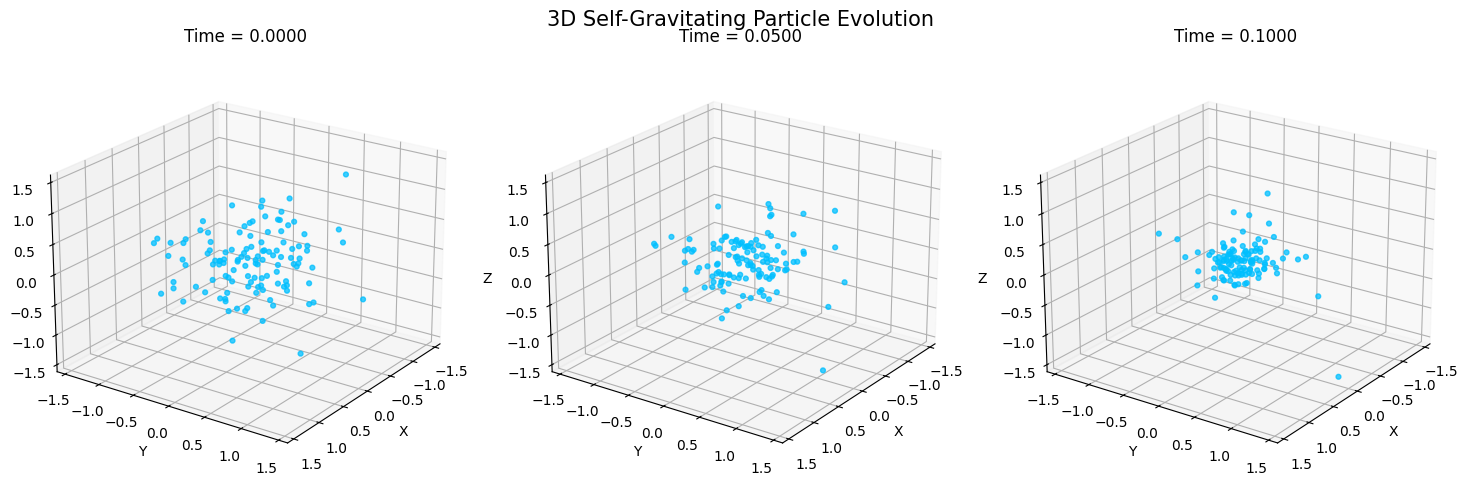

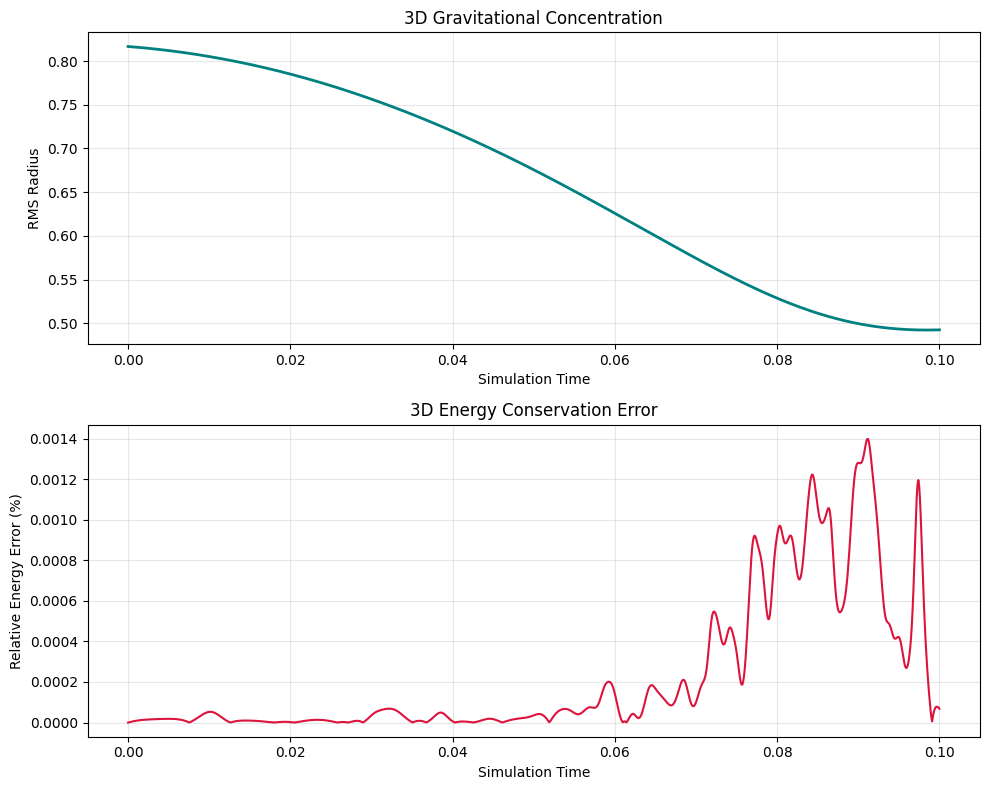

In [16]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 5: THREE-DIMENSIONAL GRAVITATIONAL DYNAMICS
# CELL 15: 3D N-BODY SIMULATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- 3D SIMULATION PARAMETERS ----------

N3 = N
G3 = G
DT3 = DT
STEPS3 = STEPS
EPSILON3 = EPSILON

TOTAL_MASS3 = float(np.sum(masses))
MASS3 = np.full(N3, TOTAL_MASS3 / N3)

TARGET_Q3 = 0.50
SEED3 = 42

rng3 = np.random.default_rng(SEED3)

# ---------- INITIAL GAUSSIAN POSITIONS ----------

pos3 = rng3.normal(
    0.0,
    POSITION_SIGMA,
    size=(N3, 3)
)

# ---------- INITIAL GAUSSIAN VELOCITIES ----------

vel3 = rng3.normal(
    0.0,
    VELOCITY_SIGMA,
    size=(N3, 3)
)

# Remove center-of-mass position and velocity
pos3 -= np.average(
    pos3, axis=0, weights=MASS3
)

vel3 -= np.average(
    vel3, axis=0, weights=MASS3
)

# ---------- 3D GRAVITATIONAL ACCELERATION ----------

def acceleration_3d(pos):

    diff = pos[:, None, :] - pos[None, :, :]

    dist2 = np.sum(
        diff**2, axis=2
    ) + EPSILON3**2

    inv_dist3 = dist2**(-1.5)

    np.fill_diagonal(inv_dist3, 0.0)

    acceleration = -G3 * np.sum(
        diff
        * inv_dist3[:, :, None]
        * MASS3[None, :, None],
        axis=1
    )

    return acceleration


# ---------- 3D ENERGY CALCULATION ----------

pair_i, pair_j = np.triu_indices(N3, k=1)

def energy_3d(pos, vel):

    kinetic = 0.5 * np.sum(
        MASS3[:, None] * vel**2
    )

    separation = pos[pair_i] - pos[pair_j]

    distance = np.sqrt(
        np.sum(separation**2, axis=1)
        + EPSILON3**2
    )

    potential = -G3 * np.sum(
        MASS3[pair_i]
        * MASS3[pair_j]
        / distance
    )

    return kinetic, potential


# ---------- SET INITIAL VIRIAL RATIO ----------

a3 = acceleration_3d(pos3)

K3_initial = 0.5 * np.sum(
    MASS3[:, None] * vel3**2
)

W3_initial = np.sum(
    MASS3[:, None] * pos3 * a3
)

velocity_factor3 = np.sqrt(
    TARGET_Q3 * abs(W3_initial)
    / (2.0 * K3_initial)
)

vel3 *= velocity_factor3

# Save the starting state
initial_pos3 = pos3.copy()
initial_vel3 = vel3.copy()

K3_initial, U3_initial = energy_3d(pos3, vel3)
E3_initial = K3_initial + U3_initial

# ---------- STORE FULL 3D EVOLUTION ----------

position_history3 = np.zeros(
    (STEPS3 + 1, N3, 3)
)

velocity_history3 = np.zeros(
    (STEPS3 + 1, N3, 3)
)

energy_history3 = np.zeros(STEPS3 + 1)
radius_history3 = np.zeros(STEPS3 + 1)

# ---------- VELOCITY VERLET INTEGRATION ----------

for step in range(STEPS3 + 1):

    position_history3[step] = pos3
    velocity_history3[step] = vel3

    K_current, U_current = energy_3d(
        pos3, vel3
    )

    energy_history3[step] = K_current + U_current

    center3 = np.average(
        pos3, axis=0, weights=MASS3
    )

    radius_history3[step] = np.sqrt(
        np.average(
            np.sum((pos3 - center3)**2, axis=1),
            weights=MASS3
        )
    )

    if step == STEPS3:
        break

    # Update positions
    pos3 = (
        pos3
        + vel3 * DT3
        + 0.5 * a3 * DT3**2
    )

    # New gravitational accelerations
    a3_new = acceleration_3d(pos3)

    # Update velocities
    vel3 = (
        vel3
        + 0.5 * (a3 + a3_new) * DT3
    )

    a3 = a3_new


# ---------- NUMERICAL VALIDATION ----------

time3 = np.arange(STEPS3 + 1) * DT3

energy_error3 = (
    np.abs(energy_history3 - E3_initial)
    / abs(E3_initial)
) * 100

final_com3 = np.average(
    position_history3[-1],
    axis=0,
    weights=MASS3
)

assert np.all(np.isfinite(position_history3))
assert np.all(np.isfinite(velocity_history3))
assert np.all(np.isfinite(energy_history3))

print("THREE-DIMENSIONAL N-BODY SIMULATION")
print("=" * 55)

print("Particles:", N3)
print("Spatial dimensions: 3")
print("Total mass:", TOTAL_MASS3)
print("Initial virial ratio:", TARGET_Q3)

print("\nENERGY CONSERVATION")
print("-" * 45)

print(f"Initial total energy: {E3_initial:.6f}")
print(f"Final total energy: {energy_history3[-1]:.6f}")
print(f"Maximum energy error: {np.max(energy_error3):.6f}%")

print("\nGRAVITATIONAL CONCENTRATION")
print("-" * 45)

print(f"Initial RMS radius: {radius_history3[0]:.6f}")
print(f"Final RMS radius: {radius_history3[-1]:.6f}")
print(f"Minimum RMS radius: {np.min(radius_history3):.6f}")
print("Final center of mass:", final_com3)


# ---------- 3D PARTICLE SNAPSHOTS ----------

fig = plt.figure(figsize=(15, 5))

snapshot3 = [0, STEPS3 // 2, STEPS3]

axis_limit3 = 1.1 * np.max(
    np.abs(position_history3)
)

for index, step in enumerate(snapshot3):

    ax = fig.add_subplot(
        1, 3, index + 1,
        projection="3d"
    )

    p = position_history3[step]

    ax.scatter(
        p[:, 0],
        p[:, 1],
        p[:, 2],
        s=12,
        alpha=0.75,
        color="deepskyblue"
    )

    ax.set_title(f"Time = {time3[step]:.4f}")

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.set_xlim(-axis_limit3, axis_limit3)
    ax.set_ylim(-axis_limit3, axis_limit3)
    ax.set_zlim(-axis_limit3, axis_limit3)

    ax.view_init(elev=22, azim=35)

plt.suptitle(
    "3D Self-Gravitating Particle Evolution",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ---------- RADIUS AND ENERGY ERROR ----------

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(
    time3,
    radius_history3,
    color="teal",
    linewidth=2
)

axes[0].set_title("3D Gravitational Concentration")
axes[0].set_xlabel("Simulation Time")
axes[0].set_ylabel("RMS Radius")
axes[0].grid(alpha=0.3)

axes[1].plot(
    time3,
    energy_error3,
    color="crimson"
)

axes[1].set_title("3D Energy Conservation Error")
axes[1].set_xlabel("Simulation Time")
axes[1].set_ylabel("Relative Energy Error (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



3D GRAVITATIONAL THERMODYNAMICS
Initial kinetic energy: 4174.973980
Final kinetic energy  : 21306.966738

KINETIC TEMPERATURE PROXY
---------------------------------------------
Initial T: 23.389210
Final T  : 119.366760
Temperature ratio (final/initial): 5.103497

VIRIAL DIAGNOSTICS
---------------------------------------------
Initial Q: 0.500000
Final Q  : 1.307268

MAXIMUM CONCENTRATION
---------------------------------------------
Time: 0.098500
RMS radius: 0.492222
Kinetic temperature: 123.022610
Virial ratio: 1.328709


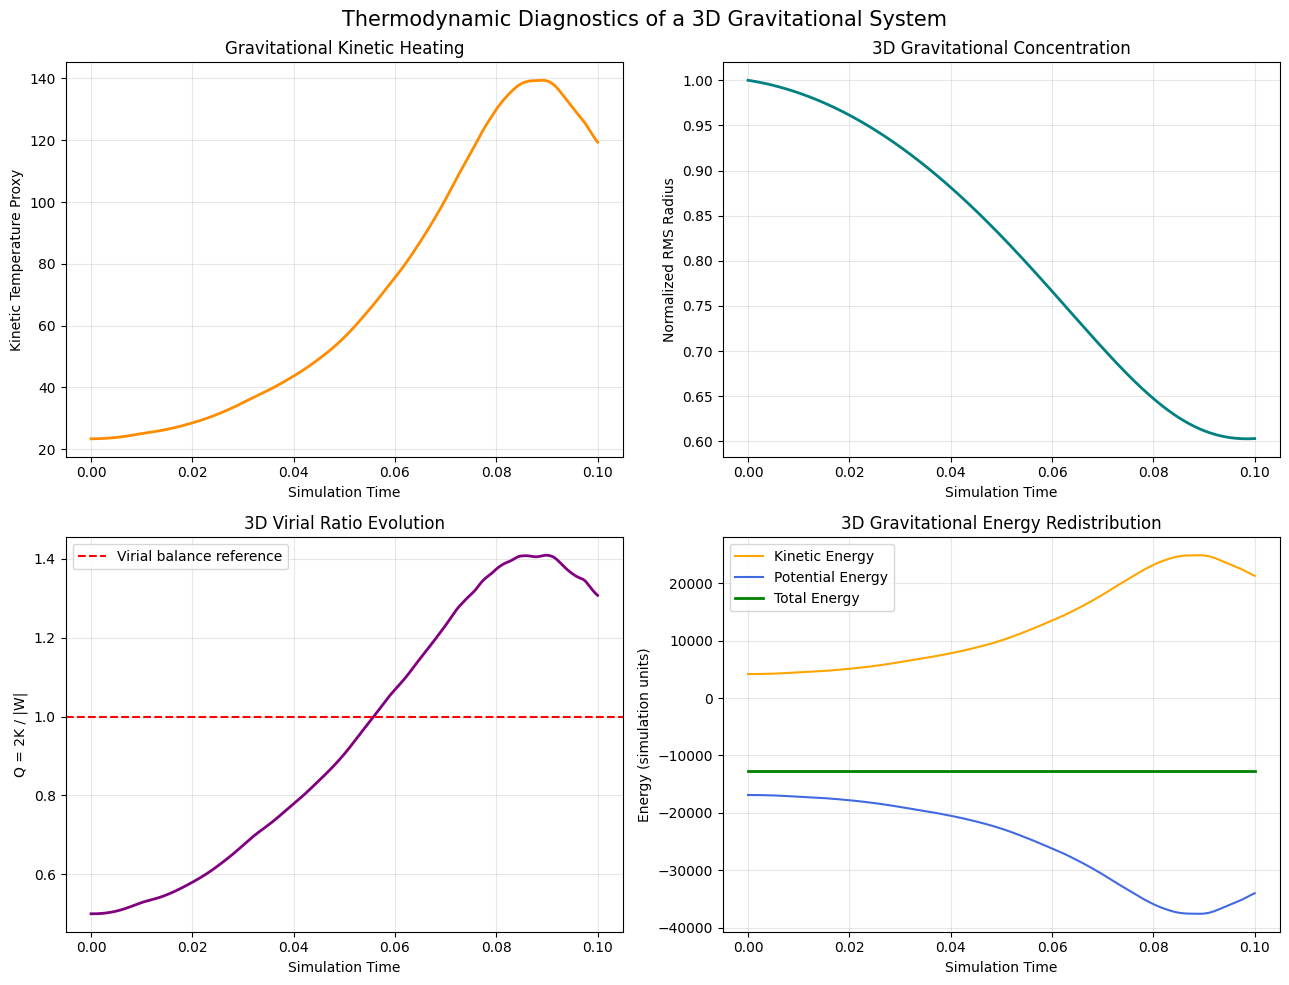

In [17]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 6: GRAVITATIONAL THERMODYNAMICS
# CELL 16: 3D KINETIC TEMPERATURE AND VIRIAL ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- THERMODYNAMIC ARRAYS ----------

kinetic3 = np.zeros(STEPS3 + 1)
potential3 = np.zeros(STEPS3 + 1)

temperature3 = np.zeros(STEPS3 + 1)
virial_W3 = np.zeros(STEPS3 + 1)
virial_ratio3 = np.zeros(STEPS3 + 1)

# Boltzmann constant in dimensionless simulation units
KB3 = 1.0

# Remove 3 center-of-mass velocity degrees of freedom
DOF3 = 3 * (N3 - 1)

# ---------- CALCULATE PHYSICAL QUANTITIES ----------

for step in range(STEPS3 + 1):

    pos = position_history3[step]
    vel = velocity_history3[step]

    center_pos = np.average(
        pos, axis=0, weights=MASS3
    )

    center_vel = np.average(
        vel, axis=0, weights=MASS3
    )

    relative_pos = pos - center_pos
    relative_vel = vel - center_vel

    # Kinetic energy in center-of-mass frame
    K = 0.5 * np.sum(
        MASS3[:, None] * relative_vel**2
    )

    # Gravitational energy from existing function
    _, U = energy_3d(pos, vel)

    # Exact virial term for softened gravity
    accel = acceleration_3d(pos)

    W = np.sum(
        MASS3[:, None] * relative_pos * accel
    )

    # Kinetic temperature proxy
    T = 2.0 * K / (DOF3 * KB3)

    kinetic3[step] = K
    potential3[step] = U
    temperature3[step] = T

    virial_W3[step] = W
    virial_ratio3[step] = 2.0 * K / abs(W)


# ---------- VALIDATION ----------

assert np.all(np.isfinite(temperature3))
assert np.all(np.isfinite(virial_ratio3))
assert np.all(temperature3 >= 0)
assert np.all(virial_W3 < 0)

collapse_index3 = np.argmin(radius_history3)

# ---------- PRINT NUMERICAL RESULTS ----------

print("3D GRAVITATIONAL THERMODYNAMICS")
print("=" * 55)

print(f"Initial kinetic energy: {kinetic3[0]:.6f}")
print(f"Final kinetic energy  : {kinetic3[-1]:.6f}")

print("\nKINETIC TEMPERATURE PROXY")
print("-" * 45)

print(f"Initial T: {temperature3[0]:.6f}")
print(f"Final T  : {temperature3[-1]:.6f}")

print(
    "Temperature ratio (final/initial):",
    f"{temperature3[-1]/temperature3[0]:.6f}"
)

print("\nVIRIAL DIAGNOSTICS")
print("-" * 45)

print(f"Initial Q: {virial_ratio3[0]:.6f}")
print(f"Final Q  : {virial_ratio3[-1]:.6f}")

print("\nMAXIMUM CONCENTRATION")
print("-" * 45)

print(
    "Time:",
    f"{time3[collapse_index3]:.6f}"
)

print(
    "RMS radius:",
    f"{radius_history3[collapse_index3]:.6f}"
)

print(
    "Kinetic temperature:",
    f"{temperature3[collapse_index3]:.6f}"
)

print(
    "Virial ratio:",
    f"{virial_ratio3[collapse_index3]:.6f}"
)

# ---------- GRAPH 1: KINETIC TEMPERATURE ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].plot(
    time3,
    temperature3,
    color="darkorange",
    linewidth=2
)

axes[0, 0].set_title("Gravitational Kinetic Heating")
axes[0, 0].set_xlabel("Simulation Time")
axes[0, 0].set_ylabel("Kinetic Temperature Proxy")
axes[0, 0].grid(alpha=0.3)

# ---------- GRAPH 2: GRAVITATIONAL CONCENTRATION ----------

axes[0, 1].plot(
    time3,
    radius_history3 / radius_history3[0],
    color="teal",
    linewidth=2
)

axes[0, 1].set_title("3D Gravitational Concentration")
axes[0, 1].set_xlabel("Simulation Time")
axes[0, 1].set_ylabel("Normalized RMS Radius")
axes[0, 1].grid(alpha=0.3)

# ---------- GRAPH 3: VIRIAL RATIO ----------

axes[1, 0].plot(
    time3,
    virial_ratio3,
    color="purple",
    linewidth=2
)

axes[1, 0].axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Virial balance reference"
)

axes[1, 0].set_title("3D Virial Ratio Evolution")
axes[1, 0].set_xlabel("Simulation Time")
axes[1, 0].set_ylabel("Q = 2K / |W|")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# ---------- GRAPH 4: ENERGY REDISTRIBUTION ----------

axes[1, 1].plot(
    time3,
    kinetic3,
    label="Kinetic Energy",
    color="orange"
)

axes[1, 1].plot(
    time3,
    potential3,
    label="Potential Energy",
    color="royalblue"
)

axes[1, 1].plot(
    time3,
    kinetic3 + potential3,
    label="Total Energy",
    color="green",
    linewidth=2
)

axes[1, 1].set_title("3D Gravitational Energy Redistribution")
axes[1, 1].set_xlabel("Simulation Time")
axes[1, 1].set_ylabel("Energy (simulation units)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle(
    "Thermodynamic Diagnostics of a 3D Gravitational System",
    fontsize=15
)

plt.tight_layout()
plt.show()



PLUMMER STAR-CLUSTER INITIAL CONDITIONS
Particles             : 240
Total mass            : 120.000000
Plummer scale radius  : 0.600000
Softening length      : 0.030000

Kinetic energy        : 6991.723976
Potential energy      : -14049.715484
Total energy          : -7057.991508
Initial virial ratio  : 1.000000
Kinetic T proxy       : 19.502717


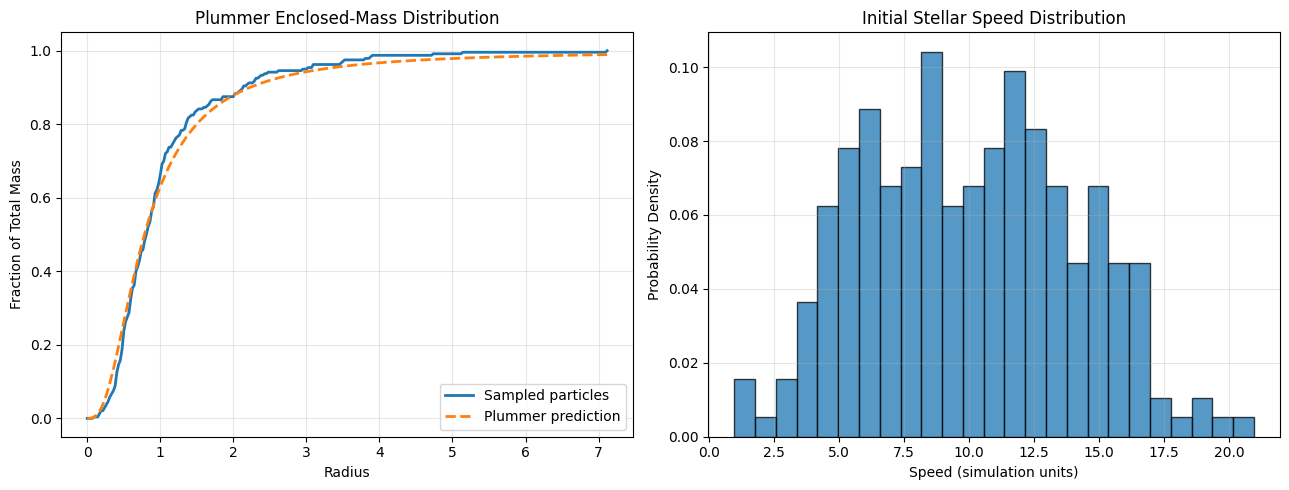

In [18]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 17: PLUMMER STAR-CLUSTER INITIAL CONDITIONS
# Foundation for gravitational transient-response diagnostics
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- PARAMETERS ----------

N17 = 240
TOTAL_MASS17 = 120.0
G17 = G
A17 = 0.6
EPS17 = 0.03
SEED17 = 2026

rng17 = np.random.default_rng(SEED17)
masses17 = np.full(N17, TOTAL_MASS17 / N17)

# ---------- SAMPLE PLUMMER POSITIONS ----------

u = rng17.uniform(size=N17)
u = np.clip(u, 1e-12, 1.0 - 1e-12)

radius_sample = A17 / np.sqrt(u**(-2.0/3.0) - 1.0)

directions = rng17.normal(size=(N17, 3))
directions /= np.linalg.norm(directions, axis=1)[:, None]

pos17 = radius_sample[:, None] * directions

# Center the cluster
pos17 -= np.average(pos17, axis=0, weights=masses17)

# ---------- SAMPLE PLUMMER VELOCITIES ----------

# For the Plummer distribution function:
# q^2 follows Beta(3/2, 9/2).

q = np.sqrt(rng17.beta(1.5, 4.5, size=N17))

velocity_directions = rng17.normal(size=(N17, 3))
velocity_directions /= np.linalg.norm(
    velocity_directions, axis=1
)[:, None]

escape_speed = np.sqrt(
    2.0 * G17 * TOTAL_MASS17
    / np.sqrt(radius_sample**2 + A17**2)
)

vel17 = (
    q[:, None]
    * escape_speed[:, None]
    * velocity_directions
)

vel17 -= np.average(vel17, axis=0, weights=masses17)

# ---------- GRAVITATIONAL ACCELERATION ----------

def acceleration17(pos):
    diff = pos[:, None, :] - pos[None, :, :]
    dist2 = np.sum(diff**2, axis=2) + EPS17**2
    inv_dist3 = dist2**(-1.5)
    np.fill_diagonal(inv_dist3, 0.0)

    return -G17 * np.sum(
        diff * inv_dist3[:, :, None]
        * masses17[None, :, None],
        axis=1
    )

# ---------- INITIAL VIRIAL BALANCE ----------

a_initial17 = acceleration17(pos17)

K_initial17 = 0.5 * np.sum(
    masses17[:, None] * vel17**2
)

W_initial17 = np.sum(
    masses17[:, None] * pos17 * a_initial17
)

# Scale velocities to satisfy initial 2K/|W| = 1
vel17 *= np.sqrt(
    abs(W_initial17) / (2.0 * K_initial17)
)

K17 = 0.5 * np.sum(masses17[:, None] * vel17**2)

i17, j17 = np.triu_indices(N17, k=1)

pair_distance17 = np.sqrt(
    np.sum((pos17[i17] - pos17[j17])**2, axis=1)
    + EPS17**2
)

U17 = -G17 * np.sum(
    masses17[i17] * masses17[j17] / pair_distance17
)

E17 = K17 + U17
Q17 = 2.0 * K17 / abs(W_initial17)

T17 = 2.0 * K17 / (3.0 * (N17 - 1))

# ---------- VALIDATION ----------

assert np.all(np.isfinite(pos17))
assert np.all(np.isfinite(vel17))
assert abs(Q17 - 1.0) < 1e-10

print("PLUMMER STAR-CLUSTER INITIAL CONDITIONS")
print("=" * 54)

print(f"Particles             : {N17}")
print(f"Total mass            : {TOTAL_MASS17:.6f}")
print(f"Plummer scale radius  : {A17:.6f}")
print(f"Softening length      : {EPS17:.6f}")

print(f"\nKinetic energy        : {K17:.6f}")
print(f"Potential energy      : {U17:.6f}")
print(f"Total energy          : {E17:.6f}")
print(f"Initial virial ratio  : {Q17:.6f}")
print(f"Kinetic T proxy       : {T17:.6f}")

# ---------- RADIAL MASS-DISTRIBUTION CHECK ----------

r17 = np.linalg.norm(pos17, axis=1)

r_grid17 = np.linspace(0, np.max(r17), 300)

empirical_mass17 = np.array([
    np.mean(r17 <= value)
    for value in r_grid17
])

theoretical_mass17 = (
    r_grid17**3
    / (r_grid17**2 + A17**2)**1.5
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    r_grid17, empirical_mass17,
    label="Sampled particles", linewidth=2
)

axes[0].plot(
    r_grid17, theoretical_mass17,
    "--", label="Plummer prediction",
    linewidth=2
)

axes[0].set_title("Plummer Enclosed-Mass Distribution")
axes[0].set_xlabel("Radius")
axes[0].set_ylabel("Fraction of Total Mass")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(
    np.linalg.norm(vel17, axis=1),
    bins=25,
    density=True,
    edgecolor="black",
    alpha=0.75
)

axes[1].set_title("Initial Stellar Speed Distribution")
axes[1].set_xlabel("Speed (simulation units)")
axes[1].set_ylabel("Probability Density")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



PLUMMER CLUSTER DYNAMICAL STABILITY TEST
Particles                 : 240
Time step                 : 5e-05
Completed steps           : 3000
Total simulated time      : 0.150000
Characteristic time scale : 0.030000

ENERGY CONSERVATION
------------------------------------------------
Initial total energy      : -7057.991508
Final total energy        : -7057.991594
Maximum sampled error (%) : 0.000046

VIRIAL BALANCE
------------------------------------------------
Initial virial ratio      : 1.000000
Final virial ratio        : 0.985781
Late-time mean ratio      : 0.999129
Late-time std deviation   : 0.011291

CLUSTER STABILITY
------------------------------------------------
Final/initial R50         : 1.011208
Final/initial R90         : 0.944789
Initial kinetic T         : 19.502717
Final kinetic T           : 18.923013
Maximum COM displacement  : 3.563370e-16


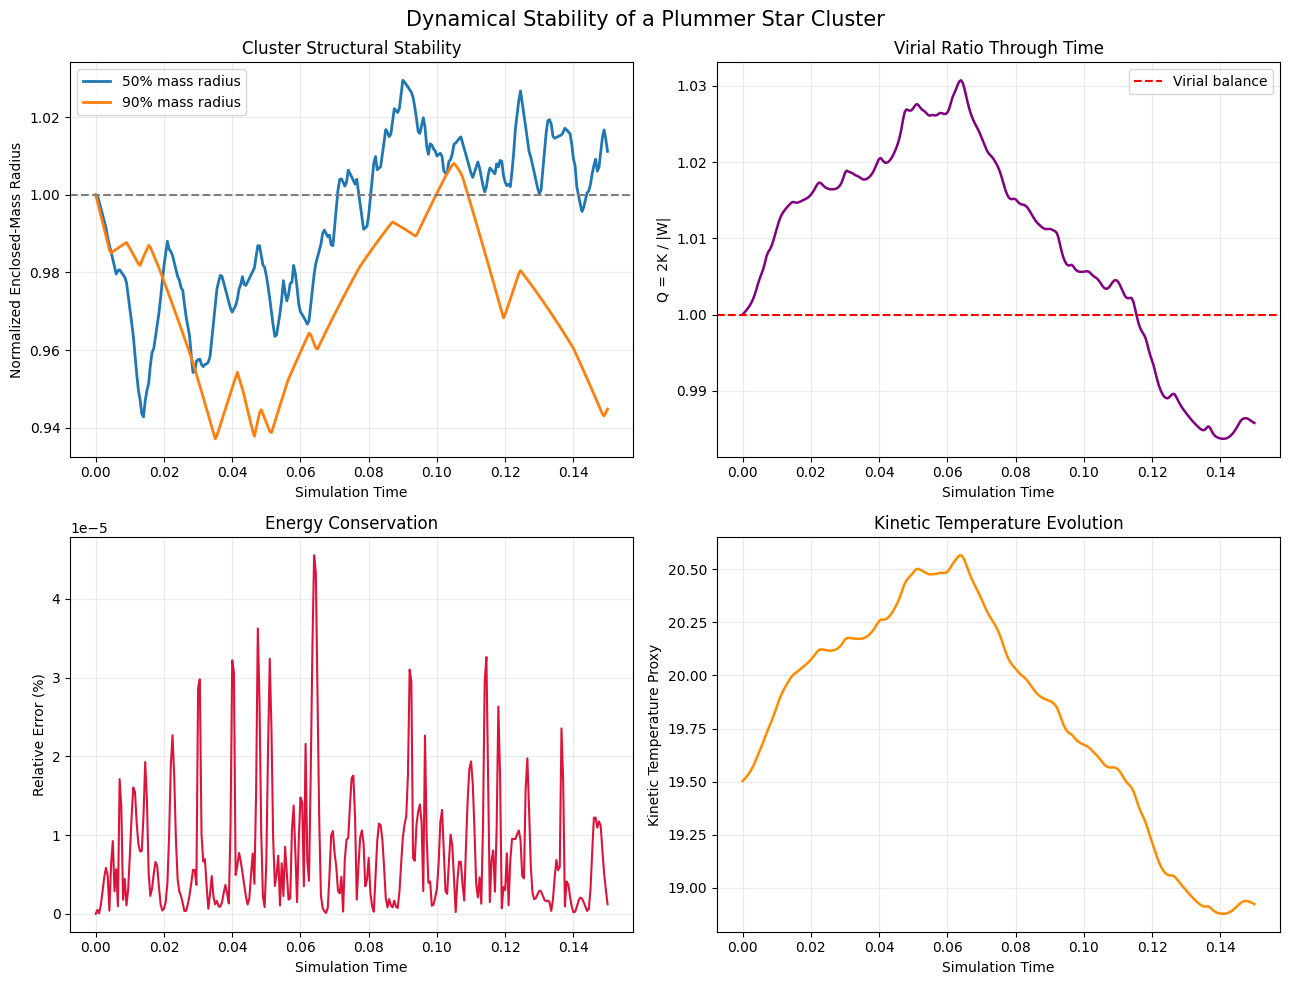

In [19]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 6: ANOMALOUS GRAVITATIONAL THERMODYNAMICS
# CELL 18: PLUMMER CLUSTER DYNAMICAL STABILITY TEST
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- SIMULATION PARAMETERS ----------

DT18 = 0.00005
STEPS18 = 3000
SAVE_EVERY18 = 10

# Approximate characteristic gravitational timescale
T_DYN18 = np.sqrt(
    A17**3 / (G17 * TOTAL_MASS17)
)

# Preserve the initial conditions from Cell 17
p18 = pos17.copy()
v18 = vel17.copy()

a18 = acceleration17(p18)

sample_count18 = STEPS18 // SAVE_EVERY18 + 1

time18 = np.zeros(sample_count18)
energy18 = np.zeros(sample_count18)
error18 = np.zeros(sample_count18)
virial18 = np.zeros(sample_count18)
temperature18 = np.zeros(sample_count18)
r50_18 = np.zeros(sample_count18)
r90_18 = np.zeros(sample_count18)
com18 = np.zeros((sample_count18, 3))

# ---------- EVOLVE THE PLUMMER CLUSTER ----------

for step in range(STEPS18 + 1):

    if step % SAVE_EVERY18 == 0:

        index = step // SAVE_EVERY18

        center_p = np.average(
            p18, axis=0, weights=masses17
        )

        center_v = np.average(
            v18, axis=0, weights=masses17
        )

        relative_p = p18 - center_p
        relative_v = v18 - center_v

        # Kinetic energy in center-of-mass frame
        K = 0.5 * np.sum(
            masses17[:, None] * relative_v**2
        )

        # Softened gravitational potential energy
        separation = p18[i17] - p18[j17]

        distance = np.sqrt(
            np.sum(separation**2, axis=1)
            + EPS17**2
        )

        U = -G17 * np.sum(
            masses17[i17]
            * masses17[j17]
            / distance
        )

        E = K + U

        # Virial term for softened gravity
        W = np.sum(
            masses17[:, None] * relative_p * a18
        )

        # Mass-enclosing radii for equal-mass particles
        particle_radii = np.linalg.norm(
            relative_p, axis=1
        )

        time18[index] = step * DT18
        energy18[index] = E

        error18[index] = (
            abs(E - E17) / abs(E17)
        ) * 100

        virial18[index] = 2.0 * K / abs(W)

        temperature18[index] = (
            2.0 * K / (3.0 * (N17 - 1))
        )

        r50_18[index] = np.quantile(
            particle_radii, 0.50
        )

        r90_18[index] = np.quantile(
            particle_radii, 0.90
        )

        com18[index] = center_p

    if step == STEPS18:
        break

    # ---------- VELOCITY VERLET ----------

    p18 = (
        p18
        + v18 * DT18
        + 0.5 * a18 * DT18**2
    )

    a_new18 = acceleration17(p18)

    v18 = (
        v18
        + 0.5 * (a18 + a_new18) * DT18
    )

    a18 = a_new18


# ---------- VALIDATION ----------

assert np.all(np.isfinite(energy18))
assert np.all(np.isfinite(virial18))
assert np.all(np.isfinite(temperature18))
assert np.all(np.isfinite(r50_18))
assert np.all(np.isfinite(r90_18))

late18 = slice(sample_count18 // 2, None)

# ---------- PRINT RESULTS ----------

print("PLUMMER CLUSTER DYNAMICAL STABILITY TEST")
print("=" * 58)

print(f"Particles                 : {N17}")
print(f"Time step                 : {DT18}")
print(f"Completed steps           : {STEPS18}")
print(f"Total simulated time      : {time18[-1]:.6f}")
print(f"Characteristic time scale : {T_DYN18:.6f}")

print("\nENERGY CONSERVATION")
print("-" * 48)

print(f"Initial total energy      : {energy18[0]:.6f}")
print(f"Final total energy        : {energy18[-1]:.6f}")
print(f"Maximum sampled error (%) : {np.max(error18):.6f}")

print("\nVIRIAL BALANCE")
print("-" * 48)

print(f"Initial virial ratio      : {virial18[0]:.6f}")
print(f"Final virial ratio        : {virial18[-1]:.6f}")
print(f"Late-time mean ratio      : {np.mean(virial18[late18]):.6f}")
print(f"Late-time std deviation   : {np.std(virial18[late18]):.6f}")

print("\nCLUSTER STABILITY")
print("-" * 48)

print(f"Final/initial R50         : {r50_18[-1]/r50_18[0]:.6f}")
print(f"Final/initial R90         : {r90_18[-1]/r90_18[0]:.6f}")
print(f"Initial kinetic T         : {temperature18[0]:.6f}")
print(f"Final kinetic T           : {temperature18[-1]:.6f}")

print(
    "Maximum COM displacement  :",
    f"{np.max(np.linalg.norm(com18-com18[0],axis=1)):.6e}"
)

# ---------- VISUALIZE THE RESULTS ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Graph 1: Mass-concentration radii
axes[0, 0].plot(
    time18,
    r50_18 / r50_18[0],
    label="50% mass radius",
    linewidth=2
)

axes[0, 0].plot(
    time18,
    r90_18 / r90_18[0],
    label="90% mass radius",
    linewidth=2
)

axes[0, 0].axhline(
    1.0, color="gray", linestyle="--"
)

axes[0, 0].set_title("Cluster Structural Stability")
axes[0, 0].set_ylabel("Normalized Enclosed-Mass Radius")
axes[0, 0].legend()

# Graph 2: Virial balance
axes[0, 1].plot(
    time18,
    virial18,
    color="purple",
    linewidth=1.8
)

axes[0, 1].axhline(
    1.0,
    linestyle="--",
    color="red",
    label="Virial balance"
)

axes[0, 1].set_title("Virial Ratio Through Time")
axes[0, 1].set_ylabel("Q = 2K / |W|")
axes[0, 1].legend()

# Graph 3: Energy error
axes[1, 0].plot(
    time18,
    error18,
    color="crimson"
)

axes[1, 0].set_title("Energy Conservation")
axes[1, 0].set_ylabel("Relative Error (%)")

# Graph 4: Kinetic-temperature proxy
axes[1, 1].plot(
    time18,
    temperature18,
    color="darkorange",
    linewidth=1.8
)

axes[1, 1].set_title("Kinetic Temperature Evolution")
axes[1, 1].set_ylabel("Kinetic Temperature Proxy")

for ax in axes.flat:
    ax.set_xlabel("Simulation Time")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Dynamical Stability of a Plummer Star Cluster",
    fontsize=15
)

plt.tight_layout()
plt.show()



Running velocity factor = 0.82...
Running velocity factor = 0.88...
Running velocity factor = 0.94...
Running velocity factor = 1.00...

PLUMMER TRANSIENT RESPONSE: VELOCITY PERTURBATIONS
Velocity    Total E        Initial T      Late mean T    Late mean Q    Max err (%)
--------------------------------------------------------------------------------------
0.82        -9280.3973     12.7238        23.8039        0.9665         0.000126
0.88        -8588.4395     14.6540        22.3932        0.9729         0.000096
0.94        -7847.6376     16.7204        21.1690        0.9895         0.000074
1.00        -7057.9916     18.9230        19.4766        1.0006         0.000049

EXPLORATORY FINITE-TIME E–T PROXY (NOT HEAT CAPACITY)
-------------------------------------------------------
Finite-time fitted E–T slope: -520.0160
Idealized virial reference: -358.5000
Negative DESCRIPTIVE slope; equilibrium heat capacity not established.

LATE-TIME STABILITY DIAGNOSTICS
------------------------

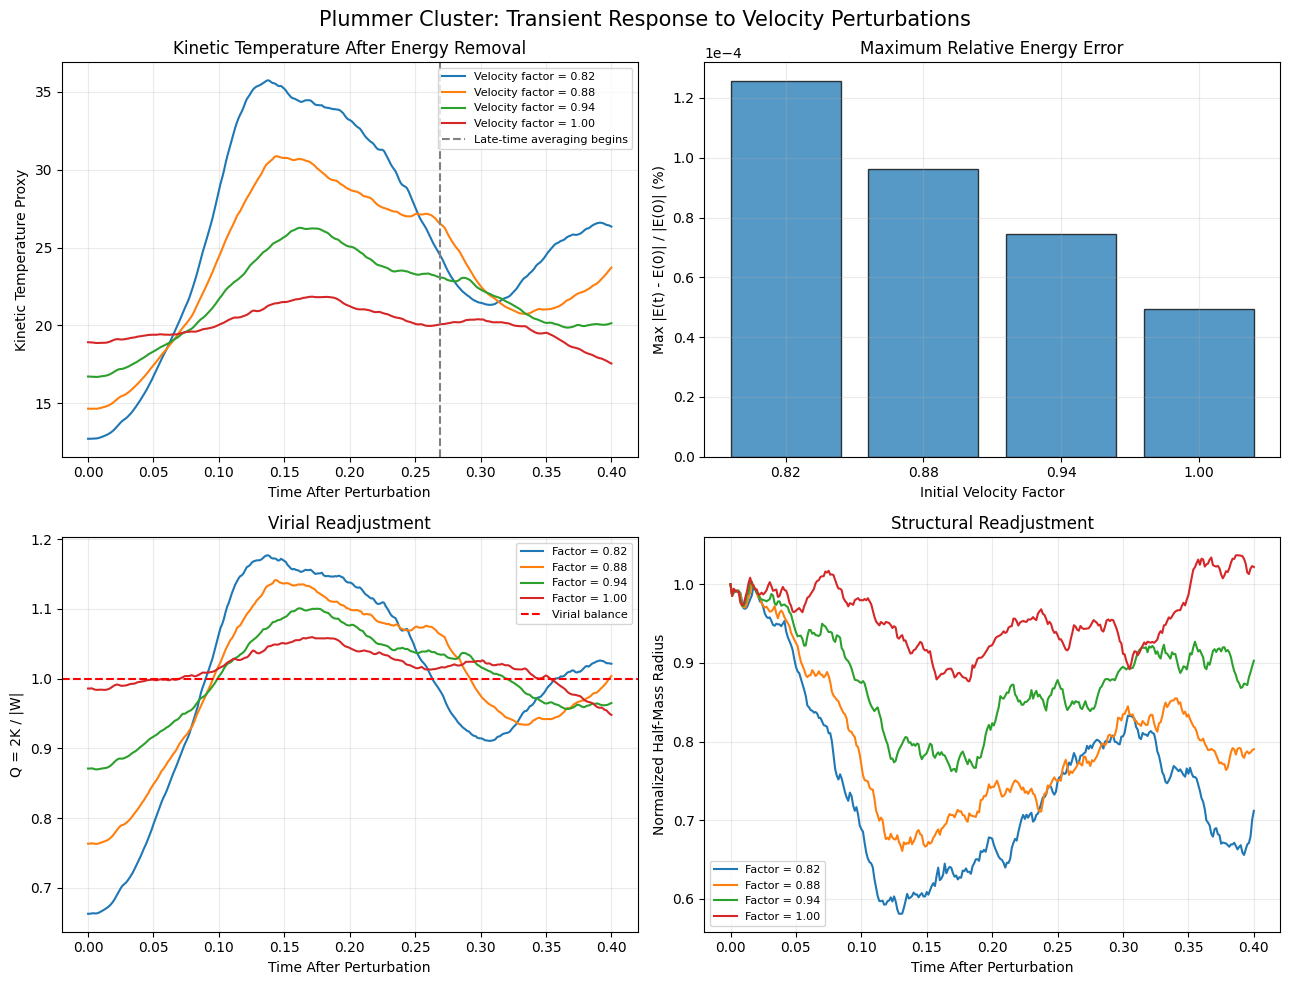

NOTE: The descriptive E–T slope is not an equilibrium heat capacity.


In [20]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 19: PLUMMER CLUSTER TRANSIENT-RESPONSE DIAGNOSTICS
# Velocity perturbations and subsequent gravitational readjustment.
# No equilibrium heat capacity is inferred.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- EXPERIMENT SETTINGS ----------

VELOCITY_FACTORS19 = [0.82, 0.88, 0.94, 1.00]

DT19 = DT18
STEPS19 = 8000
SAVE19 = 25

time19 = np.arange(0, STEPS19 + 1, SAVE19) * DT19

# Use the final Plummer state from Cell 18.
# Neither Cell 17 nor Cell 18 is modified.
base_pos19 = p18.copy()
base_vel19 = v18.copy()

base_vel19 -= np.average(
    base_vel19, axis=0, weights=masses17
)

# ---------- ENERGY FUNCTION ----------

def total_energy19(pos, vel):

    K = 0.5 * np.sum(
        masses17[:, None] * vel**2
    )

    separation = pos[i17] - pos[j17]

    distances = np.sqrt(
        np.sum(separation**2, axis=1) + EPS17**2
    )

    U = -G17 * np.sum(
        masses17[i17] * masses17[j17] / distances
    )

    return K + U


# ---------- ONE VELOCITY-PERTURBATION EXPERIMENT ----------

def run_energy_experiment19(velocity_factor):

    p = base_pos19.copy()
    v = base_vel19.copy() * velocity_factor

    a = acceleration17(p)

    E_initial = total_energy19(p, v)

    n_samples = len(time19)

    temperature = np.zeros(n_samples)
    virial_ratio = np.zeros(n_samples)
    half_mass_radius = np.zeros(n_samples)
    energy_error = np.zeros(n_samples)

    for step in range(STEPS19 + 1):

        if step % SAVE19 == 0:

            index = step // SAVE19

            center_p = np.average(
                p, axis=0, weights=masses17
            )

            center_v = np.average(
                v, axis=0, weights=masses17
            )

            relative_p = p - center_p
            relative_v = v - center_v

            K = 0.5 * np.sum(
                masses17[:, None] * relative_v**2
            )

            W = np.sum(
                masses17[:, None] * relative_p * a
            )

            temperature[index] = (
                2.0 * K / (3.0 * (N17 - 1))
            )

            virial_ratio[index] = (
                2.0 * K / abs(W)
            )

            particle_radii = np.linalg.norm(
                relative_p, axis=1
            )

            half_mass_radius[index] = np.median(
                particle_radii
            )

            E_current = total_energy19(p, v)

            energy_error[index] = (
                abs(E_current - E_initial)
                / abs(E_initial)
            ) * 100

        if step == STEPS19:
            break

        # Velocity Verlet integration

        p = (
            p
            + v * DT19
            + 0.5 * a * DT19**2
        )

        a_new = acceleration17(p)

        v = (
            v
            + 0.5 * (a + a_new) * DT19
        )

        a = a_new

    # Use the final third for approximate steady-state analysis

    late_start = int(0.67 * n_samples)
    late = slice(late_start, None)

    mean_T = np.mean(temperature[late])
    mean_Q = np.mean(virial_ratio[late])

    radius_variation = (
        np.std(half_mass_radius[late])
        / np.mean(half_mass_radius[late])
    )

    assert np.all(np.isfinite(temperature))
    assert np.all(np.isfinite(virial_ratio))
    assert np.all(np.isfinite(energy_error))

    return {
        "factor": velocity_factor,
        "E": E_initial,
        "T_initial": temperature[0],
        "T_late": mean_T,
        "Q_late": mean_Q,
        "radius_variation": radius_variation,
        "temperature": temperature,
        "virial": virial_ratio,
        "radius": half_mass_radius,
        "max_error": np.max(energy_error)
    }


# ---------- RUN FOUR EXPERIMENTS ----------

results19 = {}

for factor in VELOCITY_FACTORS19:

    print(f"Running velocity factor = {factor:.2f}...")

    results19[factor] = run_energy_experiment19(
        factor
    )


# ---------- EXTRACT RESULTS ----------

energy_values19 = np.array([
    results19[f]["E"]
    for f in VELOCITY_FACTORS19
])

temperature_values19 = np.array([
    results19[f]["T_late"]
    for f in VELOCITY_FACTORS19
])

# Descriptive finite-time E-versus-kinetic-proxy slope only.
# This is NOT a thermodynamic derivative or a measured heat capacity.
slope19, intercept19 = np.polyfit(
    temperature_values19,
    energy_values19,
    1
)

# Idealized unsoftened virial-theorem reference
theoretical_slope19 = -1.5 * (N17 - 1)

# ---------- PRINT RESULTS ----------

print("\nPLUMMER TRANSIENT RESPONSE: VELOCITY PERTURBATIONS")
print("=" * 86)

print(
    f"{'Velocity':<12}"
    f"{'Total E':<15}"
    f"{'Initial T':<15}"
    f"{'Late mean T':<15}"
    f"{'Late mean Q':<15}"
    f"{'Max err (%)'}"
)

print("-" * 86)

for factor in VELOCITY_FACTORS19:

    result = results19[factor]

    print(
        f"{factor:<12.2f}"
        f"{result['E']:<15.4f}"
        f"{result['T_initial']:<15.4f}"
        f"{result['T_late']:<15.4f}"
        f"{result['Q_late']:<15.4f}"
        f"{result['max_error']:.6f}"
    )

print("\nEXPLORATORY FINITE-TIME E–T PROXY (NOT HEAT CAPACITY)")
print("-" * 55)

print(f"Finite-time fitted E–T slope: {slope19:.4f}")
print(f"Idealized virial reference: {theoretical_slope19:.4f}")

if slope19 < 0:
    print("Negative DESCRIPTIVE slope; equilibrium heat capacity not established.")
else:
    print("Descriptive slope is nonnegative; no heat-capacity inference.")

print("\nLATE-TIME STABILITY DIAGNOSTICS")
print("-" * 55)

for factor in VELOCITY_FACTORS19:

    result = results19[factor]

    print(
        f"Factor {factor:.2f}: "
        f"Q_mean={result['Q_late']:.4f}, "
        f"R50 relative fluctuation="
        f"{100*result['radius_variation']:.2f}%"
    )


# ---------- PLOT RESULTS ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# GRAPH 1: TEMPERATURE READJUSTMENT

for factor in VELOCITY_FACTORS19:

    axes[0, 0].plot(
        time19,
        results19[factor]["temperature"],
        label=f"Velocity factor = {factor:.2f}"
    )

axes[0, 0].axvline(
    time19[int(0.67 * len(time19))],
    linestyle="--",
    color="gray",
    label="Late-time averaging begins"
)

axes[0, 0].set_title("Kinetic Temperature After Energy Removal")
axes[0, 0].set_xlabel("Time After Perturbation")
axes[0, 0].set_ylabel("Kinetic Temperature Proxy")
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(alpha=0.25)

# GRAPH 2: ENERGY CONSERVATION (VALIDATED QUANTITY)

energy_drift19 = np.array([
    results19[f]["max_error"] for f in VELOCITY_FACTORS19
])
axes[0, 1].bar(
    [f"{f:.2f}" for f in VELOCITY_FACTORS19],
    energy_drift19,
    edgecolor="black", alpha=0.75
)
axes[0, 1].set_title("Maximum Relative Energy Error")
axes[0, 1].set_xlabel("Initial Velocity Factor")
axes[0, 1].set_ylabel("Max |E(t) - E(0)| / |E(0)| (%)")
axes[0, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[0, 1].grid(alpha=0.25)

# GRAPH 3: VIRIAL READJUSTMENT

for factor in VELOCITY_FACTORS19:

    axes[1, 0].plot(
        time19,
        results19[factor]["virial"],
        label=f"Factor = {factor:.2f}"
    )

axes[1, 0].axhline(
    1.0,
    color="red",
    linestyle="--",
    label="Virial balance"
)

axes[1, 0].set_title("Virial Readjustment")
axes[1, 0].set_xlabel("Time After Perturbation")
axes[1, 0].set_ylabel("Q = 2K / |W|")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.25)

# GRAPH 4: CLUSTER SIZE

for factor in VELOCITY_FACTORS19:

    r = results19[factor]["radius"]

    axes[1, 1].plot(
        time19,
        r / r[0],
        label=f"Factor = {factor:.2f}"
    )

axes[1, 1].set_title("Structural Readjustment")
axes[1, 1].set_xlabel("Time After Perturbation")
axes[1, 1].set_ylabel("Normalized Half-Mass Radius")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.25)

plt.suptitle(
    "Plummer Cluster: Transient Response to Velocity Perturbations",
    fontsize=15
)

plt.tight_layout()
plt.show()
print("NOTE: The descriptive E–T slope is not an equilibrium heat capacity.")



FINITE-TIME E–T PROXY: AVERAGING-WINDOW SENSITIVITY
Late start    dE/dT slope      R-squared     
0.50          -370.8154        0.998306      
0.60          -458.1359        0.992745      
0.67          -520.0160        0.997665      
0.75          -450.3006        0.956041      
0.80          -369.4890        0.932856      

LATE-TIME STABILITY DIAGNOSTICS
Factor    Mean T      Mean Q      R50 CV %     T drift %    
0.82      23.8039     0.9665      7.292        +21.867      
0.88      22.3932     0.9729      3.152        -11.410      
0.94      21.1690     0.9895      2.532        -18.010      
1.00      19.4766     1.0006      4.547        -14.220      

IDEALIZED VIRIAL-THEOREM REFERENCE
Ideal dE/dT: -358.5000
Factor 0.82: Measured T = 23.8039, Idealized T = 25.8867
Factor 0.88: Measured T = 22.3932, Idealized T = 23.9566
Factor 0.94: Measured T = 21.1690, Idealized T = 21.8902
Factor 1.00: Measured T = 19.4766, Idealized T = 19.6876


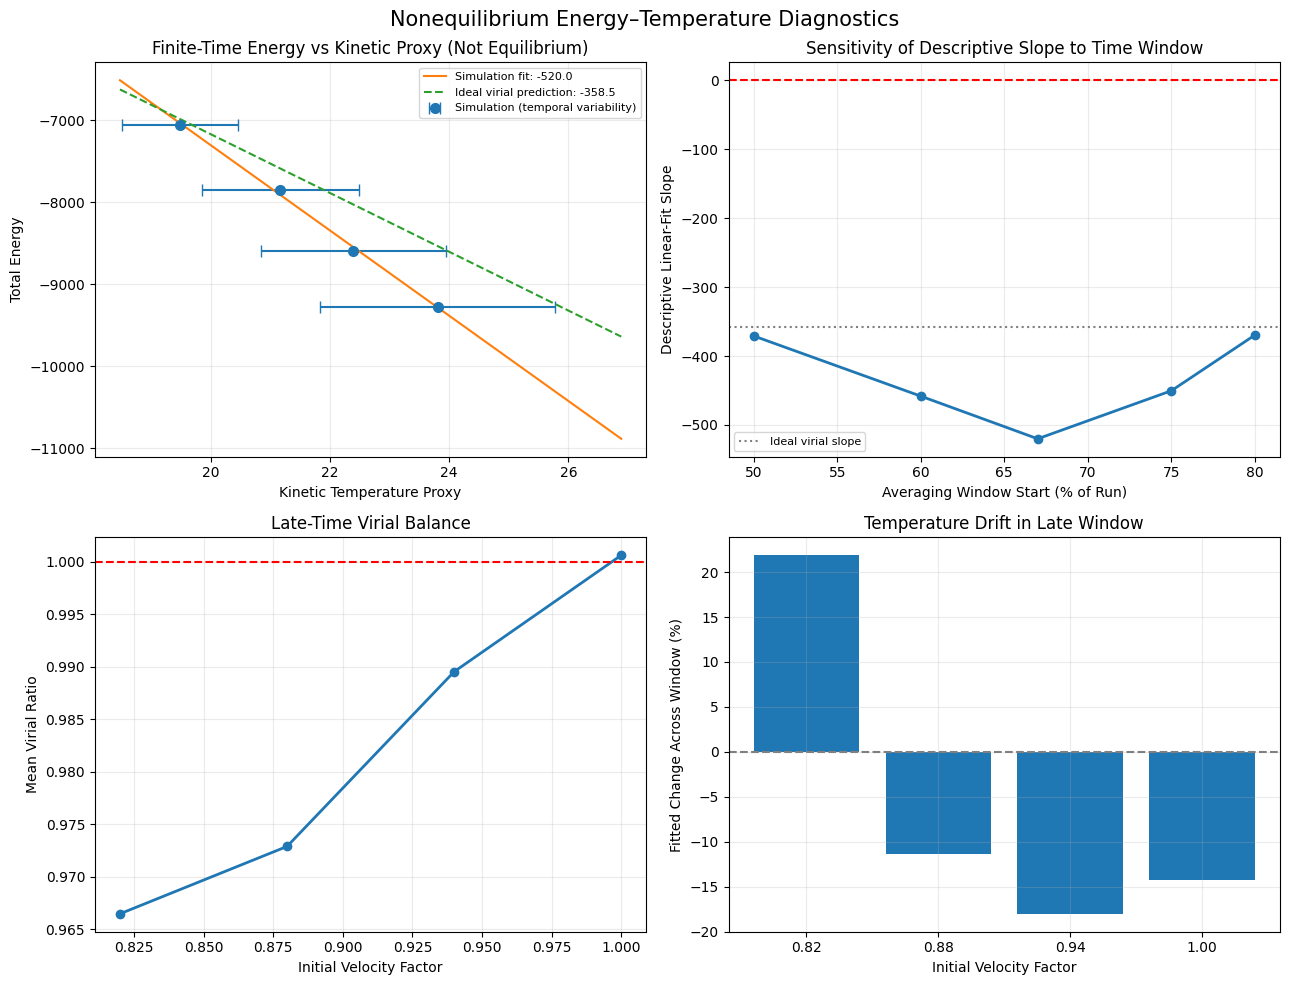


ROBUSTNESS SUMMARY
Negative slope in all windows: True
Slope range: -520.0160 to -369.4890
NOTE: Negative fitted slopes are not equilibrium heat capacities.
Maximum absolute late-time temperature drift: 21.867%


In [21]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 20: NON-EQUILIBRIUM E–T PROXY SENSITIVITY
# No new simulation: analyze existing Cell 19 results
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

factors20 = np.array(VELOCITY_FACTORS19, dtype=float)

energies20 = np.array([
    results19[f]["E"] for f in factors20
])

# Late-time averaging windows
window_starts20 = [0.50, 0.60, 0.67, 0.75, 0.80]

window_slopes20 = []
window_r2_20 = []

# ---------- TEST AVERAGING-WINDOW SENSITIVITY ----------

print("FINITE-TIME E–T PROXY: AVERAGING-WINDOW SENSITIVITY")
print("=" * 65)
print(f"{'Late start':<14}{'dE/dT slope':<17}{'R-squared':<14}")

for fraction in window_starts20:

    start = int(fraction * len(time19))

    mean_temperatures = np.array([
        np.mean(results19[f]["temperature"][start:])
        for f in factors20
    ])

    slope, intercept = np.polyfit(
        mean_temperatures,
        energies20,
        1
    )

    predicted = slope * mean_temperatures + intercept

    residual = np.sum(
        (energies20 - predicted)**2
    )

    total = np.sum(
        (energies20 - np.mean(energies20))**2
    )

    r_squared = 1.0 - residual / total

    window_slopes20.append(slope)
    window_r2_20.append(r_squared)

    print(
        f"{fraction:<14.2f}"
        f"{slope:<17.4f}"
        f"{r_squared:<14.6f}"
    )

window_slopes20 = np.array(window_slopes20)

# ---------- DIAGNOSTICS FOR ORIGINAL LATE WINDOW ----------

late_start20 = int(0.67 * len(time19))
late_time20 = time19[late_start20:]

mean_T20 = []
temporal_scatter20 = []
mean_Q20 = []
radius_cv20 = []
temperature_drift20 = []

print("\nLATE-TIME STABILITY DIAGNOSTICS")
print("=" * 75)

print(
    f"{'Factor':<10}"
    f"{'Mean T':<12}"
    f"{'Mean Q':<12}"
    f"{'R50 CV %':<13}"
    f"{'T drift %':<13}"
)

for factor in factors20:

    result = results19[factor]

    T_series = result["temperature"][late_start20:]
    Q_series = result["virial"][late_start20:]
    R_series = result["radius"][late_start20:]

    mean_T = np.mean(T_series)
    mean_Q = np.mean(Q_series)

    radius_cv = (
        100.0 * np.std(R_series) / np.mean(R_series)
    )

    # Approximate temperature trend across late window
    T_slope = np.polyfit(
        late_time20, T_series, 1
    )[0]

    T_drift = (
        100.0 * T_slope
        * (late_time20[-1] - late_time20[0])
        / mean_T
    )

    # Block-to-block temperature variation.
    # This is temporal variability, not a confidence interval.
    blocks = np.array_split(T_series, 4)

    block_means = np.array([
        np.mean(block) for block in blocks
    ])

    scatter = np.std(block_means, ddof=1)

    mean_T20.append(mean_T)
    temporal_scatter20.append(scatter)
    mean_Q20.append(mean_Q)
    radius_cv20.append(radius_cv)
    temperature_drift20.append(T_drift)

    print(
        f"{factor:<10.2f}"
        f"{mean_T:<12.4f}"
        f"{mean_Q:<12.4f}"
        f"{radius_cv:<13.3f}"
        f"{T_drift:<+13.3f}"
    )

mean_T20 = np.array(mean_T20)
temporal_scatter20 = np.array(temporal_scatter20)
mean_Q20 = np.array(mean_Q20)
radius_cv20 = np.array(radius_cv20)
temperature_drift20 = np.array(temperature_drift20)

# ---------- IDEALIZED VIRIAL REFERENCE (NOT A MEASUREMENT) ----------

# For an unsoftened, virialized Newtonian cluster:
# E = -K = -(3/2)(N-1)T when k_B = 1.

C_ideal20 = -1.5 * (N17 - 1)

T_virial20 = energies20 / C_ideal20

print("\nIDEALIZED VIRIAL-THEOREM REFERENCE")
print("=" * 65)

print(f"Ideal dE/dT: {C_ideal20:.4f}")

for factor, actual, theoretical in zip(
    factors20, mean_T20, T_virial20
):
    print(
        f"Factor {factor:.2f}: "
        f"Measured T = {actual:.4f}, "
        f"Idealized T = {theoretical:.4f}"
    )

# ---------- VISUALIZATION ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# GRAPH 1: ENERGY VS TEMPERATURE

axes[0, 0].errorbar(
    mean_T20,
    energies20,
    xerr=temporal_scatter20,
    fmt="o",
    capsize=4,
    markersize=7,
    label="Simulation (temporal variability)"
)

fit_slope20, fit_intercept20 = np.polyfit(
    mean_T20, energies20, 1
)

T_line20 = np.linspace(
    min(mean_T20) - 1,
    max(T_virial20.max(), mean_T20.max()) + 1,
    200
)

axes[0, 0].plot(
    T_line20,
    fit_slope20 * T_line20 + fit_intercept20,
    label=f"Simulation fit: {fit_slope20:.1f}"
)

axes[0, 0].plot(
    T_line20,
    C_ideal20 * T_line20,
    "--",
    label=f"Ideal virial prediction: {C_ideal20:.1f}"
)

axes[0, 0].set_title("Finite-Time Energy vs Kinetic Proxy (Not Equilibrium)")
axes[0, 0].set_xlabel("Kinetic Temperature Proxy")
axes[0, 0].set_ylabel("Total Energy")
axes[0, 0].legend(fontsize=8)

# GRAPH 2: SLOPE SENSITIVITY

axes[0, 1].plot(
    np.array(window_starts20) * 100,
    window_slopes20,
    "o-",
    linewidth=2
)

axes[0, 1].axhline(
    0, color="red", linestyle="--"
)

axes[0, 1].axhline(
    C_ideal20,
    color="gray",
    linestyle=":",
    label="Ideal virial slope"
)

axes[0, 1].set_title("Sensitivity of Descriptive Slope to Time Window")
axes[0, 1].set_xlabel("Averaging Window Start (% of Run)")
axes[0, 1].set_ylabel("Descriptive Linear-Fit Slope")
axes[0, 1].legend(fontsize=8)

# GRAPH 3: VIRIAL BALANCE

axes[1, 0].plot(
    factors20,
    mean_Q20,
    "o-",
    linewidth=2
)

axes[1, 0].axhline(
    1, color="red", linestyle="--"
)

axes[1, 0].set_title("Late-Time Virial Balance")
axes[1, 0].set_xlabel("Initial Velocity Factor")
axes[1, 0].set_ylabel("Mean Virial Ratio")

# GRAPH 4: TEMPERATURE DRIFT

axes[1, 1].bar(
    [f"{f:.2f}" for f in factors20],
    temperature_drift20
)

axes[1, 1].axhline(
    0, color="gray", linestyle="--"
)

axes[1, 1].set_title("Temperature Drift in Late Window")
axes[1, 1].set_xlabel("Initial Velocity Factor")
axes[1, 1].set_ylabel("Fitted Change Across Window (%)")

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.suptitle(
    "Nonequilibrium Energy–Temperature Diagnostics",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ---------- FINAL CHECKS ----------

assert np.all(np.isfinite(window_slopes20))
assert np.all(np.isfinite(mean_T20))

print("\nROBUSTNESS SUMMARY")
print("=" * 55)

print(
    "Negative slope in all windows:",
    bool(np.all(window_slopes20 < 0))
)

print(
    "Slope range:",
    f"{np.min(window_slopes20):.4f}",
    "to",
    f"{np.max(window_slopes20):.4f}"
)

print("NOTE: Negative fitted slopes are not equilibrium heat capacities.")

print(
    "Maximum absolute late-time temperature drift:",
    f"{np.max(np.abs(temperature_drift20)):.3f}%"
)



CONSTRUCTED PLUMMER SCALING: ALGEBRAIC CONSISTENCY
Scale      R50          Total E         Kinetic T      Virial Q
-------------------------------------------------------------------------------
0.650      0.527130     -10858.448473   30.004180      1.000000
0.800      0.648776     -8822.489384    24.378396      1.000000
1.000      0.810970     -7057.991508    19.502717      1.000000
1.250      1.013712     -5646.393206    15.602173      1.000000
1.550      1.257003     -4553.542908    12.582398      1.000000

CALORIC RELATION
-------------------------------------------------------
Idealized virial slope : -358.500000
Calculated family slope: -361.897862
Fitted intercept       : 0.000000
R-squared              : 1.000000
Relative slope difference: 0.9478%
Maximum virial-ratio deviation: 4.440892e-16


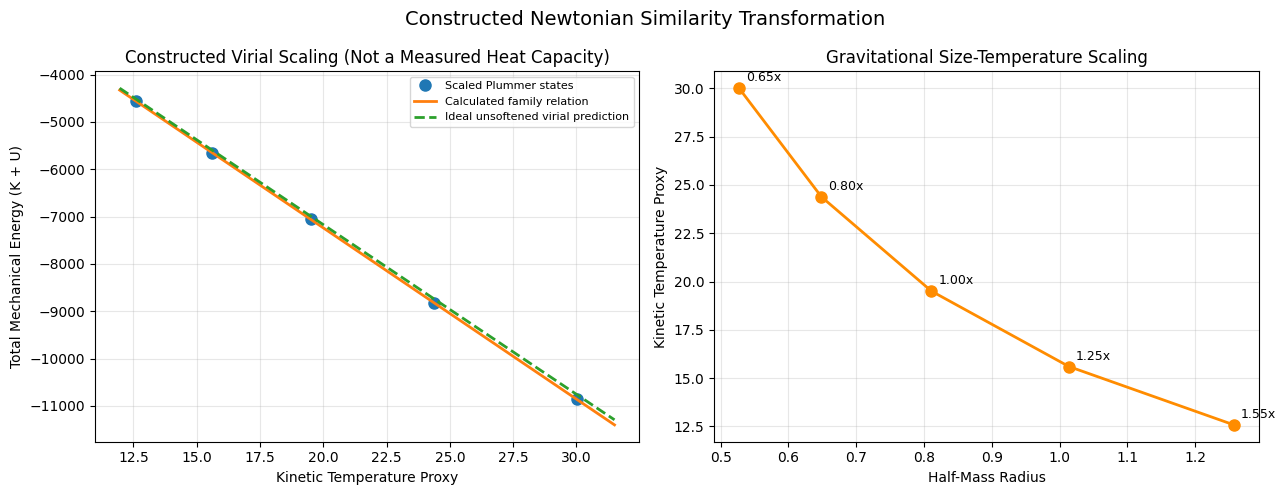

In [22]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 21: CONSTRUCTED VIRIAL SCALING - MATHEMATICAL CONTROL
# Homologous rescaling of one state; not independent equilibrium samples.
# Does not modify or rerun previous simulations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- CONTROLLED LENGTH SCALES ----------

SCALE_FACTORS21 = np.array([
    0.65, 0.80, 1.00, 1.25, 1.55
])

E21 = []
T21 = []
Q21 = []
R21 = []
K21 = []
U21 = []
W21 = []

# ---------- CONSTRUCT SELF-SIMILAR PLUMMER STATES ----------

for scale in SCALE_FACTORS21:

    # Newtonian gravitational similarity transformation
    p = pos17.copy() * scale
    v = vel17.copy() / np.sqrt(scale)

    # Keep numerical softening proportional to system size
    eps = EPS17 * scale

    # Kinetic energy
    K = 0.5 * np.sum(
        masses17[:, None] * v**2
    )

    # Pairwise particle distances
    dr = p[i17] - p[j17]
    r2 = np.sum(dr**2, axis=1)

    pair_mass = masses17[i17] * masses17[j17]

    # Softened gravitational potential energy
    U = -G17 * np.sum(
        pair_mass / np.sqrt(r2 + eps**2)
    )

    # Exact gravitational virial term for softened forces
    W = -G17 * np.sum(
        pair_mass * r2 / (r2 + eps**2)**1.5
    )

    E = K + U

    # Kinetic temperature in simulation units
    T = 2.0 * K / (3.0 * (N17 - 1))

    # Virial ratio
    Q = 2.0 * K / abs(W)

    # Half-mass radius
    center = np.average(
        p, axis=0, weights=masses17
    )

    R50 = np.median(
        np.linalg.norm(p - center, axis=1)
    )

    E21.append(E)
    T21.append(T)
    Q21.append(Q)
    R21.append(R50)
    K21.append(K)
    U21.append(U)
    W21.append(W)

E21 = np.array(E21)
T21 = np.array(T21)
Q21 = np.array(Q21)
R21 = np.array(R21)
K21 = np.array(K21)
U21 = np.array(U21)
W21 = np.array(W21)

# ---------- CALORIC RELATION ----------

C_ideal21 = -1.5 * (N17 - 1)

C_family21, intercept21 = np.polyfit(
    T21, E21, 1
)

predicted_E21 = (
    C_family21 * T21 + intercept21
)

r_squared21 = 1.0 - (
    np.sum((E21 - predicted_E21)**2)
    / np.sum((E21 - np.mean(E21))**2)
)

# ---------- PRINT RESULTS ----------

print("CONSTRUCTED PLUMMER SCALING: ALGEBRAIC CONSISTENCY")
print("=" * 79)

print(
    f"{'Scale':<11}"
    f"{'R50':<13}"
    f"{'Total E':<16}"
    f"{'Kinetic T':<15}"
    f"{'Virial Q'}"
)

print("-" * 79)

for i in range(len(SCALE_FACTORS21)):

    print(
        f"{SCALE_FACTORS21[i]:<11.3f}"
        f"{R21[i]:<13.6f}"
        f"{E21[i]:<16.6f}"
        f"{T21[i]:<15.6f}"
        f"{Q21[i]:.6f}"
    )

print("\nCALORIC RELATION")
print("-" * 55)

print(f"Idealized virial slope : {C_ideal21:.6f}")
print(f"Calculated family slope: {C_family21:.6f}")
print(f"Fitted intercept       : {intercept21:.6f}")
print(f"R-squared              : {r_squared21:.6f}")

print(
    "Relative slope difference:",
    f"{100 * abs(C_family21 - C_ideal21) / abs(C_ideal21):.4f}%"
)

print(
    "Maximum virial-ratio deviation:",
    f"{np.max(np.abs(Q21 - 1.0)):.6e}"
)

# ---------- VALIDATION ----------

assert np.all(np.isfinite(E21))
assert np.all(np.isfinite(T21))
assert np.all(E21 < 0)
assert np.all(T21 > 0)
assert np.max(np.abs(Q21 - 1.0)) < 1e-8

# ---------- GRAPH 1: ENERGY VS TEMPERATURE ----------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

t_line = np.linspace(
    T21.min() * 0.95,
    T21.max() * 1.05,
    200
)

axes[0].plot(
    T21, E21,
    "o",
    markersize=8,
    label="Scaled Plummer states"
)

axes[0].plot(
    t_line,
    C_family21 * t_line + intercept21,
    linewidth=2,
    label="Calculated family relation"
)

axes[0].plot(
    t_line,
    C_ideal21 * t_line,
    "--",
    linewidth=2,
    label="Ideal unsoftened virial prediction"
)

axes[0].set_title("Constructed Virial Scaling (Not a Measured Heat Capacity)")
axes[0].set_xlabel("Kinetic Temperature Proxy")
axes[0].set_ylabel("Total Mechanical Energy (K + U)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# ---------- GRAPH 2: SIZE VS TEMPERATURE ----------

axes[1].plot(
    R21, T21,
    "o-",
    linewidth=2,
    markersize=8,
    color="darkorange"
)

for i, scale in enumerate(SCALE_FACTORS21):
    axes[1].annotate(
        f"{scale:.2f}x",
        (R21[i], T21[i]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

axes[1].set_title("Gravitational Size-Temperature Scaling")
axes[1].set_xlabel("Half-Mass Radius")
axes[1].set_ylabel("Kinetic Temperature Proxy")
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Constructed Newtonian Similarity Transformation",
    fontsize=14
)

plt.tight_layout()
plt.show()



3D SCHRODINGER-POISSON MODEL
Grid: 48 x 48 x 48
Domain length: 12.0
Grid spacing: 0.25
Effective hbar: 0.4
Gaussian width: 0.8

WAVEFUNCTION VALIDATION
---------------------------------------------
Calculated total mass: 1.0000000000
Poisson relative residual: 5.304e-14

INITIAL WAVE + NEWTONIAN GRAVITY ENERGY
---------------------------------------------
Wave kinetic energy: 0.093750
Gravitational energy: -0.236725
Total energy: -0.142975
Initial energy-magnitude ratio (2K/|U|; not periodic virial Q): 0.792059


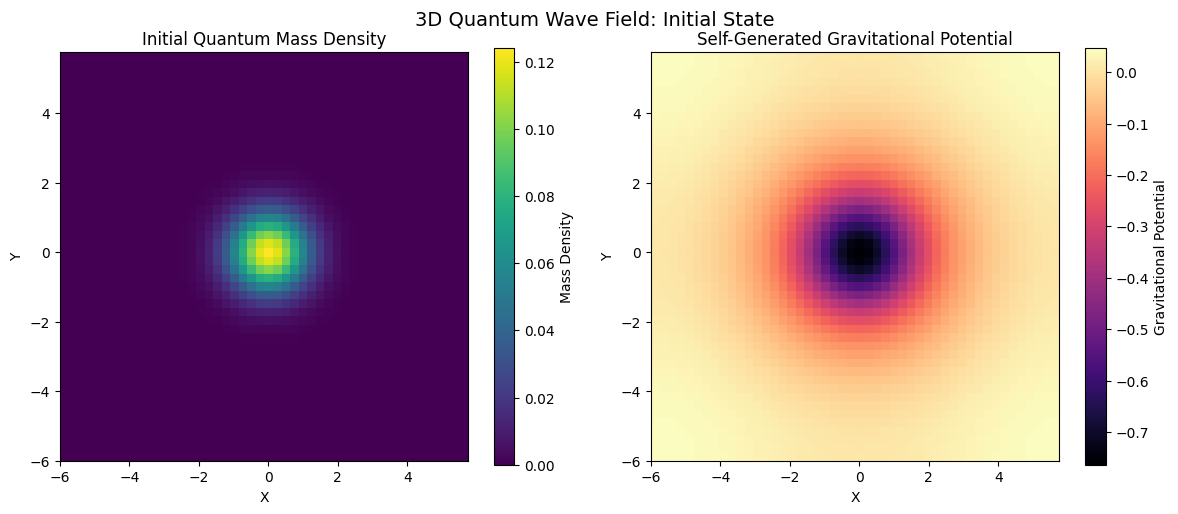

In [23]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 7: QUANTUM WAVE MECHANICS
# CELL 22: 3D SCHRODINGER-POISSON INITIALIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- DIMENSIONLESS QUANTUM PARAMETERS ----------

NQ = 48
LQ = 12.0
DXQ = LQ / NQ

GQ = 1.0
MASS_Q = 1.0
HBAR_Q = 0.40
SIGMA_Q = 0.80

# Effective particle mass is 1 in these units.

# ---------- THREE-DIMENSIONAL COMPUTATIONAL GRID ----------

coordinates_Q = (
    np.arange(NQ) - NQ // 2
) * DXQ

XQ, YQ, ZQ = np.meshgrid(
    coordinates_Q,
    coordinates_Q,
    coordinates_Q,
    indexing="ij"
)

radius_squared_Q = XQ**2 + YQ**2 + ZQ**2

# ---------- INITIAL GAUSSIAN WAVEFUNCTION ----------

psiQ = np.exp(
    -radius_squared_Q / (4.0 * SIGMA_Q**2)
).astype(np.complex128)

# Normalize total wave-field mass
normalization_Q = np.sqrt(
    MASS_Q /
    (np.sum(np.abs(psiQ)**2) * DXQ**3)
)

psiQ *= normalization_Q

rhoQ = np.abs(psiQ)**2

# ---------- FOURIER SPACE GRID ----------

k_values_Q = 2.0 * np.pi * np.fft.fftfreq(
    NQ, d=DXQ
)

KXQ, KYQ, KZQ = np.meshgrid(
    k_values_Q,
    k_values_Q,
    k_values_Q,
    indexing="ij"
)

K2Q = KXQ**2 + KYQ**2 + KZQ**2

# ---------- PERIODIC POISSON SOLVER ----------

def solve_poisson_Q(density):

    rho_fourier = np.fft.fftn(density)

    phi_fourier = np.zeros_like(
        rho_fourier,
        dtype=np.complex128
    )

    # Periodic Poisson equation:
    # Laplacian(Phi) = 4*pi*G*(rho - mean(rho))
    nonzero = K2Q > 0

    phi_fourier[nonzero] = (
        -4.0 * np.pi * GQ
        * rho_fourier[nonzero]
        / K2Q[nonzero]
    )

    phi_fourier[0, 0, 0] = 0.0

    potential = np.fft.ifftn(
        phi_fourier
    ).real

    return potential

phiQ = solve_poisson_Q(rhoQ)

# ---------- VALIDATE POISSON EQUATION ----------

laplacian_phi_Q = np.fft.ifftn(
    -K2Q * np.fft.fftn(phiQ)
).real

poisson_rhs_Q = (
    4.0 * np.pi * GQ * (rhoQ - np.mean(rhoQ))
)

poisson_residual_Q = (
    np.linalg.norm(
        laplacian_phi_Q - poisson_rhs_Q
    )
    / np.linalg.norm(poisson_rhs_Q)
)

# ---------- QUANTUM KINETIC ENERGY ----------

psi_fourier_Q = np.fft.fftn(psiQ)

laplacian_psi_Q = np.fft.ifftn(
    -K2Q * psi_fourier_Q
)

kinetic_Q = (
    -0.5 * HBAR_Q**2
    * np.sum(
        np.conj(psiQ) * laplacian_psi_Q
    ).real
    * DXQ**3
)

# ---------- GRAVITATIONAL POTENTIAL ENERGY ----------

potential_energy_Q = (
    0.5 * np.sum(rhoQ * phiQ) * DXQ**3
)

total_energy_Q = kinetic_Q + potential_energy_Q

# ---------- NUMERICAL CHECKS ----------

calculated_mass_Q = np.sum(rhoQ) * DXQ**3

assert np.isclose(calculated_mass_Q, MASS_Q, rtol=1e-10)
assert poisson_residual_Q < 1e-10
assert np.all(np.isfinite(phiQ))
assert kinetic_Q > 0
assert potential_energy_Q < 0

# ---------- PRINT RESULTS ----------

print("3D SCHRODINGER-POISSON MODEL")
print("=" * 55)

print("Grid:", NQ, "x", NQ, "x", NQ)
print(f"Domain length: {LQ}")
print(f"Grid spacing: {DXQ}")
print(f"Effective hbar: {HBAR_Q}")
print(f"Gaussian width: {SIGMA_Q}")

print("\nWAVEFUNCTION VALIDATION")
print("-" * 45)

print(f"Calculated total mass: {calculated_mass_Q:.10f}")
print(f"Poisson relative residual: {poisson_residual_Q:.3e}")

print("\nINITIAL WAVE + NEWTONIAN GRAVITY ENERGY")
print("-" * 45)

print(f"Wave kinetic energy: {kinetic_Q:.6f}")
print(f"Gravitational energy: {potential_energy_Q:.6f}")
print(f"Total energy: {total_energy_Q:.6f}")

print(
    "Initial energy-magnitude ratio (2K/|U|; not periodic virial Q):",
    f"{2.0*kinetic_Q/abs(potential_energy_Q):.6f}"
)

# ---------- VISUALIZE THE QUANTUM FIELD ----------

middle_Q = NQ // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

extent_Q = [
    coordinates_Q[0],
    coordinates_Q[-1],
    coordinates_Q[0],
    coordinates_Q[-1]
]

im1 = axes[0].imshow(
    rhoQ[:, :, middle_Q].T,
    origin="lower",
    extent=extent_Q,
    cmap="viridis"
)

axes[0].set_title("Initial Quantum Mass Density")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_aspect("equal")

plt.colorbar(
    im1, ax=axes[0], label="Mass Density"
)

im2 = axes[1].imshow(
    phiQ[:, :, middle_Q].T,
    origin="lower",
    extent=extent_Q,
    cmap="magma"
)

axes[1].set_title("Self-Generated Gravitational Potential")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].set_aspect("equal")

plt.colorbar(
    im2, ax=axes[1], label="Gravitational Potential"
)

plt.suptitle(
    "3D Quantum Wave Field: Initial State",
    fontsize=14
)

plt.tight_layout()
plt.show()



3D SCHRODINGER-POISSON TIME EVOLUTION
Time step: 0.01
Completed steps: 300
Final time: 3.0000

MASS CONSERVATION
---------------------------------------------
Initial mass: 1.0000000000
Final mass  : 1.0000000000
Maximum mass error: 2.85993451e-11%

ENERGY CONSERVATION
---------------------------------------------
Initial energy: -0.14297487
Final energy  : -0.14297962
Maximum energy error: 0.003327%

QUANTUM-GRAVITATIONAL CONCENTRATION
---------------------------------------------
Initial RMS radius: 1.385641
Final RMS radius  : 0.924675
Initial peak density: 0.124011
Final peak density  : 1.138743
Final boundary mass fraction: 6.186816e-07


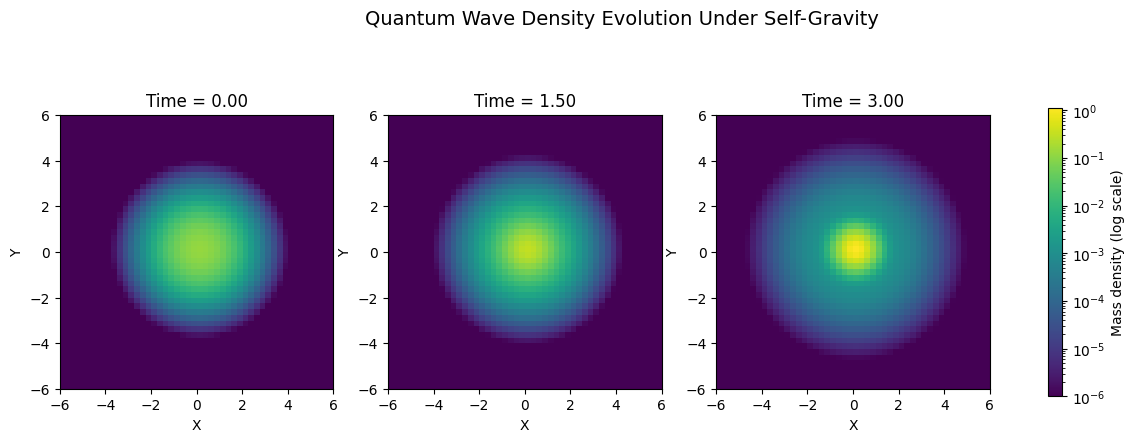

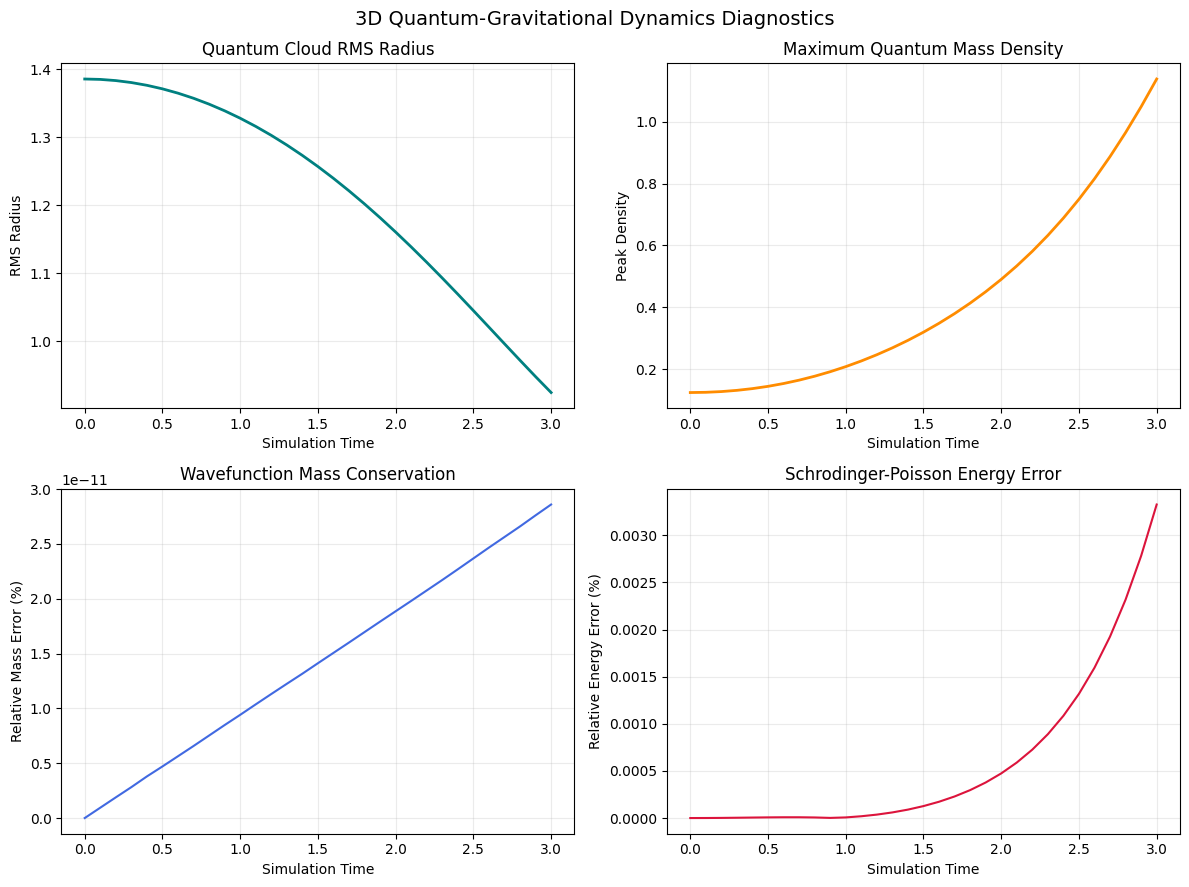

In [24]:

# ============================================================
# QUANTUM-WAVE SELF-GRAVITY
# CELL 23: SCHRODINGER-POISSON TIME EVOLUTION
# METHOD: STRANG SPLIT-STEP FOURIER INTEGRATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ---------- SIMULATION PARAMETERS ----------

DT23 = 0.01
STEPS23 = 300
SAVE23 = 10

# Preserve initial quantum state
psi23 = psiQ.copy()

# Fourier-space kinetic evolution operator
kinetic_phase23 = np.exp(
    -1j * HBAR_Q * K2Q * DT23 / 2.0
)

radius_squared23 = XQ**2 + YQ**2 + ZQ**2

# Outer layer diagnostic for periodic boundary effects
boundary_mask23 = (
    (np.abs(XQ) > LQ/2 - 2*DXQ)
    | (np.abs(YQ) > LQ/2 - 2*DXQ)
    | (np.abs(ZQ) > LQ/2 - 2*DXQ)
)

# ---------- QUANTUM DIAGNOSTICS ----------

def diagnostics23(psi, phi):

    density = np.abs(psi)**2

    mass = np.sum(density) * DXQ**3

    # Spectral kinetic energy
    psi_k = np.fft.fftn(psi)

    kinetic = (
        0.5 * HBAR_Q**2
        * DXQ**3 / NQ**3
        * np.sum(K2Q * np.abs(psi_k)**2)
    )

    gravitational = (
        0.5 * np.sum(density * phi) * DXQ**3
    )

    energy = kinetic + gravitational

    rms_radius = np.sqrt(
        np.sum(radius_squared23 * density)
        * DXQ**3 / mass
    )

    peak_density = np.max(density)

    boundary_fraction = (
        np.sum(density[boundary_mask23])
        * DXQ**3 / mass
    )

    return (
        mass,
        energy,
        rms_radius,
        peak_density,
        boundary_fraction
    )


# ---------- INITIAL CONDITIONS ----------

phi23 = solve_poisson_Q(np.abs(psi23)**2)

initial_diagnostics23 = diagnostics23(psi23, phi23)

times23 = []
masses23 = []
energies23 = []
radii23 = []
peaks23 = []
boundaries23 = []

snapshot_steps23 = [0, STEPS23//2, STEPS23]
snapshots23 = {}

# ---------- EVOLVE SCHRODINGER-POISSON SYSTEM ----------

for step in range(STEPS23 + 1):

    if step % SAVE23 == 0:

        mass, energy, radius, peak, boundary = (
            diagnostics23(psi23, phi23)
        )

        times23.append(step * DT23)
        masses23.append(mass)
        energies23.append(energy)
        radii23.append(radius)
        peaks23.append(peak)
        boundaries23.append(boundary)

    if step in snapshot_steps23:
        snapshots23[step] = np.abs(psi23)**2

    if step == STEPS23:
        break

    # STEP A: Half gravitational-potential evolution
    psi23 *= np.exp(
        -0.5j * DT23 * phi23 / HBAR_Q
    )

    # STEP B: Full quantum kinetic evolution
    psi23 = np.fft.ifftn(
        np.fft.fftn(psi23) * kinetic_phase23
    )

    # STEP C: Update self-consistent gravitational potential
    density_new23 = np.abs(psi23)**2

    phi_new23 = solve_poisson_Q(density_new23)

    # STEP D: Final half gravitational-potential evolution
    psi23 *= np.exp(
        -0.5j * DT23 * phi_new23 / HBAR_Q
    )

    phi23 = phi_new23


# ---------- CONVERT RESULTS TO ARRAYS ----------

times23 = np.array(times23)
masses23 = np.array(masses23)
energies23 = np.array(energies23)
radii23 = np.array(radii23)
peaks23 = np.array(peaks23)
boundaries23 = np.array(boundaries23)

mass_error23 = (
    np.abs(masses23 - masses23[0])
    / masses23[0]
) * 100

energy_error23 = (
    np.abs(energies23 - energies23[0])
    / abs(energies23[0])
) * 100

# ---------- VALIDATION ----------

assert np.all(np.isfinite(energies23))
assert np.all(np.isfinite(radii23))
assert np.all(np.isfinite(peaks23))
assert np.all(np.isfinite(mass_error23))

# ---------- NUMERICAL RESULTS ----------

print("3D SCHRODINGER-POISSON TIME EVOLUTION")
print("=" * 58)

print(f"Time step: {DT23}")
print(f"Completed steps: {STEPS23}")
print(f"Final time: {times23[-1]:.4f}")

print("\nMASS CONSERVATION")
print("-" * 45)

print(f"Initial mass: {masses23[0]:.10f}")
print(f"Final mass  : {masses23[-1]:.10f}")
print(f"Maximum mass error: {np.max(mass_error23):.8e}%")

print("\nENERGY CONSERVATION")
print("-" * 45)

print(f"Initial energy: {energies23[0]:.8f}")
print(f"Final energy  : {energies23[-1]:.8f}")
print(f"Maximum energy error: {np.max(energy_error23):.6f}%")

print("\nQUANTUM-GRAVITATIONAL CONCENTRATION")
print("-" * 45)

print(f"Initial RMS radius: {radii23[0]:.6f}")
print(f"Final RMS radius  : {radii23[-1]:.6f}")

print(f"Initial peak density: {peaks23[0]:.6f}")
print(f"Final peak density  : {peaks23[-1]:.6f}")

print(
    "Final boundary mass fraction:",
    f"{boundaries23[-1]:.6e}"
)


# ---------- GRAPH 1: QUANTUM MASS DENSITY SNAPSHOTS ----------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

max_density23 = max(
    np.max(snapshots23[s])
    for s in snapshot_steps23
)

for ax, step in zip(axes, snapshot_steps23):

    density_slice = snapshots23[step][:, :, NQ//2]

    im = ax.imshow(
        density_slice.T,
        origin="lower",
        extent=[-LQ/2, LQ/2, -LQ/2, LQ/2],
        cmap="viridis",
        norm=LogNorm(
            vmin=1e-6,
            vmax=max_density23
        )
    )

    ax.set_title(f"Time = {step * DT23:.2f}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")

fig.colorbar(
    im,
    ax=axes,
    label="Mass density (log scale)",
    shrink=0.75
)

plt.suptitle(
    "Quantum Wave Density Evolution Under Self-Gravity",
    fontsize=14
)

plt.show()


# ---------- GRAPH 2: NUMERICAL AND PHYSICAL DIAGNOSTICS ----------

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].plot(
    times23, radii23,
    color="teal",
    linewidth=2
)

axes[0, 0].set_title("Quantum Cloud RMS Radius")
axes[0, 0].set_ylabel("RMS Radius")

axes[0, 1].plot(
    times23, peaks23,
    color="darkorange",
    linewidth=2
)

axes[0, 1].set_title("Maximum Quantum Mass Density")
axes[0, 1].set_ylabel("Peak Density")

axes[1, 0].plot(
    times23, mass_error23,
    color="royalblue"
)

axes[1, 0].set_title("Wavefunction Mass Conservation")
axes[1, 0].set_ylabel("Relative Mass Error (%)")

axes[1, 1].plot(
    times23, energy_error23,
    color="crimson"
)

axes[1, 1].set_title("Schrodinger-Poisson Energy Error")
axes[1, 1].set_ylabel("Relative Energy Error (%)")

for ax in axes.flat:
    ax.set_xlabel("Simulation Time")
    ax.grid(alpha=0.25)

plt.suptitle(
    "3D Quantum-Gravitational Dynamics Diagnostics",
    fontsize=14
)

plt.tight_layout()
plt.show()



Running hbar = 0.40: gravity ON
Running hbar = 0.40: gravity OFF
Running hbar = 0.55: gravity ON
Running hbar = 0.55: gravity OFF
Running hbar = 0.70: gravity ON
Running hbar = 0.70: gravity OFF
Running hbar = 0.85: gravity ON
Running hbar = 0.85: gravity OFF

QUANTUM DISPERSION VS GRAVITY
hbar     Initial E     Gravity R/R0     Free R/R0      Peak ratio    Max E error %
---------------------------------------------------------------------------------------
0.40     -0.142975     0.667327         1.370732       9.182597      0.003327
0.55     -0.059479     1.030831         1.631465       1.384875      0.000624
0.70     0.050385      1.406418         1.921221       0.457233      0.000997
0.85     0.186615      1.778899         2.227237       0.208858      0.000562

FREE WAVE GAUSSIAN CHECK
----------------------------------------------------------------
hbar=0.40: Numerical final RMS=1.899342, Infinite-space reference=1.899342
hbar=0.55: Numerical final RMS=2.260624, Infinite-space refe

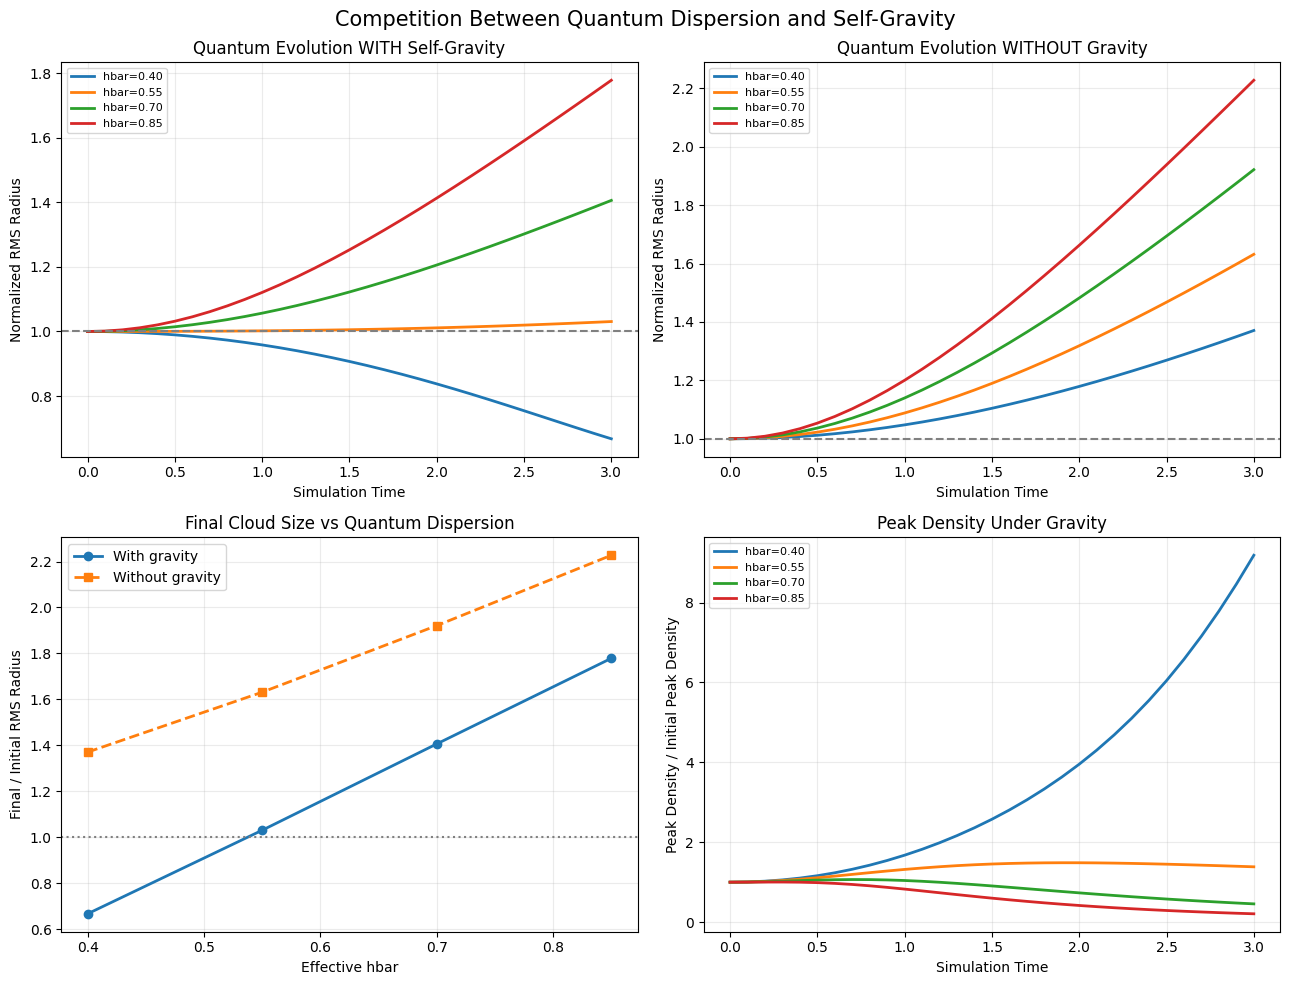


NUMERICAL VALIDATION
Simulations completed: 8
Maximum relative mass error: 2.859935e-11%
Maximum relative energy error: 0.003327%
Maximum sampled boundary mass fraction: 6.264470e-03
Boundary diagnostic: below 1% at sampled times.


In [25]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# PHASE 7: QUANTUM WAVE DYNAMICS
# CELL 24: QUANTUM DISPERSION VS SELF-GRAVITY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- EXPERIMENT PARAMETERS ----------

HBAR_VALUES24 = [0.40, 0.55, 0.70, 0.85]

DT24 = 0.01
STEPS24 = 300
SAVE24 = 10

TIME24 = np.arange(0, STEPS24 + 1, SAVE24) * DT24

# Preserve the initial state from Cell 22
initial_psi24 = psiQ.copy()

R2_24 = XQ**2 + YQ**2 + ZQ**2

boundary_mask24 = (
    (np.abs(XQ) > LQ/2 - 2*DXQ)
    | (np.abs(YQ) > LQ/2 - 2*DXQ)
    | (np.abs(ZQ) > LQ/2 - 2*DXQ)
)

# ---------- QUANTUM ENERGY AND STRUCTURE ----------

def diagnostics24(psi, phi, hbar):

    rho = np.abs(psi)**2

    mass = np.sum(rho) * DXQ**3

    psi_k = np.fft.fftn(psi)

    kinetic = (
        0.5 * hbar**2
        * DXQ**3 / NQ**3
        * np.sum(K2Q * np.abs(psi_k)**2)
    )

    gravitational = (
        0.5 * np.sum(rho * phi) * DXQ**3
    )

    energy = kinetic + gravitational

    radius = np.sqrt(
        np.sum(R2_24 * rho) * DXQ**3 / mass
    )

    peak_density = np.max(rho)

    boundary_mass = (
        np.sum(rho[boundary_mask24])
        * DXQ**3 / mass
    )

    return mass, energy, radius, peak_density, boundary_mass


# ---------- ONE SCHRODINGER EVOLUTION ----------

def run_quantum24(hbar, gravity_on=True):

    psi = initial_psi24.copy()

    kinetic_operator = np.exp(
        -0.5j * hbar * K2Q * DT24
    )

    if gravity_on:
        phi = solve_poisson_Q(np.abs(psi)**2)
    else:
        phi = np.zeros_like(psi.real)

    mass_values = []
    energy_values = []
    radius_values = []
    peak_values = []
    boundary_values = []

    for step in range(STEPS24 + 1):

        if step % SAVE24 == 0:

            mass, energy, radius, peak, boundary = (
                diagnostics24(psi, phi, hbar)
            )

            mass_values.append(mass)
            energy_values.append(energy)
            radius_values.append(radius)
            peak_values.append(peak)
            boundary_values.append(boundary)

        if step == STEPS24:
            break

        # HALF STEP: GRAVITATIONAL POTENTIAL
        if gravity_on:
            psi *= np.exp(
                -0.5j * DT24 * phi / hbar
            )

        # FULL STEP: QUANTUM KINETIC OPERATOR
        psi = np.fft.ifftn(
            np.fft.fftn(psi) * kinetic_operator
        )

        # UPDATE SELF-GRAVITY
        if gravity_on:

            phi_new = solve_poisson_Q(
                np.abs(psi)**2
            )

            # FINAL HALF POTENTIAL STEP
            psi *= np.exp(
                -0.5j * DT24 * phi_new / hbar
            )

            phi = phi_new

    mass_values = np.array(mass_values)
    energy_values = np.array(energy_values)
    radius_values = np.array(radius_values)
    peak_values = np.array(peak_values)
    boundary_values = np.array(boundary_values)

    mass_error = (
        100.0 * np.abs(mass_values - mass_values[0])
        / mass_values[0]
    )

    energy_error = (
        100.0 * np.abs(
            energy_values - energy_values[0]
        )
        / max(abs(energy_values[0]), 1e-12)
    )

    assert np.all(np.isfinite(radius_values))
    assert np.all(np.isfinite(energy_values))
    assert np.all(np.isfinite(mass_values))

    return {
        "radius": radius_values,
        "peak": peak_values,
        "mass": mass_values,
        "energy": energy_values,
        "mass_error": mass_error,
        "energy_error": energy_error,
        "boundary": boundary_values,
        "final_density": np.abs(psi)**2,
        "initial_energy": energy_values[0]
    }


# ---------- RUN ALL 8 SIMULATIONS ----------

results24 = {}

for hbar in HBAR_VALUES24:

    print(f"Running hbar = {hbar:.2f}: gravity ON")

    results24[(hbar, True)] = run_quantum24(
        hbar, gravity_on=True
    )

    print(f"Running hbar = {hbar:.2f}: gravity OFF")

    results24[(hbar, False)] = run_quantum24(
        hbar, gravity_on=False
    )


# ---------- PRINT COMPARATIVE RESULTS ----------

print("\nQUANTUM DISPERSION VS GRAVITY")
print("=" * 87)

print(
    f"{'hbar':<9}"
    f"{'Initial E':<14}"
    f"{'Gravity R/R0':<17}"
    f"{'Free R/R0':<15}"
    f"{'Peak ratio':<14}"
    f"{'Max E error %'}"
)

print("-" * 87)

for hbar in HBAR_VALUES24:

    grav = results24[(hbar, True)]
    free = results24[(hbar, False)]

    radius_ratio_grav = (
        grav["radius"][-1] / grav["radius"][0]
    )

    radius_ratio_free = (
        free["radius"][-1] / free["radius"][0]
    )

    peak_ratio = (
        grav["peak"][-1] / grav["peak"][0]
    )

    print(
        f"{hbar:<9.2f}"
        f"{grav['initial_energy']:<14.6f}"
        f"{radius_ratio_grav:<17.6f}"
        f"{radius_ratio_free:<15.6f}"
        f"{peak_ratio:<14.6f}"
        f"{np.max(grav['energy_error']):.6f}"
    )


# ---------- FREE GAUSSIAN ANALYTICAL CHECK ----------

print("\nFREE WAVE GAUSSIAN CHECK")
print("-" * 64)

for hbar in HBAR_VALUES24:

    free = results24[(hbar, False)]

    # Exact free Gaussian width in infinite space
    sigma_final = np.sqrt(
        SIGMA_Q**2
        + (hbar * TIME24[-1] / (2*SIGMA_Q))**2
    )

    analytic_rms = np.sqrt(3.0) * sigma_final

    print(
        f"hbar={hbar:.2f}: "
        f"Numerical final RMS={free['radius'][-1]:.6f}, "
        f"Infinite-space reference={analytic_rms:.6f}"
    )


# ---------- GRAPH 1: CLOUD RADIUS ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for hbar in HBAR_VALUES24:

    grav = results24[(hbar, True)]
    free = results24[(hbar, False)]

    axes[0, 0].plot(
        TIME24,
        grav["radius"] / grav["radius"][0],
        linewidth=2,
        label=f"hbar={hbar:.2f}"
    )

    axes[0, 1].plot(
        TIME24,
        free["radius"] / free["radius"][0],
        linewidth=2,
        label=f"hbar={hbar:.2f}"
    )

axes[0, 0].axhline(
    1, linestyle="--", color="gray"
)

axes[0, 1].axhline(
    1, linestyle="--", color="gray"
)

axes[0, 0].set_title("Quantum Evolution WITH Self-Gravity")
axes[0, 1].set_title("Quantum Evolution WITHOUT Gravity")

axes[0, 0].set_ylabel("Normalized RMS Radius")
axes[0, 1].set_ylabel("Normalized RMS Radius")

axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8)


# ---------- GRAPH 3: FINAL CLOUD SIZE ----------

grav_final24 = [
    results24[(h, True)]["radius"][-1]
    / results24[(h, True)]["radius"][0]
    for h in HBAR_VALUES24
]

free_final24 = [
    results24[(h, False)]["radius"][-1]
    / results24[(h, False)]["radius"][0]
    for h in HBAR_VALUES24
]

axes[1, 0].plot(
    HBAR_VALUES24,
    grav_final24,
    "o-",
    linewidth=2,
    label="With gravity"
)

axes[1, 0].plot(
    HBAR_VALUES24,
    free_final24,
    "s--",
    linewidth=2,
    label="Without gravity"
)

axes[1, 0].axhline(
    1, linestyle=":", color="gray"
)

axes[1, 0].set_title("Final Cloud Size vs Quantum Dispersion")
axes[1, 0].set_xlabel("Effective hbar")
axes[1, 0].set_ylabel("Final / Initial RMS Radius")
axes[1, 0].legend()


# ---------- GRAPH 4: PEAK DENSITY ----------

for hbar in HBAR_VALUES24:

    grav = results24[(hbar, True)]

    axes[1, 1].plot(
        TIME24,
        grav["peak"] / grav["peak"][0],
        linewidth=2,
        label=f"hbar={hbar:.2f}"
    )

axes[1, 1].set_title("Peak Density Under Gravity")
axes[1, 1].set_xlabel("Simulation Time")
axes[1, 1].set_ylabel("Peak Density / Initial Peak Density")
axes[1, 1].legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.25)
    if ax in [axes[0, 0], axes[0, 1]]:
        ax.set_xlabel("Simulation Time")

plt.suptitle(
    "Competition Between Quantum Dispersion and Self-Gravity",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ---------- GLOBAL NUMERICAL CHECKS ----------

max_mass_error24 = max(
    np.max(r["mass_error"])
    for r in results24.values()
)

max_energy_error24 = max(
    np.max(r["energy_error"])
    for r in results24.values()
)

max_boundary24 = max(
    np.max(r["boundary"])
    for r in results24.values()
)

print("\nNUMERICAL VALIDATION")
print("=" * 55)

print("Simulations completed:", len(results24))

print(
    "Maximum relative mass error:",
    f"{max_mass_error24:.6e}%"
)

print(
    "Maximum relative energy error:",
    f"{max_energy_error24:.6f}%"
)

print(
    "Maximum sampled boundary mass fraction:",
    f"{max_boundary24:.6e}"
)

if max_boundary24 > 0.01:
    print("WARNING: Periodic boundary effects require checking.")
else:
    print("Boundary diagnostic: below 1% at sampled times.")

if max_energy_error24 > 0.1:
    print("WARNING: Energy convergence needs investigation.")



Grid 32^3, hbar=0.40, dt=0.010
Grid 48^3, hbar=0.40, dt=0.010
Grid 64^3, hbar=0.40, dt=0.010
Grid 32^3, hbar=0.55, dt=0.010
Grid 48^3, hbar=0.55, dt=0.010
Grid 64^3, hbar=0.55, dt=0.010
Time-step refinement: N=48, dt=0.0200
Time-step refinement: N=48, dt=0.0050

SPATIAL GRID CONVERGENCE
hbar     Grid       Final R/R0       Peak ratio       Max E error (%)
--------------------------------------------------------------------------------
0.40     32         0.66726894       9.21986738       0.00336310
0.40     48         0.66732698       9.18259656       0.00332696
0.40     64         0.66732698       9.18231273       0.00332686
0.55     32         1.03083358       1.38487638       0.00062398
0.55     48         1.03083112       1.38487517       0.00062398
0.55     64         1.03083029       1.38487507       0.00062398

TIME-STEP CONVERGENCE: hbar = 0.40
dt            Final R/R0          Peak ratio          Max E error (%)
-----------------------------------------------------------------

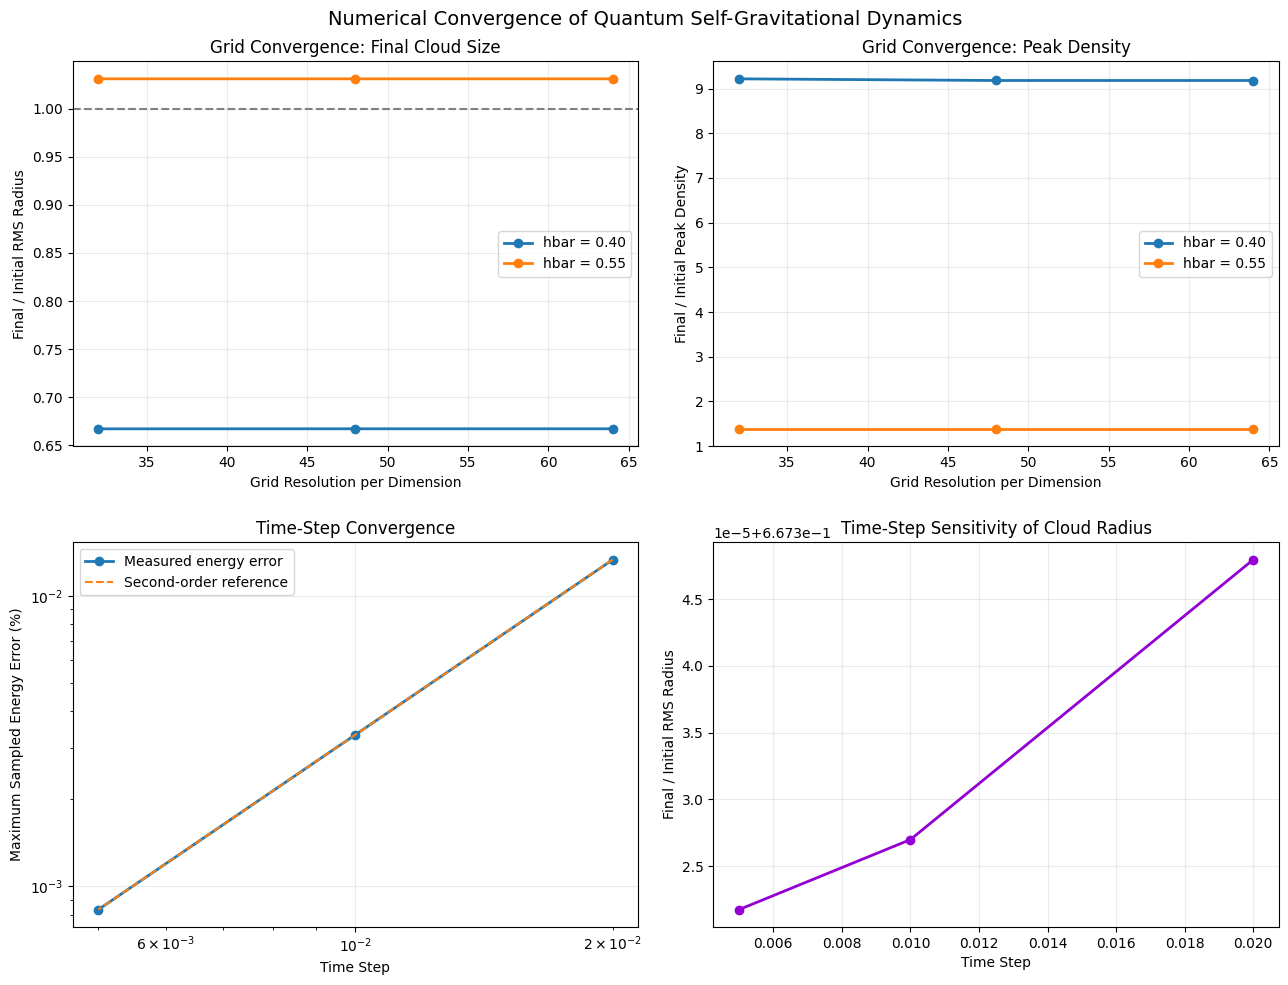


QUANTUM CONVERGENCE VALIDATION
Total simulations: 8
Maximum sampled mass error: 5.49560397e-11%
Maximum sampled energy error: 0.013299%
hbar=0.40, all grids contract: True
hbar=0.40, all grids expand: False
hbar=0.55, all grids contract: False
hbar=0.55, all grids expand: True


In [26]:

# ============================================================
# CLASSICAL AND QUANTUM GRAVITATIONAL DYNAMICS
# CELL 25: QUANTUM NUMERICAL CONVERGENCE
# Grid resolution and time-step validation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- TEST SETTINGS ----------

GRIDS25 = [32, 48, 64]
HBARS25 = [0.40, 0.55]
DTS25 = [0.020, 0.010, 0.005]

FINAL_TIME25 = 3.0

# ---------- INDEPENDENT SCHRODINGER-POISSON SOLVER ----------

def run_convergence25(n, dt, hbar):

    dx = LQ / n

    coord = (np.arange(n) - n//2) * dx

    x, y, z = np.meshgrid(
        coord, coord, coord, indexing="ij"
    )

    r2 = x*x + y*y + z*z

    # Initial Gaussian wavefunction
    psi = np.exp(
        -r2 / (4.0 * SIGMA_Q**2)
    ).astype(np.complex128)

    psi *= np.sqrt(
        MASS_Q / (np.sum(np.abs(psi)**2) * dx**3)
    )

    # Fourier grid
    k = 2.0 * np.pi * np.fft.fftfreq(n, d=dx)

    kx, ky, kz = np.meshgrid(
        k, k, k, indexing="ij"
    )

    k2 = kx*kx + ky*ky + kz*kz

    poisson_kernel = np.zeros_like(k2)

    nonzero = k2 > 0

    poisson_kernel[nonzero] = (
        -4.0 * np.pi * GQ / k2[nonzero]
    )

    # Periodic Poisson equation
    def potential(density):
        return np.fft.ifftn(
            np.fft.fftn(density) * poisson_kernel
        ).real

    # Numerical diagnostics
    def measure(psi, phi):

        rho = np.abs(psi)**2

        mass = np.sum(rho) * dx**3

        psi_k = np.fft.fftn(psi)

        kinetic = (
            0.5 * hbar**2 * dx**3 / n**3
            * np.sum(k2 * np.abs(psi_k)**2)
        )

        gravitational = (
            0.5 * np.sum(rho * phi) * dx**3
        )

        total_energy = kinetic + gravitational

        radius = np.sqrt(
            np.sum(r2 * rho) * dx**3 / mass
        )

        peak = np.max(rho)

        return mass, total_energy, radius, peak

    phi = potential(np.abs(psi)**2)

    m0, E0, R0, P0 = measure(psi, phi)

    kinetic_phase = np.exp(
        -0.5j * hbar * k2 * dt
    )

    steps = int(round(FINAL_TIME25 / dt))

    assert np.isclose(steps * dt, FINAL_TIME25)

    max_energy_error = 0.0
    max_mass_error = 0.0

    sample_every = max(1, steps // 30)

    # ---------- STRANG SPLITTING ----------

    for step in range(steps):

        # Half gravitational step
        psi *= np.exp(
            -0.5j * dt * phi / hbar
        )

        # Full quantum kinetic step
        psi = np.fft.ifftn(
            np.fft.fftn(psi) * kinetic_phase
        )

        # Self-consistent gravitational potential
        phi = potential(np.abs(psi)**2)

        # Final half gravitational step
        psi *= np.exp(
            -0.5j * dt * phi / hbar
        )

        # Sample numerical errors
        if (
            (step + 1) % sample_every == 0
            or step == steps - 1
        ):

            m, E, R, P = measure(psi, phi)

            mass_error = (
                100 * abs(m - m0) / m0
            )

            energy_error = (
                100 * abs(E - E0) / abs(E0)
            )

            max_mass_error = max(
                max_mass_error, mass_error
            )

            max_energy_error = max(
                max_energy_error, energy_error
            )

    m, E, R, P = measure(psi, phi)

    assert np.isfinite(R)
    assert np.isfinite(P)
    assert np.isfinite(E)
    assert m > 0

    return {
        "n": n,
        "dt": dt,
        "hbar": hbar,
        "R_ratio": R/R0,
        "P_ratio": P/P0,
        "R_final": R,
        "P_final": P,
        "mass_error": max_mass_error,
        "energy_error": max_energy_error
    }


# ---------- PART A: SPATIAL GRID CONVERGENCE ----------

grid_results25 = {}

for hbar in HBARS25:

    for n in GRIDS25:

        print(
            f"Grid {n}^3, "
            f"hbar={hbar:.2f}, dt=0.010"
        )

        grid_results25[(hbar, n)] = (
            run_convergence25(n, 0.010, hbar)
        )


# ---------- PART B: TIME-STEP CONVERGENCE ----------

dt_results25 = {}

# Reuse the N=48, dt=0.010 result
dt_results25[0.010] = grid_results25[(0.40, 48)]

for dt in [0.020, 0.005]:

    print(
        f"Time-step refinement: "
        f"N=48, dt={dt:.4f}"
    )

    dt_results25[dt] = run_convergence25(
        48, dt, 0.40
    )


# ---------- SPATIAL GRID RESULTS ----------

print("\nSPATIAL GRID CONVERGENCE")
print("=" * 80)

print(
    f"{'hbar':<9}"
    f"{'Grid':<11}"
    f"{'Final R/R0':<17}"
    f"{'Peak ratio':<17}"
    f"{'Max E error (%)'}"
)

print("-" * 80)

for hbar in HBARS25:

    for n in GRIDS25:

        r = grid_results25[(hbar, n)]

        print(
            f"{hbar:<9.2f}"
            f"{n:<11}"
            f"{r['R_ratio']:<17.8f}"
            f"{r['P_ratio']:<17.8f}"
            f"{r['energy_error']:.8f}"
        )


# ---------- TIME-STEP RESULTS ----------

print("\nTIME-STEP CONVERGENCE: hbar = 0.40")
print("=" * 75)

print(
    f"{'dt':<14}"
    f"{'Final R/R0':<20}"
    f"{'Peak ratio':<20}"
    f"{'Max E error (%)'}"
)

print("-" * 75)

for dt in DTS25:

    r = dt_results25[dt]

    print(
        f"{dt:<14.5f}"
        f"{r['R_ratio']:<20.8f}"
        f"{r['P_ratio']:<20.8f}"
        f"{r['energy_error']:.8f}"
    )


# ---------- CONVERGENCE QUANTIFICATION ----------

print("\nGRID CONVERGENCE: 48^3 vs 64^3")
print("=" * 55)

for hbar in HBARS25:

    a = grid_results25[(hbar, 48)]
    b = grid_results25[(hbar, 64)]

    radius_difference = (
        100 * abs(a["R_ratio"] - b["R_ratio"])
        / abs(b["R_ratio"])
    )

    peak_difference = (
        100 * abs(a["P_ratio"] - b["P_ratio"])
        / abs(b["P_ratio"])
    )

    print(f"\nhbar = {hbar:.2f}")
    print(f"Radius difference: {radius_difference:.6f}%")
    print(f"Peak difference  : {peak_difference:.6f}%")


# ---------- VISUALIZATION ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Graph 1: Grid convergence of radius
for hbar in HBARS25:

    values = [
        grid_results25[(hbar, n)]["R_ratio"]
        for n in GRIDS25
    ]

    axes[0, 0].plot(
        GRIDS25, values, "o-",
        linewidth=2,
        label=f"hbar = {hbar:.2f}"
    )

axes[0, 0].axhline(
    1.0, color="gray", linestyle="--"
)

axes[0, 0].set_title("Grid Convergence: Final Cloud Size")
axes[0, 0].set_xlabel("Grid Resolution per Dimension")
axes[0, 0].set_ylabel("Final / Initial RMS Radius")
axes[0, 0].legend()

# Graph 2: Grid convergence of peak density
for hbar in HBARS25:

    values = [
        grid_results25[(hbar, n)]["P_ratio"]
        for n in GRIDS25
    ]

    axes[0, 1].plot(
        GRIDS25, values, "o-",
        linewidth=2,
        label=f"hbar = {hbar:.2f}"
    )

axes[0, 1].set_title("Grid Convergence: Peak Density")
axes[0, 1].set_xlabel("Grid Resolution per Dimension")
axes[0, 1].set_ylabel("Final / Initial Peak Density")
axes[0, 1].legend()

# Graph 3: Time-step energy error
errors = np.array([
    dt_results25[dt]["energy_error"]
    for dt in DTS25
])

axes[1, 0].loglog(
    DTS25, errors,
    "o-", linewidth=2,
    label="Measured energy error"
)

reference = errors[-1] * (
    np.array(DTS25) / DTS25[-1]
)**2

axes[1, 0].loglog(
    DTS25, reference,
    "--", label="Second-order reference"
)

axes[1, 0].set_title("Time-Step Convergence")
axes[1, 0].set_xlabel("Time Step")
axes[1, 0].set_ylabel("Maximum Sampled Energy Error (%)")
axes[1, 0].legend()

# Graph 4: Time-step convergence of radius
radius_values = [
    dt_results25[dt]["R_ratio"]
    for dt in DTS25
]

axes[1, 1].plot(
    DTS25,
    radius_values,
    "o-",
    linewidth=2,
    color="darkviolet"
)

axes[1, 1].set_title("Time-Step Sensitivity of Cloud Radius")
axes[1, 1].set_xlabel("Time Step")
axes[1, 1].set_ylabel("Final / Initial RMS Radius")

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.suptitle(
    "Numerical Convergence of Quantum Self-Gravitational Dynamics",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ---------- VALIDATION SUMMARY ----------

all_runs25 = list(grid_results25.values()) + [
    dt_results25[0.020],
    dt_results25[0.005]
]

max_mass_error25 = max(
    r["mass_error"] for r in all_runs25
)

max_energy_error25 = max(
    r["energy_error"] for r in all_runs25
)

print("\nQUANTUM CONVERGENCE VALIDATION")
print("=" * 55)

print("Total simulations:", len(all_runs25))

print(
    "Maximum sampled mass error:",
    f"{max_mass_error25:.8e}%"
)

print(
    "Maximum sampled energy error:",
    f"{max_energy_error25:.6f}%"
)

for hbar in HBARS25:

    ratios = [
        grid_results25[(hbar, n)]["R_ratio"]
        for n in GRIDS25
    ]

    print(
        f"hbar={hbar:.2f}, "
        f"all grids contract:",
        bool(all(r < 1 for r in ratios))
    )

    print(
        f"hbar={hbar:.2f}, "
        f"all grids expand:",
        bool(all(r > 1 for r in ratios))
    )



QUANTUM STRUCTURE AND DENSITY ANALYSIS
Initial half-mass radius : 1.250000
Initial RMS radius       : 1.385641
Initial inner mass (%)  : 20.9906

FINAL STRUCTURE WITH SELF-GRAVITY
------------------------------------------------------------------------------------
hbar      R50          RMS          Peak rho      Inner mass %    Outer mass %
0.40      0.612372     0.924675     1.138743      70.7457         0.0001
0.55      1.145644     1.428361     0.171740      25.5176         0.0063
0.70      1.658312     1.948790     0.056702      10.5570         0.0625
0.85      2.150581     2.464915     0.025901      5.2617          0.2244

GRAVITY ON VS GRAVITY OFF
--------------------------------------------------------------------------------
hbar      R50 ON         R50 OFF        Inner mass ON %    Inner mass OFF %
0.40      0.612372       1.677051       70.7457            9.3785
0.55      1.145644       2.015564       25.5176            5.8354
0.70      1.658312       2.358495       10.5570 

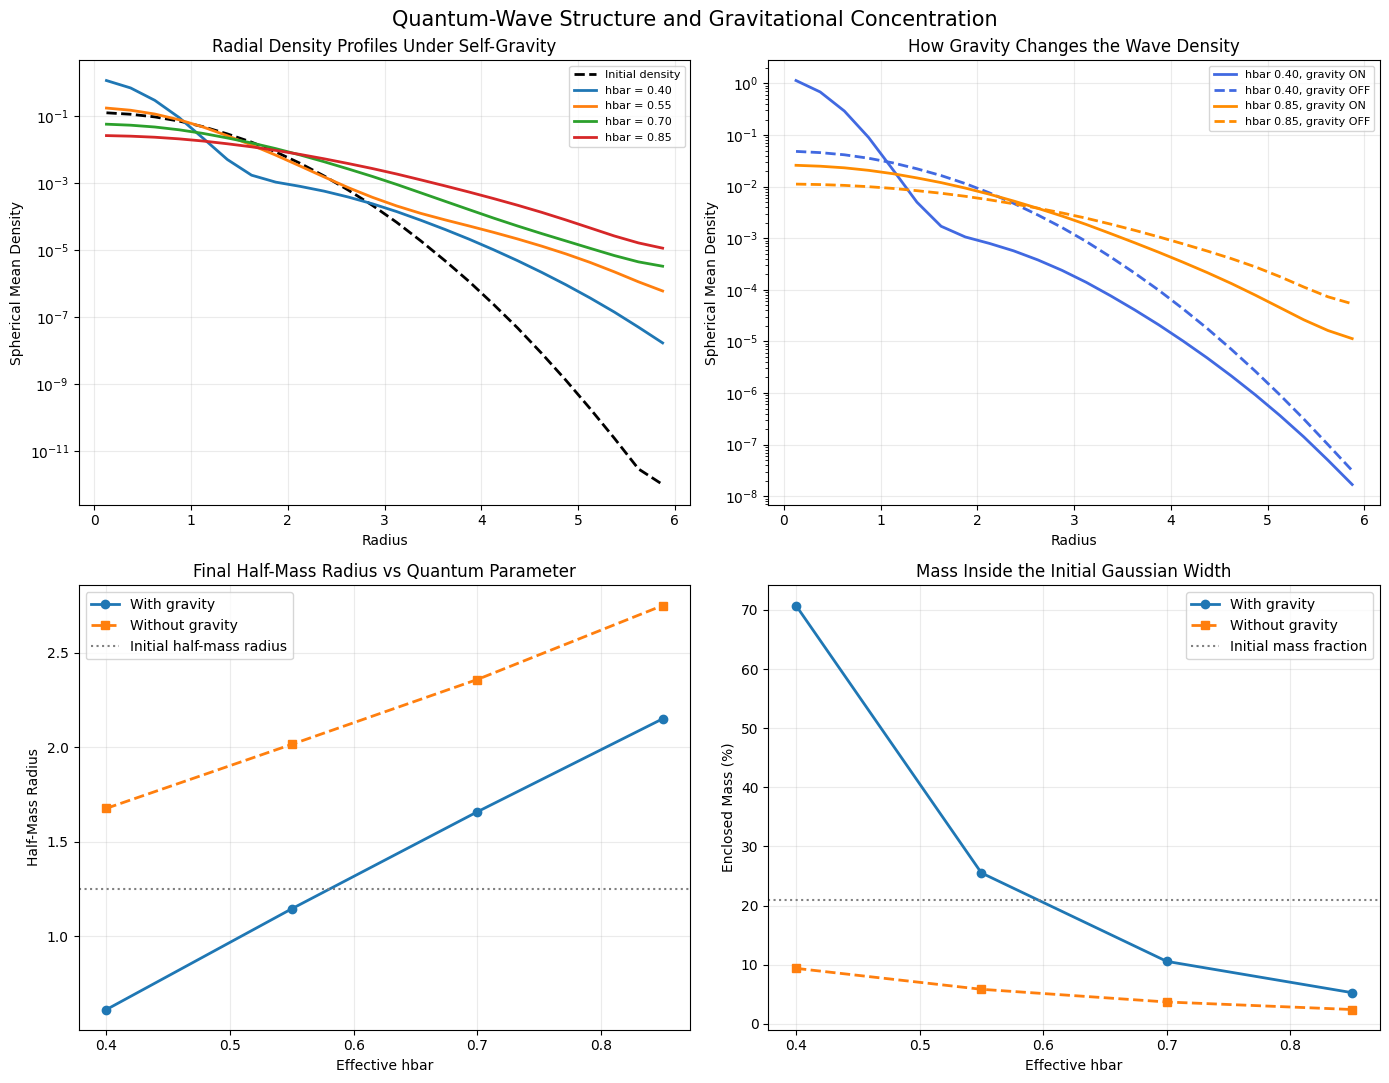

In [27]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 26: QUANTUM STRUCTURE AND DENSITY PROFILES
# Uses existing results from Cell 24
# No new simulations required
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- INITIALIZE RADIAL ANALYSIS ----------

r_grid26 = np.sqrt(XQ**2 + YQ**2 + ZQ**2)
cell_volume26 = DXQ**3

# Radial bins in simulation units
dr26 = DXQ
shell_index26 = np.floor(r_grid26 / dr26).astype(int)

num_shells26 = int(shell_index26.max()) + 1

shell_counts26 = np.bincount(
    shell_index26.ravel(),
    minlength=num_shells26
)

shell_radii26 = (
    np.arange(num_shells26) + 0.5
) * dr26

# Precompute sorting for enclosed-mass measurements
sorted_indices26 = np.argsort(r_grid26.ravel())
sorted_radii26 = r_grid26.ravel()[sorted_indices26]

inner_mask26 = r_grid26 <= SIGMA_Q

# ---------- STRUCTURAL DIAGNOSTIC FUNCTION ----------

def analyze_density26(density):

    density = np.asarray(density, dtype=float)

    assert density.shape == (NQ, NQ, NQ)
    assert np.all(np.isfinite(density))
    assert np.all(density >= 0)

    mass = np.sum(density) * cell_volume26

    # Spherical shell-averaged density
    shell_density_sum = np.bincount(
        shell_index26.ravel(),
        weights=density.ravel(),
        minlength=num_shells26
    )

    radial_profile = (
        shell_density_sum /
        np.maximum(shell_counts26, 1)
    )

    # Calculate radius enclosing half the total mass
    ordered_mass = (
        density.ravel()[sorted_indices26]
        * cell_volume26
    )

    cumulative_mass = np.cumsum(ordered_mass)

    half_mass_radius = np.interp(
        0.5 * mass,
        cumulative_mass,
        sorted_radii26
    )

    # Fraction of total mass inside initial Gaussian width
    inner_mass_fraction = (
        np.sum(density[inner_mask26])
        * cell_volume26 / mass
    )

    center_density = density[
        NQ//2, NQ//2, NQ//2
    ]

    peak_density = np.max(density)

    # Radial RMS extent
    rms_radius = np.sqrt(
        np.sum(r_grid26**2 * density)
        * cell_volume26 / mass
    )

    # Fraction outside the inscribed sphere
    outer_fraction = (
        np.sum(density[r_grid26 > LQ/2])
        * cell_volume26 / mass
    )

    return {
        "mass": mass,
        "profile": radial_profile,
        "r50": half_mass_radius,
        "inner_fraction": inner_mass_fraction,
        "center_density": center_density,
        "peak_density": peak_density,
        "rms": rms_radius,
        "outer_fraction": outer_fraction
    }


# ---------- INITIAL AND FINAL QUANTUM STATES ----------

initial26 = analyze_density26(np.abs(psiQ)**2)

structure26 = {}

for hbar in HBAR_VALUES24:

    for gravity_on in [True, False]:

        density = results24[
            (hbar, gravity_on)
        ]["final_density"]

        structure26[(hbar, gravity_on)] = (
            analyze_density26(density)
        )


# ---------- PRINT MEASUREMENTS ----------

print("QUANTUM STRUCTURE AND DENSITY ANALYSIS")
print("=" * 84)

print(f"Initial half-mass radius : {initial26['r50']:.6f}")
print(f"Initial RMS radius       : {initial26['rms']:.6f}")
print(
    "Initial inner mass (%)  :",
    f"{100 * initial26['inner_fraction']:.4f}"
)

print("\nFINAL STRUCTURE WITH SELF-GRAVITY")
print("-" * 84)

print(
    f"{'hbar':<10}"
    f"{'R50':<13}"
    f"{'RMS':<13}"
    f"{'Peak rho':<14}"
    f"{'Inner mass %':<16}"
    f"{'Outer mass %'}"
)

for hbar in HBAR_VALUES24:

    r = structure26[(hbar, True)]

    print(
        f"{hbar:<10.2f}"
        f"{r['r50']:<13.6f}"
        f"{r['rms']:<13.6f}"
        f"{r['peak_density']:<14.6f}"
        f"{100*r['inner_fraction']:<16.4f}"
        f"{100*r['outer_fraction']:.4f}"
    )


print("\nGRAVITY ON VS GRAVITY OFF")
print("-" * 80)

print(
    f"{'hbar':<10}"
    f"{'R50 ON':<15}"
    f"{'R50 OFF':<15}"
    f"{'Inner mass ON %':<19}"
    f"{'Inner mass OFF %'}"
)

for hbar in HBAR_VALUES24:

    grav = structure26[(hbar, True)]
    free = structure26[(hbar, False)]

    print(
        f"{hbar:<10.2f}"
        f"{grav['r50']:<15.6f}"
        f"{free['r50']:<15.6f}"
        f"{100*grav['inner_fraction']:<19.4f}"
        f"{100*free['inner_fraction']:.4f}"
    )


# ---------- VALIDATE STRUCTURAL MEASUREMENTS ----------

for result in structure26.values():

    assert np.isclose(
        result["mass"], MASS_Q, rtol=1e-8
    )

    assert result["r50"] > 0
    assert result["rms"] > 0

    assert 0 <= result["inner_fraction"] <= 1
    assert 0 <= result["outer_fraction"] <= 1


# ---------- PLOT RADIAL STRUCTURE ----------

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Only show radial shells fully inside the box.
# Beyond L/2, spherical shells are geometrically incomplete.
valid_shells26 = shell_radii26 < LQ/2

# GRAPH 1: ALL SELF-GRAVITATING RADIAL PROFILES

axes[0, 0].semilogy(
    shell_radii26[valid_shells26],
    np.maximum(
        initial26["profile"][valid_shells26],
        1e-12
    ),
    "k--",
    linewidth=2,
    label="Initial density"
)

for hbar in HBAR_VALUES24:

    result = structure26[(hbar, True)]

    axes[0, 0].semilogy(
        shell_radii26[valid_shells26],
        np.maximum(
            result["profile"][valid_shells26],
            1e-12
        ),
        linewidth=2,
        label=f"hbar = {hbar:.2f}"
    )

axes[0, 0].set_title(
    "Radial Density Profiles Under Self-Gravity"
)

axes[0, 0].set_xlabel("Radius")
axes[0, 0].set_ylabel("Spherical Mean Density")
axes[0, 0].legend(fontsize=8)


# GRAPH 2: GRAVITY ON VS OFF FOR TWO CASES

for hbar, color in [(0.40, "royalblue"),
                    (0.85, "darkorange")]:

    gravity_result = structure26[(hbar, True)]
    free_result = structure26[(hbar, False)]

    axes[0, 1].semilogy(
        shell_radii26[valid_shells26],
        np.maximum(
            gravity_result["profile"][valid_shells26],
            1e-12
        ),
        color=color,
        linewidth=2,
        label=f"hbar {hbar:.2f}, gravity ON"
    )

    axes[0, 1].semilogy(
        shell_radii26[valid_shells26],
        np.maximum(
            free_result["profile"][valid_shells26],
            1e-12
        ),
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"hbar {hbar:.2f}, gravity OFF"
    )

axes[0, 1].set_title(
    "How Gravity Changes the Wave Density"
)

axes[0, 1].set_xlabel("Radius")
axes[0, 1].set_ylabel("Spherical Mean Density")
axes[0, 1].legend(fontsize=8)


# GRAPH 3: HALF-MASS RADIUS VS HBAR

r50_gravity26 = [
    structure26[(h, True)]["r50"]
    for h in HBAR_VALUES24
]

r50_free26 = [
    structure26[(h, False)]["r50"]
    for h in HBAR_VALUES24
]

axes[1, 0].plot(
    HBAR_VALUES24,
    r50_gravity26,
    "o-",
    linewidth=2,
    label="With gravity"
)

axes[1, 0].plot(
    HBAR_VALUES24,
    r50_free26,
    "s--",
    linewidth=2,
    label="Without gravity"
)

axes[1, 0].axhline(
    initial26["r50"],
    color="gray",
    linestyle=":",
    label="Initial half-mass radius"
)

axes[1, 0].set_title(
    "Final Half-Mass Radius vs Quantum Parameter"
)

axes[1, 0].set_xlabel("Effective hbar")
axes[1, 0].set_ylabel("Half-Mass Radius")
axes[1, 0].legend()


# GRAPH 4: CENTRAL MASS CONCENTRATION

inner_gravity26 = [
    100 * structure26[(h, True)]["inner_fraction"]
    for h in HBAR_VALUES24
]

inner_free26 = [
    100 * structure26[(h, False)]["inner_fraction"]
    for h in HBAR_VALUES24
]

axes[1, 1].plot(
    HBAR_VALUES24,
    inner_gravity26,
    "o-",
    linewidth=2,
    label="With gravity"
)

axes[1, 1].plot(
    HBAR_VALUES24,
    inner_free26,
    "s--",
    linewidth=2,
    label="Without gravity"
)

axes[1, 1].axhline(
    100 * initial26["inner_fraction"],
    color="gray",
    linestyle=":",
    label="Initial mass fraction"
)

axes[1, 1].set_title(
    "Mass Inside the Initial Gaussian Width"
)

axes[1, 1].set_xlabel("Effective hbar")
axes[1, 1].set_ylabel("Enclosed Mass (%)")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.suptitle(
    "Quantum-Wave Structure and Gravitational Concentration",
    fontsize=15
)

plt.tight_layout()
plt.show()



Running matched classical cloud: seed 2026
Running matched classical cloud: seed 40
Running matched classical cloud: seed 53

MATCHED CLASSICAL PARTICLE-MESH RESULTS
Particles per realization: 4000
Number of seeds: 3
Grid: 48 x 48 x 48
Final time: 3.000

Seed      Final R/R0       Inner mass %      Max E err %
----------------------------------------------------------------------------
2026      0.498068         74.2500           0.094484
40        0.494720         73.9500           0.341944
53        0.492163         73.3750           0.231288

ENSEMBLE RESULTS
--------------------------------------------------
Mean classical final R/R0: 0.494984
Between-seed standard deviation: 0.002961
Mean final classical inner mass: 73.8583%

MATCHED CLASSICAL VS QUANTUM-WAVE RESULTS
Model                    Final R/R0        Inner mass %
--------------------------------------------------------------------
Classical particle-mesh  0.494984          73.8583
Quantum hbar=0.4         0.667327        

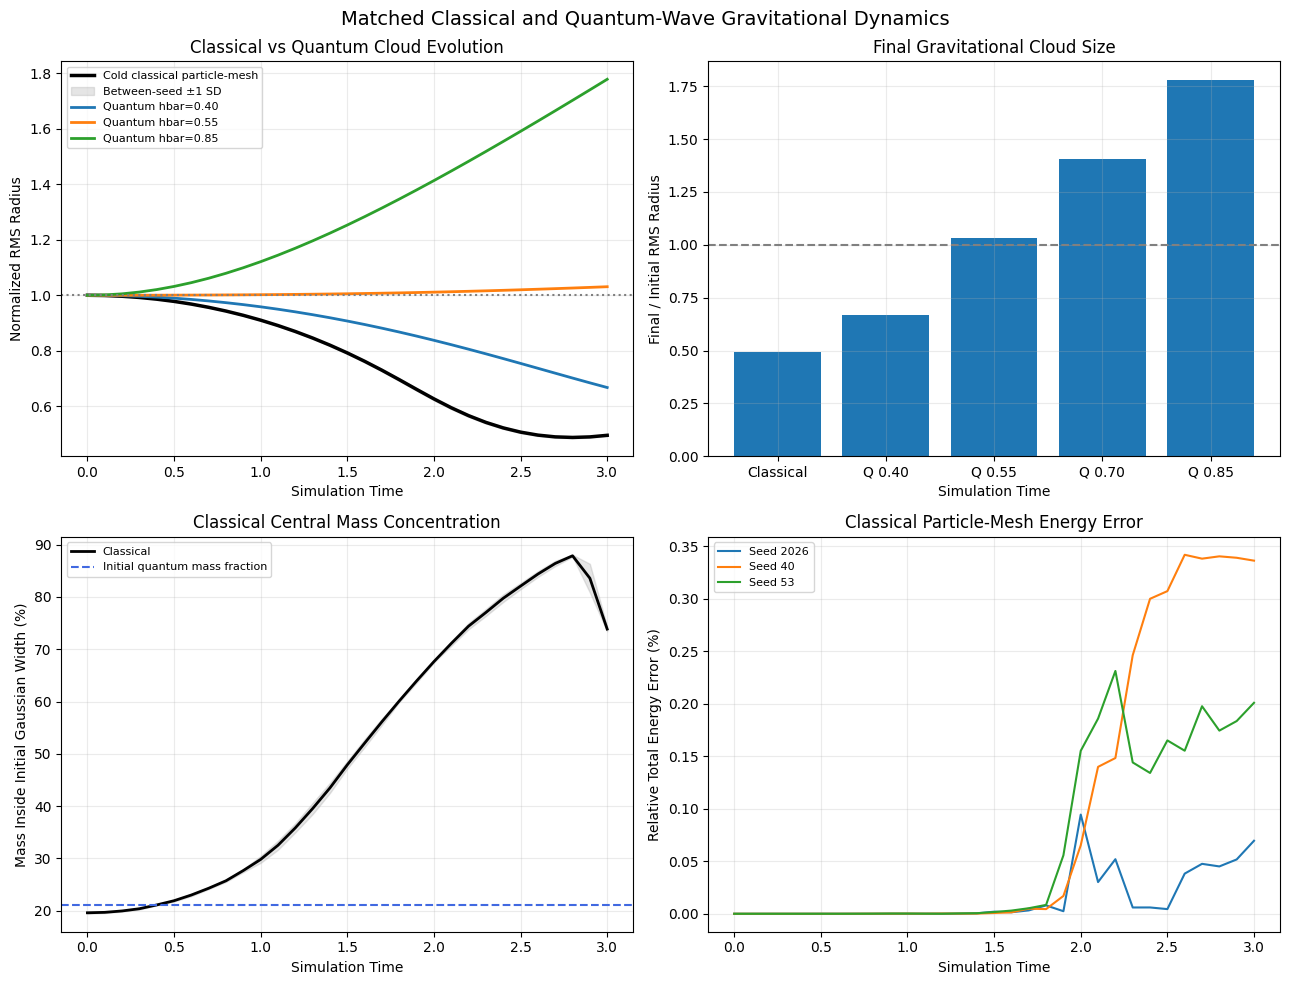


NUMERICAL VALIDATION
Maximum classical mass error: 4.440892e-14%
Maximum classical energy error: 0.341944%
Maximum sampled boundary fraction: 0.000000e+00
Classical energy drift below 1% in sampled states.


In [28]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 27: MATCHED CLASSICAL PARTICLE-MESH COMPARISON
# Periodic 3D Poisson solver + cloud-in-cell (CIC)
# Note: PM energy drift is a measured accuracy limitation; do not call this exact.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- MATCHED PHYSICAL PARAMETERS ----------

NCLASS27 = 4000
SEEDS27 = [2026, 40, 53]

DT27 = 0.005
STEPS27 = 600
SAVE27 = 20

TIME27 = np.arange(
    0, STEPS27 + 1, SAVE27
) * DT27

# Reuse the quantum grid, box, mass and gravity
NG27 = NQ
BOX27 = LQ
DX27 = DXQ
G27 = GQ
MASS27 = MASS_Q
SIGMA27 = SIGMA_Q

M_PARTICLE27 = MASS27 / NCLASS27

assert np.allclose(TIME27, TIME24)

# ---------- FOURIER POISSON KERNEL ----------

KERNEL27 = np.zeros_like(K2Q)
nonzero27 = K2Q > 0

KERNEL27[nonzero27] = (
    -4.0 * np.pi * G27 / K2Q[nonzero27]
)

# ---------- PARTICLE-MESH GRAVITY ----------

def pm_gravity27(pos):

    # Convert positions to periodic grid coordinates
    grid_pos = (
        (pos + BOX27 / 2.0) / DX27
    ) % NG27

    base = np.floor(grid_pos).astype(int)
    frac = grid_pos - base

    ix0, iy0, iz0 = base.T

    # Deposit mass using cloud-in-cell
    rho = np.zeros(
        (NG27, NG27, NG27),
        dtype=float
    )

    for a in (0, 1):

        wx = (
            1.0 - frac[:, 0]
            if a == 0 else frac[:, 0]
        )

        ix = (ix0 + a) % NG27

        for b in (0, 1):

            wy = (
                1.0 - frac[:, 1]
                if b == 0 else frac[:, 1]
            )

            iy = (iy0 + b) % NG27

            for c in (0, 1):

                wz = (
                    1.0 - frac[:, 2]
                    if c == 0 else frac[:, 2]
                )

                iz = (iz0 + c) % NG27

                weight = wx * wy * wz

                np.add.at(
                    rho,
                    (ix, iy, iz),
                    M_PARTICLE27
                    * weight / DX27**3
                )

    # Periodic gravitational potential
    phi_k = np.fft.fftn(rho) * KERNEL27
    phi = np.fft.ifftn(phi_k).real

    # Consistent derivative of the CIC-interpolated
    # potential: acceleration = -grad(Phi)
    acceleration = np.zeros_like(pos)

    for a in (0, 1):

        wx = (
            1.0 - frac[:, 0]
            if a == 0 else frac[:, 0]
        )

        sx = -1.0 if a == 0 else 1.0
        ix = (ix0 + a) % NG27

        for b in (0, 1):

            wy = (
                1.0 - frac[:, 1]
                if b == 0 else frac[:, 1]
            )

            sy = -1.0 if b == 0 else 1.0
            iy = (iy0 + b) % NG27

            for c in (0, 1):

                wz = (
                    1.0 - frac[:, 2]
                    if c == 0 else frac[:, 2]
                )

                sz = -1.0 if c == 0 else 1.0
                iz = (iz0 + c) % NG27

                potential_at_node = phi[ix, iy, iz]

                acceleration[:, 0] -= (
                    potential_at_node
                    * sx * wy * wz / DX27
                )

                acceleration[:, 1] -= (
                    potential_at_node
                    * wx * sy * wz / DX27
                )

                acceleration[:, 2] -= (
                    potential_at_node
                    * wx * wy * sz / DX27
                )

    return acceleration, rho, phi


# ---------- CLASSICAL DIAGNOSTICS ----------

def classical_measure27(pos, vel, rho, phi):

    # Initial cloud is centered at the origin
    distance2 = np.sum(pos**2, axis=1)

    radius = np.sqrt(
        np.mean(distance2)
    )

    central_mass_fraction = np.mean(
        distance2 <= SIGMA27**2
    )

    kinetic = (
        0.5 * M_PARTICLE27
        * np.sum(vel**2)
    )

    potential = (
        0.5 * np.sum(rho * phi) * DX27**3
    )

    energy = kinetic + potential

    grid_mass = np.sum(rho) * DX27**3

    boundary_fraction = np.mean(
        np.any(
            np.abs(pos) > BOX27/2 - 2*DX27,
            axis=1
        )
    )

    return (
        radius,
        central_mass_fraction,
        energy,
        grid_mass,
        boundary_fraction
    )


# ---------- EVOLVE ONE CLASSICAL GAUSSIAN CLOUD ----------

def run_classical27(seed):

    rng = np.random.default_rng(seed)

    pos = rng.normal(
        0.0,
        SIGMA27,
        size=(NCLASS27, 3)
    )

    # Center the Gaussian cloud
    pos -= np.mean(pos, axis=0)

    # Cold classical initial condition
    vel = np.zeros_like(pos)

    acc, rho, phi = pm_gravity27(pos)

    initial_values = classical_measure27(
        pos, vel, rho, phi
    )

    initial_energy = initial_values[2]
    initial_radius = initial_values[0]

    radius_history = []
    inner_history = []
    energy_errors = []
    mass_errors = []
    boundary_history = []

    for step in range(STEPS27 + 1):

        if step % SAVE27 == 0:

            R, F, E, M, B = classical_measure27(
                pos, vel, rho, phi
            )

            radius_history.append(
                R / initial_radius
            )

            inner_history.append(F)

            energy_errors.append(
                100.0 * abs(E - initial_energy)
                / abs(initial_energy)
            )

            mass_errors.append(
                100.0 * abs(M - MASS27) / MASS27
            )

            boundary_history.append(B)

        if step == STEPS27:
            break

        # Kick-drift-kick integration
        vel += 0.5 * DT27 * acc

        pos += DT27 * vel

        # Periodic position wrapping
        pos = (
            (pos + BOX27/2) % BOX27
        ) - BOX27/2

        new_acc, rho, phi = pm_gravity27(pos)

        vel += 0.5 * DT27 * new_acc

        acc = new_acc

    return {
        "radius": np.array(radius_history),
        "inner": np.array(inner_history),
        "energy_error": np.array(energy_errors),
        "mass_error": np.array(mass_errors),
        "boundary": np.array(boundary_history),
        "initial_energy": initial_energy,
        "final_positions": pos.copy()
    }


# ---------- RUN THREE INDEPENDENT REALIZATIONS ----------

classical_results27 = {}

for seed in SEEDS27:

    print(f"Running matched classical cloud: seed {seed}")

    classical_results27[seed] = run_classical27(
        seed
    )


# ---------- ENSEMBLE STATISTICS ----------

radius_ensemble27 = np.array([
    classical_results27[s]["radius"]
    for s in SEEDS27
])

inner_ensemble27 = np.array([
    classical_results27[s]["inner"]
    for s in SEEDS27
])

mean_radius27 = np.mean(
    radius_ensemble27, axis=0
)

std_radius27 = np.std(
    radius_ensemble27, axis=0, ddof=1
)

mean_inner27 = np.mean(
    inner_ensemble27, axis=0
)

std_inner27 = np.std(
    inner_ensemble27, axis=0, ddof=1
)


# ---------- PRINT CLASSICAL RESULTS ----------

print("\nMATCHED CLASSICAL PARTICLE-MESH RESULTS")
print("=" * 76)

print(f"Particles per realization: {NCLASS27}")
print(f"Number of seeds: {len(SEEDS27)}")
print(f"Grid: {NG27} x {NG27} x {NG27}")
print(f"Final time: {TIME27[-1]:.3f}")

print(
    f"\n{'Seed':<10}"
    f"{'Final R/R0':<17}"
    f"{'Inner mass %':<18}"
    f"{'Max E err %'}"
)

print("-" * 76)

for seed in SEEDS27:

    r = classical_results27[seed]

    print(
        f"{seed:<10}"
        f"{r['radius'][-1]:<17.6f}"
        f"{100*r['inner'][-1]:<18.4f}"
        f"{np.max(r['energy_error']):.6f}"
    )

print("\nENSEMBLE RESULTS")
print("-" * 50)

print(
    "Mean classical final R/R0:",
    f"{mean_radius27[-1]:.6f}"
)

print(
    "Between-seed standard deviation:",
    f"{std_radius27[-1]:.6f}"
)

print(
    "Mean final classical inner mass:",
    f"{100*mean_inner27[-1]:.4f}%"
)


# ---------- QUANTUM COMPARISON ----------

print("\nMATCHED CLASSICAL VS QUANTUM-WAVE RESULTS")
print("=" * 68)

print(
    f"{'Model':<25}"
    f"{'Final R/R0':<18}"
    f"{'Inner mass %'}"
)

print("-" * 68)

print(
    f"{'Classical particle-mesh':<25}"
    f"{mean_radius27[-1]:<18.6f}"
    f"{100*mean_inner27[-1]:.4f}"
)

for hbar in HBAR_VALUES24:

    result = results24[(hbar, True)]
    structure = structure26[(hbar, True)]

    ratio = (
        result["radius"][-1]
        / result["radius"][0]
    )

    print(
        f"{'Quantum hbar=' + str(hbar):<25}"
        f"{ratio:<18.6f}"
        f"{100*structure['inner_fraction']:.4f}"
    )


# ---------- GRAPHS ----------

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# GRAPH 1: GRAVITATIONAL CLOUD RADIUS

axes[0, 0].plot(
    TIME27,
    mean_radius27,
    color="black",
    linewidth=2.5,
    label="Cold classical particle-mesh"
)

axes[0, 0].fill_between(
    TIME27,
    mean_radius27 - std_radius27,
    mean_radius27 + std_radius27,
    color="gray",
    alpha=0.2,
    label="Between-seed ±1 SD"
)

for hbar in [0.40, 0.55, 0.85]:

    q = results24[(hbar, True)]

    axes[0, 0].plot(
        TIME24,
        q["radius"]/q["radius"][0],
        linewidth=2,
        label=f"Quantum hbar={hbar:.2f}"
    )

axes[0, 0].axhline(
    1.0, color="gray", linestyle=":"
)

axes[0, 0].set_title("Classical vs Quantum Cloud Evolution")
axes[0, 0].set_ylabel("Normalized RMS Radius")
axes[0, 0].legend(fontsize=8)


# GRAPH 2: FINAL CLOUD SIZE

labels27 = [
    "Classical", "Q 0.40", "Q 0.55",
    "Q 0.70", "Q 0.85"
]

final_radius27 = [mean_radius27[-1]]

for hbar in HBAR_VALUES24:

    q = results24[(hbar, True)]

    final_radius27.append(
        q["radius"][-1] / q["radius"][0]
    )

axes[0, 1].bar(
    labels27,
    final_radius27
)

axes[0, 1].axhline(
    1.0,
    color="gray",
    linestyle="--"
)

axes[0, 1].set_title("Final Gravitational Cloud Size")
axes[0, 1].set_ylabel("Final / Initial RMS Radius")


# GRAPH 3: CENTRAL MASS FRACTION

axes[1, 0].plot(
    TIME27,
    100*mean_inner27,
    color="black",
    linewidth=2,
    label="Classical"
)

axes[1, 0].fill_between(
    TIME27,
    100*(mean_inner27 - std_inner27),
    100*(mean_inner27 + std_inner27),
    color="gray",
    alpha=0.2
)

axes[1, 0].axhline(
    100*initial26["inner_fraction"],
    color="royalblue",
    linestyle="--",
    label="Initial quantum mass fraction"
)

axes[1, 0].set_title(
    "Classical Central Mass Concentration"
)

axes[1, 0].set_ylabel(
    "Mass Inside Initial Gaussian Width (%)"
)

axes[1, 0].legend(fontsize=8)


# GRAPH 4: CLASSICAL NUMERICAL ENERGY ERROR

for seed in SEEDS27:

    axes[1, 1].plot(
        TIME27,
        classical_results27[seed]["energy_error"],
        label=f"Seed {seed}"
    )

axes[1, 1].set_title(
    "Classical Particle-Mesh Energy Error"
)

axes[1, 1].set_ylabel(
    "Relative Total Energy Error (%)"
)

axes[1, 1].legend(fontsize=8)

for ax in axes.flat:

    ax.set_xlabel("Simulation Time")
    ax.grid(alpha=0.25)

plt.suptitle(
    "Matched Classical and Quantum-Wave Gravitational Dynamics",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ---------- NUMERICAL VALIDATION ----------

max_mass27 = max(
    np.max(r["mass_error"])
    for r in classical_results27.values()
)

max_energy27 = max(
    np.max(r["energy_error"])
    for r in classical_results27.values()
)

max_boundary27 = max(
    np.max(r["boundary"])
    for r in classical_results27.values()
)

print("\nNUMERICAL VALIDATION")
print("=" * 55)

print(
    "Maximum classical mass error:",
    f"{max_mass27:.6e}%"
)

print(
    "Maximum classical energy error:",
    f"{max_energy27:.6f}%"
)

print(
    "Maximum sampled boundary fraction:",
    f"{max_boundary27:.6e}"
)

if max_energy27 > 1.0:
    print("WARNING: Classical energy accuracy needs refinement.")
else:
    print("Classical energy drift below 1% in sampled states.")

if max_boundary27 > 0.01:
    print("WARNING: Boundary influence may be significant.")



Analyzing entropy on 8^3 grid...
Analyzing entropy on 12^3 grid...
Analyzing entropy on 16^3 grid...

CLASSICAL AND QUANTUM SPATIAL SHANNON ENTROPY
Analysis grid: 12^3
Entropy units: nats
Natural logarithm used

CLASSICAL PARTICLE-MESH ENSEMBLE
-----------------------------------------------------------------
Mean initial H: 3.749901
Mean final H: 2.371738
Mean entropy change: -1.378164
Between-seed SD of change: 0.013853

QUANTUM WAVE SPATIAL ENTROPY
---------------------------------------------------------------------------
Initial quantum H: 3.760143
hbar     Gravity     Final H        Delta H        JS divergence
0.40     True        2.654258       -1.105885      0.112657
0.40     False       4.627835       +0.867692      0.057111
0.55     True        3.795853       +0.035710      0.006235
0.55     False       5.123003       +1.362860      0.126175
0.70     True        4.686796       +0.926653      0.056420
0.70     False       5.594037       +1.833894      0.202574
0.85     True  

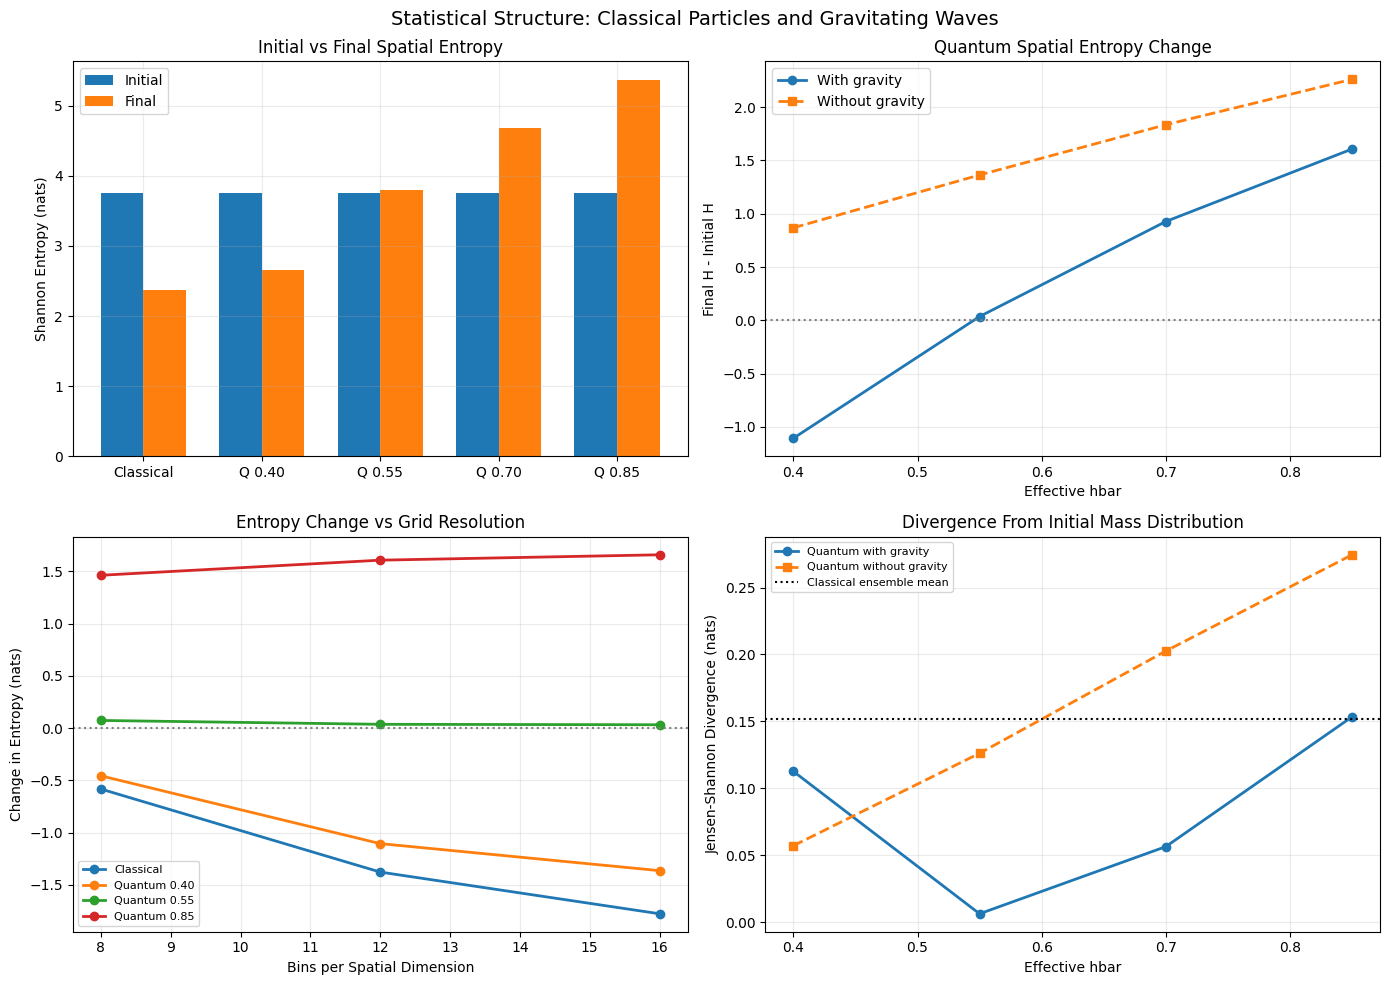

In [29]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 28: SPATIAL ENTROPY AND STATISTICAL STRUCTURE
# Classical particles vs quantum wave density
# Fixed spatial grids and resolution sensitivity
# No new gravitational simulations
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ---------- ANALYSIS SETTINGS ----------

BINS28 = [8, 12, 16]
MAIN_BINS28 = 12

assert all(NQ % b == 0 for b in BINS28)

# ---------- SHANNON ENTROPY ----------

def shannon28(probabilities):

    p = np.asarray(probabilities).ravel()
    p = p[p > 0]

    return -np.sum(p * np.log(p))


# ---------- JENSEN-SHANNON DIVERGENCE ----------

def js_divergence28(p, q):

    p = np.asarray(p).ravel()
    q = np.asarray(q).ravel()

    m = 0.5 * (p + q)

    mask_p = p > 0
    mask_q = q > 0

    kl_p = np.sum(
        p[mask_p] * np.log(p[mask_p] / m[mask_p])
    )

    kl_q = np.sum(
        q[mask_q] * np.log(q[mask_q] / m[mask_q])
    )

    return 0.5 * (kl_p + kl_q)


# ---------- QUANTUM DENSITY -> COARSE MASS GRID ----------

def quantum_probabilities28(density, bins):

    block = NQ // bins

    cell_mass = (
        density.reshape(
            bins, block,
            bins, block,
            bins, block
        ).sum(axis=(1, 3, 5))
        * DXQ**3
    )

    p = cell_mass.ravel()

    return p / np.sum(p)


# ---------- CLASSICAL POSITIONS -> MASS GRID ----------

def classical_probabilities28(pos, bins):

    edges = np.linspace(
        -BOX27/2,
        BOX27/2,
        bins + 1
    )

    counts = np.histogramdd(
        pos,
        bins=(edges, edges, edges)
    )[0].ravel()

    return counts / np.sum(counts)


# ---------- RECONSTRUCT EXACT INITIAL PARTICLE CLOUDS ----------

# Cell 27 generated each initial cloud from its seed.
# This reproduces those initial positions without rerunning
# the gravitational evolution.

initial_positions28 = {}

for seed in SEEDS27:

    rng = np.random.default_rng(seed)

    p = rng.normal(
        0.0,
        SIGMA27,
        size=(NCLASS27, 3)
    )

    p -= np.mean(p, axis=0)

    initial_positions28[seed] = p


# ---------- ANALYZE ALL GRID RESOLUTIONS ----------

entropy_results28 = {}

initial_quantum_density28 = np.abs(psiQ)**2

for bins in BINS28:

    print(f"Analyzing entropy on {bins}^3 grid...")

    quantum_initial_p = quantum_probabilities28(
        initial_quantum_density28, bins
    )

    H_quantum_initial = shannon28(
        quantum_initial_p
    )

    # Classical particle realizations
    classical = []

    for seed in SEEDS27:

        p_initial = classical_probabilities28(
            initial_positions28[seed], bins
        )

        p_final = classical_probabilities28(
            classical_results27[seed]["final_positions"],
            bins
        )

        H_initial = shannon28(p_initial)
        H_final = shannon28(p_final)

        classical.append({
            "seed": seed,
            "H_initial": H_initial,
            "H_final": H_final,
            "delta_H": H_final - H_initial,
            "JS": js_divergence28(
                p_initial, p_final
            )
        })

    # Quantum initial vs final density
    quantum = {}

    for hbar in HBAR_VALUES24:

        for gravity_on in [True, False]:

            density = results24[
                (hbar, gravity_on)
            ]["final_density"]

            p_final = quantum_probabilities28(
                density, bins
            )

            H_final = shannon28(p_final)

            quantum[(hbar, gravity_on)] = {
                "H_final": H_final,
                "delta_H": H_final - H_quantum_initial,
                "JS": js_divergence28(
                    quantum_initial_p, p_final
                )
            }

    entropy_results28[bins] = {
        "classical": classical,
        "quantum": quantum,
        "quantum_H_initial": H_quantum_initial
    }


# ---------- MAIN RESULTS ----------

main28 = entropy_results28[MAIN_BINS28]

classical_H0_28 = np.array([
    r["H_initial"]
    for r in main28["classical"]
])

classical_Hf_28 = np.array([
    r["H_final"]
    for r in main28["classical"]
])

classical_delta28 = np.array([
    r["delta_H"]
    for r in main28["classical"]
])

classical_JS28 = np.array([
    r["JS"]
    for r in main28["classical"]
])

print("\nCLASSICAL AND QUANTUM SPATIAL SHANNON ENTROPY")
print("=" * 75)

print(f"Analysis grid: {MAIN_BINS28}^3")
print("Entropy units: nats")
print("Natural logarithm used")

print("\nCLASSICAL PARTICLE-MESH ENSEMBLE")
print("-" * 65)

print(
    "Mean initial H:",
    f"{np.mean(classical_H0_28):.6f}"
)

print(
    "Mean final H:",
    f"{np.mean(classical_Hf_28):.6f}"
)

print(
    "Mean entropy change:",
    f"{np.mean(classical_delta28):+.6f}"
)

print(
    "Between-seed SD of change:",
    f"{np.std(classical_delta28, ddof=1):.6f}"
)

print("\nQUANTUM WAVE SPATIAL ENTROPY")
print("-" * 75)

print(
    "Initial quantum H:",
    f"{main28['quantum_H_initial']:.6f}"
)

print(
    f"{'hbar':<9}"
    f"{'Gravity':<12}"
    f"{'Final H':<15}"
    f"{'Delta H':<15}"
    f"{'JS divergence'}"
)

for hbar in HBAR_VALUES24:

    for gravity_on in [True, False]:

        r = main28["quantum"][(hbar, gravity_on)]

        print(
            f"{hbar:<9.2f}"
            f"{str(gravity_on):<12}"
            f"{r['H_final']:<15.6f}"
            f"{r['delta_H']:<+15.6f}"
            f"{r['JS']:.6f}"
        )


# ---------- ENTROPY RESOLUTION CHECK ----------

print("\nENTROPY RESOLUTION SENSITIVITY")
print("=" * 75)

print(
    f"{'Bins':<10}"
    f"{'Classical Delta H':<23}"
    f"{'Quantum 0.40 Delta H':<24}"
    f"{'Quantum 0.85 Delta H'}"
)

for bins in BINS28:

    result = entropy_results28[bins]

    classical_change = np.mean([
        r["delta_H"]
        for r in result["classical"]
    ])

    q40 = result["quantum"][(0.40, True)]["delta_H"]
    q85 = result["quantum"][(0.85, True)]["delta_H"]

    print(
        f"{bins:<10}"
        f"{classical_change:<+23.6f}"
        f"{q40:<+24.6f}"
        f"{q85:+.6f}"
    )


# ---------- PLOTS ----------

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# GRAPH 1: INITIAL VS FINAL ENTROPY

labels28 = ["Classical"] + [
    f"Q {h:.2f}" for h in HBAR_VALUES24
]

initial_H28 = [np.mean(classical_H0_28)]
final_H28 = [np.mean(classical_Hf_28)]

for hbar in HBAR_VALUES24:

    initial_H28.append(
        main28["quantum_H_initial"]
    )

    final_H28.append(
        main28["quantum"][
            (hbar, True)
        ]["H_final"]
    )

x28 = np.arange(len(labels28))
width28 = 0.36

axes[0, 0].bar(
    x28 - width28/2,
    initial_H28,
    width28,
    label="Initial"
)

axes[0, 0].bar(
    x28 + width28/2,
    final_H28,
    width28,
    label="Final"
)

axes[0, 0].set_xticks(x28)
axes[0, 0].set_xticklabels(labels28)

axes[0, 0].set_title("Initial vs Final Spatial Entropy")
axes[0, 0].set_ylabel("Shannon Entropy (nats)")
axes[0, 0].legend()


# GRAPH 2: QUANTUM ENTROPY CHANGE

delta_gravity28 = [
    main28["quantum"][(h, True)]["delta_H"]
    for h in HBAR_VALUES24
]

delta_free28 = [
    main28["quantum"][(h, False)]["delta_H"]
    for h in HBAR_VALUES24
]

axes[0, 1].plot(
    HBAR_VALUES24,
    delta_gravity28,
    "o-",
    linewidth=2,
    label="With gravity"
)

axes[0, 1].plot(
    HBAR_VALUES24,
    delta_free28,
    "s--",
    linewidth=2,
    label="Without gravity"
)

axes[0, 1].axhline(
    0, color="gray", linestyle=":"
)

axes[0, 1].set_title(
    "Quantum Spatial Entropy Change"
)

axes[0, 1].set_xlabel("Effective hbar")
axes[0, 1].set_ylabel("Final H - Initial H")
axes[0, 1].legend()


# GRAPH 3: ESTIMATOR RESOLUTION SENSITIVITY

classical_changes28 = []

for bins in BINS28:

    classical_changes28.append(
        np.mean([
            r["delta_H"]
            for r in entropy_results28[bins]["classical"]
        ])
    )

axes[1, 0].plot(
    BINS28,
    classical_changes28,
    "o-",
    linewidth=2,
    label="Classical"
)

for hbar in [0.40, 0.55, 0.85]:

    values = [
        entropy_results28[b]["quantum"][
            (hbar, True)
        ]["delta_H"]
        for b in BINS28
    ]

    axes[1, 0].plot(
        BINS28,
        values,
        "o-",
        linewidth=2,
        label=f"Quantum {hbar:.2f}"
    )

axes[1, 0].axhline(
    0, color="gray", linestyle=":"
)

axes[1, 0].set_title("Entropy Change vs Grid Resolution")
axes[1, 0].set_xlabel("Bins per Spatial Dimension")
axes[1, 0].set_ylabel("Change in Entropy (nats)")
axes[1, 0].legend(fontsize=8)


# GRAPH 4: JENSEN-SHANNON DIVERGENCE

JS_gravity28 = [
    main28["quantum"][(h, True)]["JS"]
    for h in HBAR_VALUES24
]

JS_free28 = [
    main28["quantum"][(h, False)]["JS"]
    for h in HBAR_VALUES24
]

axes[1, 1].plot(
    HBAR_VALUES24,
    JS_gravity28,
    "o-",
    linewidth=2,
    label="Quantum with gravity"
)

axes[1, 1].plot(
    HBAR_VALUES24,
    JS_free28,
    "s--",
    linewidth=2,
    label="Quantum without gravity"
)

axes[1, 1].axhline(
    np.mean(classical_JS28),
    color="black",
    linestyle=":",
    label="Classical ensemble mean"
)

axes[1, 1].set_title(
    "Divergence From Initial Mass Distribution"
)

axes[1, 1].set_xlabel("Effective hbar")
axes[1, 1].set_ylabel("Jensen-Shannon Divergence (nats)")
axes[1, 1].legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.suptitle(
    "Statistical Structure: Classical Particles and Gravitating Waves",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ---------- FINAL CHECK ----------

for bins, result in entropy_results28.items():

    for r in result["classical"]:
        assert np.isfinite(r["delta_H"])
        assert 0 <= r["JS"] <= np.log(2) + 1e-10

    for r in result["quantum"].values():
        assert np.isfinite(r["delta_H"])
        assert 0 <= r["JS"] <= np.log(2) + 1e-10



In [30]:

# ============================================================
# CLASSICAL AND QUANTUM-WAVE GRAVITATIONAL DYNAMICS
# CELL 29: FINAL SCIENTIFIC AND STATISTICAL AUDIT
# Uses completed Cells 19-28
# No new gravitational simulations
# ============================================================

import numpy as np

print("=" * 72)
print("FINAL SCIENTIFIC AUDIT")
print("Classical and Quantum-Wave Self-Gravitating Systems")
print("=" * 72)

checks29 = []

def check29(name, passed, explanation):
    checks29.append((name, bool(passed), explanation))
    print(f"{'PASS' if passed else 'REVIEW'} | {name}")
    print(f"       {explanation}")

# ============================================================
# 1. QUANTUM NUMERICAL ACCURACY
# ============================================================

print("\n1. QUANTUM NUMERICAL ACCURACY")
print("-" * 72)

check29(
    "Mass conservation",
    max_mass_error24 < 1e-6,
    f"Maximum mass error = {max_mass_error24:.4e}%"
)

check29(
    "Energy conservation",
    max_energy_error24 < 0.1,
    f"Maximum energy error = {max_energy_error24:.6f}%"
)

# Grid convergence: compare 48^3 with 64^3
grid_differences29 = []

for h in [0.40, 0.55]:
    for quantity in ["R_ratio", "P_ratio"]:
        a = grid_results25[(h, 48)][quantity]
        b = grid_results25[(h, 64)][quantity]

        difference = 100 * abs(a - b) / abs(b)
        grid_differences29.append(difference)

max_grid_difference29 = max(grid_differences29)

check29(
    "Spatial-grid convergence",
    max_grid_difference29 < 1.0,
    f"Maximum 48^3 vs 64^3 difference = "
    f"{max_grid_difference29:.6f}%"
)

# Richardson comparison of the SAME final RMS-radius observable.
# Energy drift by itself is not a direct solution-convergence test.
r_coarse29 = dt_results25[0.020]["R_ratio"]
r_medium29 = dt_results25[0.010]["R_ratio"]
r_fine29 = dt_results25[0.005]["R_ratio"]

coarse_difference29 = abs(r_coarse29 - r_medium29)
fine_difference29 = abs(r_medium29 - r_fine29)
order_a29 = (float(np.log2(coarse_difference29 / fine_difference29))
             if fine_difference29 > 1e-14 else float("nan"))
# Preserve this historical variable for JSON/report consumers; both
# plotted/checked orders now refer to solution-observable convergence.
order_b29 = order_a29

check29(
    "Time-step convergence of final RMS radius",
    bool(np.isfinite(order_a29) and 1.7 < order_a29 < 2.3),
    f"Richardson order from R/R0 = {order_a29:.3f}; "
    f"coarse/fine differences = {coarse_difference29:.3e}, "
    f"{fine_difference29:.3e}"
)

# ============================================================
# 2. FREE QUANTUM-WAVE ANALYTICAL CONTROL
# ============================================================

print("\n2. ANALYTICAL FREE-WAVE CONTROL")
print("-" * 72)

free_errors29 = []

for h in HBAR_VALUES24:

    numeric = results24[(h, False)]["radius"][-1]

    sigma_final = np.sqrt(
        SIGMA_Q**2 +
        (h * TIME24[-1] / (2 * SIGMA_Q))**2
    )

    analytic = np.sqrt(3.0) * sigma_final

    error = 100 * abs(numeric - analytic) / analytic
    free_errors29.append(error)

    print(f"hbar={h:.2f}: RMS error = {error:.5f}%")

check29(
    "Free Gaussian analytical agreement",
    max(free_errors29) < 1.0,
    f"Maximum relative error = "
    f"{max(free_errors29):.6f}%"
)

# ============================================================
# 3. CLASSICAL PARTICLE-MESH CHECKS
# ============================================================

print("\n3. CLASSICAL MODEL VALIDATION")
print("-" * 72)

classical_max_E29 = max(
    np.max(classical_results27[s]["energy_error"])
    for s in SEEDS27
)

classical_max_M29 = max(
    np.max(classical_results27[s]["mass_error"])
    for s in SEEDS27
)

classical_final_R29 = np.array([
    classical_results27[s]["radius"][-1]
    for s in SEEDS27
])

check29(
    "Classical mass conservation",
    classical_max_M29 < 1e-6,
    f"Maximum mass error = {classical_max_M29:.4e}%"
)

check29(
    "Preliminary classical energy accuracy",
    classical_max_E29 < 1.0,
    f"Maximum energy error = {classical_max_E29:.6f}%"
)

print(
    "Classical final R/R0:",
    f"{np.mean(classical_final_R29):.6f}"
    f" +/- {np.std(classical_final_R29, ddof=1):.6f}"
)

print(
    "Note: Only three random realizations and one "
    "particle-mesh resolution were tested."
)

# ============================================================
# 4. QUANTUM COLLAPSE / DISPERSION FINDING
# ============================================================

print("\n4. QUANTUM CONTRACTION AND EXPANSION")
print("-" * 72)

for h in HBAR_VALUES24:

    grav = results24[(h, True)]
    free = results24[(h, False)]

    Rg = grav["radius"][-1] / grav["radius"][0]
    Rf = free["radius"][-1] / free["radius"][0]

    label = "CONTRACTION" if Rg < 1 else "EXPANSION"

    print(
        f"hbar={h:.2f}: "
        f"gravity R/R0={Rg:.6f}, "
        f"free R/R0={Rf:.6f}, "
        f"{label}"
    )

crossover_supported29 = (
    results24[(0.40, True)]["radius"][-1]
    < results24[(0.40, True)]["radius"][0]
    and
    results24[(0.55, True)]["radius"][-1]
    > results24[(0.55, True)]["radius"][0]
)

check29(
    "Finite-time contraction/expansion crossover",
    crossover_supported29,
    "Crossover bracketed between hbar=0.40 "
    "and hbar=0.55 at simulated time t=3."
)

# ============================================================
# 5. ENTROPY SIGN ROBUSTNESS
# ============================================================

print("\n5. SPATIAL ENTROPY ROBUSTNESS")
print("-" * 72)

def classical_delta29(bins):
    return np.mean([
        r["delta_H"]
        for r in entropy_results28[bins]["classical"]
    ])

def quantum_delta29(bins, hbar):
    return entropy_results28[bins]["quantum"][
        (hbar, True)
    ]["delta_H"]

classical_sign29 = all(
    classical_delta29(b) < 0
    for b in BINS28
)

q040_sign29 = all(
    quantum_delta29(b, 0.40) < 0
    for b in BINS28
)

q085_sign29 = all(
    quantum_delta29(b, 0.85) > 0
    for b in BINS28
)

check29(
    "Classical spatial-entropy decrease",
    classical_sign29,
    "Negative change across tested coarse-graining grids."
)

check29(
    "Quantum 0.40 spatial-entropy decrease",
    q040_sign29,
    "Negative change across tested grids."
)

check29(
    "Quantum 0.85 spatial-entropy increase",
    q085_sign29,
    "Positive change across tested grids."
)

print(
    "Quantum hbar=0.55 change on 12^3 grid:",
    f"{quantum_delta29(12, 0.55):+.6f} nats"
)
print("Note: This small change is near zero; avoid overinterpreting it.")

# ============================================================
# 6. FINITE-N ENTROPY SAMPLING BIAS TEST
# ============================================================

print("\n6. FINITE-PARTICLE ENTROPY SAMPLING TEST")
print("-" * 72)

rng29 = np.random.default_rng(2901)

def sampled_entropy29(probabilities, n_samples=4000, reps=100):

    p = np.asarray(probabilities, dtype=float)
    p = p / p.sum()

    counts = rng29.multinomial(
        n_samples, p, size=reps
    )

    freq = counts / n_samples

    entropies = -np.sum(
        freq * np.log(np.maximum(freq, 1.0/n_samples)),
        axis=1
    )

    return float(np.mean(entropies))

p_initial29 = quantum_probabilities28(
    np.abs(psiQ)**2, MAIN_BINS28
)

H_initial_exact29 = shannon28(p_initial29)
H_initial_sample29 = sampled_entropy29(p_initial29)

sampling_results29 = {}

print(
    f"{'State':<14}"
    f"{'Grid Delta H':<19}"
    f"{'Sampled Delta H':<20}"
    f"{'Difference'}"
)

for h in HBAR_VALUES24:

    p_final = quantum_probabilities28(
        results24[(h, True)]["final_density"],
        MAIN_BINS28
    )

    exact_delta = (
        shannon28(p_final) - H_initial_exact29
    )

    sampled_delta = (
        sampled_entropy29(p_final)
        - H_initial_sample29
    )

    sampling_results29[h] = {
        "grid_delta": float(exact_delta),
        "sampled_delta": float(sampled_delta)
    }

    print(
        f"{'hbar '+str(h):<14}"
        f"{exact_delta:<+19.6f}"
        f"{sampled_delta:<+20.6f}"
        f"{sampled_delta-exact_delta:+.6f}"
    )

print(
    "\nSampling test: 100 multinomial draws per state,"
    " each with 4000 particles."
)

print(
    "This tests finite-N histogram bias, not uncertainty"
    " in the gravitational evolution."
)

# ============================================================
# 7. NON-EQUILIBRIUM HEAT-CAPACITY LIMITATION
# ============================================================

print("\n7. ANOMALOUS GRAVITATIONAL THERMODYNAMICS")
print("-" * 72)

maximum_T_drift29 = np.max(
    np.abs(temperature_drift20)
)

print(
    "Energy-temperature slopes:",
    f"{np.min(window_slopes20):.3f}"
    f" to {np.max(window_slopes20):.3f}"
)

print(
    "Maximum late-time temperature drift:",
    f"{maximum_T_drift29:.3f}%"
)

print(
    "Theoretical scaling-test slope:",
    f"{C_family21:.4f}"
)

print(
    "Idealized virial slope:",
    f"{C_ideal21:.4f}"
)

preliminary_virial_drift_criteria29 = (
    maximum_T_drift29 < 5.0
    and np.all(np.abs(mean_Q20 - 1.0) < 0.05)
)
# A finite-time virial ratio near 1 plus low temperature drift is NOT
# sufficient to prove thermal equilibrium or measure dE/dT at equilibrium.
equilibrium_confirmed29 = False
print("Virial/drift screening criteria met:", preliminary_virial_drift_criteria29)
print("Equilibrium heat capacity: NOT ESTABLISHED.")
print("These are transient ensemble/proxy diagnostics, not equilibrium samples.")

# ============================================================
# 8. FINAL AUDIT SUMMARY
# ============================================================

audit29 = {
    "quantum_max_mass_error_pct": float(max_mass_error24),
    "quantum_max_energy_error_pct": float(max_energy_error24),
    "quantum_grid_difference_pct": float(max_grid_difference29),
    "quantum_timestep_orders": [
        float(order_a29), float(order_b29)
    ],
    "max_free_gaussian_error_pct": float(max(free_errors29)),
    "classical_max_energy_error_pct": float(classical_max_E29),
    "classical_max_mass_error_pct": float(classical_max_M29),
    "classical_final_radius_mean": float(
        np.mean(classical_final_R29)
    ),
    "classical_final_radius_sd": float(
        np.std(classical_final_R29, ddof=1)
    ),
    "crossover_supported": bool(crossover_supported29),
    "entropy_signs_stable": bool(
        classical_sign29 and q040_sign29 and q085_sign29
    ),
    "max_temperature_drift_pct": float(maximum_T_drift29),
    "heat_capacity_equilibrium_confirmed": bool(
        equilibrium_confirmed29
    ),
    "sampling_results": sampling_results29,
    "checks": checks29
}

passed29 = sum(item[1] for item in checks29)

print("\n" + "=" * 72)
print("FINAL AUDIT SUMMARY")
print("=" * 72)

print(
    f"Numerical and qualitative checks: "
    f"{passed29}/{len(checks29)} passed"
)

print(
    "Independent equilibrium heat-capacity validation:",
    "YES" if equilibrium_confirmed29 else "NOT YET"
)

print("\nSCIENTIFIC INTERPRETATION RULES")
print("-" * 72)

print("1. Spatial Shannon entropy is not total thermodynamic entropy.")
print("2. Pure-state wavefunction evolution is not quantum thermalization.")
print("3. Quantum parameter values are dimensionless.")
print("4. The crossover applies to the tested setup and final time.")
print("5. Classical particle-mesh resolution remains a limitation.")
print("6. Constructed virial scaling is a theoretical consistency check.")
print("7. Negative caloric slopes do not alone establish equilibrium C.")



FINAL SCIENTIFIC AUDIT
Classical and Quantum-Wave Self-Gravitating Systems

1. QUANTUM NUMERICAL ACCURACY
------------------------------------------------------------------------
PASS | Mass conservation
       Maximum mass error = 2.8599e-11%
PASS | Energy conservation
       Maximum energy error = 0.003327%
PASS | Spatial-grid convergence
       Maximum 48^3 vs 64^3 difference = 0.003091%
PASS | Time-step convergence of final RMS radius
       Richardson order from R/R0 = 2.000; coarse/fine differences = 2.097e-05, 5.244e-06

2. ANALYTICAL FREE-WAVE CONTROL
------------------------------------------------------------------------
hbar=0.40: RMS error = 0.00001%
hbar=0.55: RMS error = 0.00008%
hbar=0.70: RMS error = 0.00758%
hbar=0.85: RMS error = 0.08280%
PASS | Free Gaussian analytical agreement
       Maximum relative error = 0.082805%

3. CLASSICAL MODEL VALIDATION
------------------------------------------------------------------------
PASS | Classical mass conservation
       Max

Running grid=32^3, N=4000, seed=2026
Running grid=32^3, N=4000, seed=40
Running grid=48^3, N=4000, seed=2026
Running grid=48^3, N=4000, seed=40
Running grid=64^3, N=4000, seed=2026
Running grid=64^3, N=4000, seed=40
Running grid=48^3, N=2000, seed=2026
Running grid=48^3, N=2000, seed=40
Running grid=48^3, N=8000, seed=2026
Running grid=48^3, N=8000, seed=40
Baseline verification seed 2026: difference = 6.106e-16
Baseline verification seed 40: difference = 4.996e-16

CLASSICAL CONVERGENCE RESULTS
Grid     Particles    Mean R/R0      Central mass %    Max energy error %
32       4000         0.478583       89.7000           0.121847
48       4000         0.496394       74.1000           0.341944
64       4000         0.504217       72.1250           0.310264
48       2000         0.489462       74.9750           0.337740
48       8000         0.493356       73.7562           0.172336

CONVERGENCE SUMMARY
48^3 to 64^3 radius change: 1.5749%
4000 to 8000 particle radius change: 0.6128%
Not

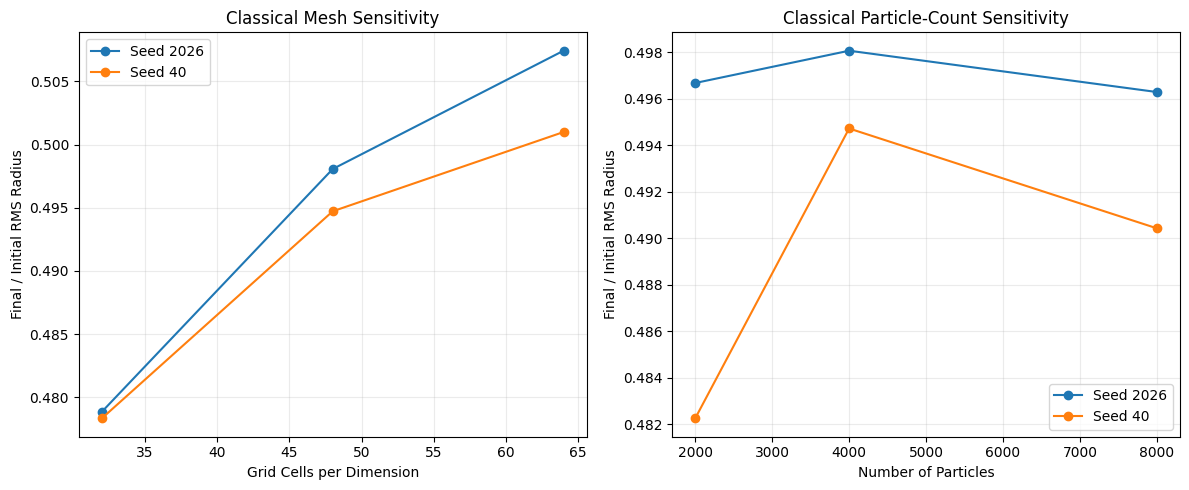

In [31]:

# ============================================================
# CELL 31: CLASSICAL PARTICLE-MESH CONVERGENCE AUDIT
# Tests grid size and particle count
# Uses existing parameters from Cells 22 and 27
# Does not modify previous results
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy import fft as sfft

assert "classical_results27" in globals(), "Run Cell 27 first"

CONFIGS31 = [
    (32, 4000),
    (48, 4000),
    (64, 4000),
    (48, 2000),
    (48, 8000)
]

SEEDS31 = [2026, 40]
DT31 = 0.005
STEPS31 = 600

kernels31 = {}

def gravity31(pos, n):

    dx = LQ / n

    if n not in kernels31:

        k = 2*np.pi*np.fft.fftfreq(n, d=dx)
        kz = 2*np.pi*np.fft.rfftfreq(n, d=dx)

        kx, ky, kz = np.meshgrid(
            k, k, kz, indexing="ij"
        )

        k2 = kx*kx + ky*ky + kz*kz

        kernel = np.zeros_like(k2)
        mask = k2 > 0

        kernel[mask] = -4*np.pi*GQ/k2[mask]

        kernels31[n] = kernel

    xyz = ((pos + LQ/2)/dx) % n
    base = np.floor(xyz).astype(int)
    frac = xyz - base

    ix0, iy0, iz0 = base.T
    mp = MASS_Q / len(pos)

    rho_flat = np.zeros(n**3)

    # Cloud-in-cell mass assignment
    for a in (0, 1):
        wx = (1-frac[:,0]) if a == 0 else frac[:,0]
        ix = (ix0+a) % n

        for b in (0, 1):
            wy = (1-frac[:,1]) if b == 0 else frac[:,1]
            iy = (iy0+b) % n

            for c in (0, 1):
                wz = (1-frac[:,2]) if c == 0 else frac[:,2]
                iz = (iz0+c) % n

                indices = (ix*n + iy)*n + iz

                rho_flat += np.bincount(
                    indices,
                    weights=(mp/dx**3)*wx*wy*wz,
                    minlength=n**3
                )

    rho = rho_flat.reshape(n, n, n)

    phi = sfft.irfftn(
        sfft.rfftn(rho, workers=2)*kernels31[n],
        s=(n,n,n),
        workers=2
    )

    acceleration = np.zeros_like(pos)

    # Force from CIC-interpolated potential
    for a in (0, 1):
        wx = (1-frac[:,0]) if a == 0 else frac[:,0]
        sx = -1 if a == 0 else 1
        ix = (ix0+a) % n

        for b in (0, 1):
            wy = (1-frac[:,1]) if b == 0 else frac[:,1]
            sy = -1 if b == 0 else 1
            iy = (iy0+b) % n

            for c in (0, 1):
                wz = (1-frac[:,2]) if c == 0 else frac[:,2]
                sz = -1 if c == 0 else 1
                iz = (iz0+c) % n

                val = phi[ix,iy,iz] / dx

                acceleration[:,0] -= val*sx*wy*wz
                acceleration[:,1] -= val*wx*sy*wz
                acceleration[:,2] -= val*wx*wy*sz

    return acceleration, rho, phi


def simulate31(n, nparticles, seed):

    rng = np.random.default_rng(seed)

    pos = rng.normal(
        0, SIGMA_Q, (nparticles, 3)
    )

    pos -= pos.mean(axis=0)

    vel = np.zeros_like(pos)
    mp = MASS_Q / nparticles
    dx = LQ / n

    acc, rho, phi = gravity31(pos, n)

    def diagnostics():

        r2 = np.sum(pos**2, axis=1)

        rms = np.sqrt(np.mean(r2))

        central = 100*np.mean(
            r2 <= SIGMA_Q**2
        )

        kinetic = 0.5*mp*np.sum(vel**2)

        potential = (
            0.5*np.sum(rho*phi)*dx**3
        )

        energy = kinetic + potential

        return rms, central, energy

    R0, _, E0 = diagnostics()
    max_error = 0.0

    # Kick-drift-kick integration
    for step in range(STEPS31):

        vel += 0.5*DT31*acc

        pos += DT31*vel

        pos[:] = (pos + LQ/2) % LQ - LQ/2

        acc, rho, phi = gravity31(pos, n)

        vel += 0.5*DT31*acc

        if (step+1) % 20 == 0:

            _, _, E = diagnostics()

            error = (
                100*abs(E-E0)/abs(E0)
            )

            max_error = max(max_error, error)

    R, central, E = diagnostics()

    return {
        "grid": n,
        "particles": nparticles,
        "seed": seed,
        "radius": R/R0,
        "central": central,
        "energy_error": max_error
    }


# ---------- RUN CONVERGENCE TEST ----------

results31 = []

for grid, count in CONFIGS31:

    for seed in SEEDS31:

        print(
            f"Running grid={grid}^3, "
            f"N={count}, seed={seed}"
        )

        result = simulate31(grid, count, seed)
        results31.append(result)


# ---------- VERIFY ORIGINAL BASELINE ----------

for seed in SEEDS31:

    original = classical_results27[seed]["radius"][-1]

    repeated = next(
        r["radius"] for r in results31
        if r["grid"] == 48
        and r["particles"] == 4000
        and r["seed"] == seed
    )

    difference = abs(repeated-original)

    print(
        f"Baseline verification seed {seed}: "
        f"difference = {difference:.3e}"
    )

    assert difference < 1e-5, (
        "Baseline mismatch: investigate solver"
    )


# ---------- RESULTS TABLE ----------

print("\nCLASSICAL CONVERGENCE RESULTS")
print("="*75)

print(
    f"{'Grid':<9}"
    f"{'Particles':<13}"
    f"{'Mean R/R0':<15}"
    f"{'Central mass %':<18}"
    f"{'Max energy error %'}"
)

for grid, count in CONFIGS31:

    subset = [
        r for r in results31
        if r["grid"] == grid
        and r["particles"] == count
    ]

    radius = np.mean([
        r["radius"] for r in subset
    ])

    central = np.mean([
        r["central"] for r in subset
    ])

    energy = max(
        r["energy_error"] for r in subset
    )

    print(
        f"{grid:<9}"
        f"{count:<13}"
        f"{radius:<15.6f}"
        f"{central:<18.4f}"
        f"{energy:.6f}"
    )


# ---------- PAIRED SENSITIVITY ----------

def paired31(config_a, config_b, key):

    changes = []

    for seed in SEEDS31:

        a = next(
            r[key] for r in results31
            if (r["grid"],r["particles"],r["seed"])
            == (*config_a,seed)
        )

        b = next(
            r[key] for r in results31
            if (r["grid"],r["particles"],r["seed"])
            == (*config_b,seed)
        )

        changes.append((a,b))

    return np.array(changes)


mesh_radius31 = paired31(
    (48,4000), (64,4000), "radius"
)

particle_radius31 = paired31(
    (48,4000), (48,8000), "radius"
)

mesh_change31 = np.mean(
    100*np.abs(
        mesh_radius31[:,1]-mesh_radius31[:,0]
    )/np.abs(mesh_radius31[:,0])
)

particle_change31 = np.mean(
    100*np.abs(
        particle_radius31[:,1]-particle_radius31[:,0]
    )/np.abs(particle_radius31[:,0])
)

print("\nCONVERGENCE SUMMARY")
print("="*55)

print(
    f"48^3 to 64^3 radius change: "
    f"{mesh_change31:.4f}%"
)

print(
    f"4000 to 8000 particle radius change: "
    f"{particle_change31:.4f}%"
)

print(
    "Note: This is a two-seed sensitivity check, "
    "not a proof of mathematical convergence."
)


# ---------- VISUALIZE ----------

fig, axes = plt.subplots(1,2,figsize=(12,5))

for seed in SEEDS31:

    grid_values = [32,48,64]

    grid_radii = [
        next(
            r["radius"] for r in results31
            if r["grid"] == grid
            and r["particles"] == 4000
            and r["seed"] == seed
        )
        for grid in grid_values
    ]

    axes[0].plot(
        grid_values, grid_radii,
        "o-", label=f"Seed {seed}"
    )

    counts = [2000,4000,8000]

    count_radii = [
        next(
            r["radius"] for r in results31
            if r["grid"] == 48
            and r["particles"] == count
            and r["seed"] == seed
        )
        for count in counts
    ]

    axes[1].plot(
        counts, count_radii,
        "o-", label=f"Seed {seed}"
    )

axes[0].set_title("Classical Mesh Sensitivity")
axes[0].set_xlabel("Grid Cells per Dimension")
axes[0].set_ylabel("Final / Initial RMS Radius")

axes[1].set_title("Classical Particle-Count Sensitivity")
axes[1].set_xlabel("Number of Particles")
axes[1].set_ylabel("Final / Initial RMS Radius")

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()



Running matched classical experiment: hbar=0.40, seed=2026
Running matched classical experiment: hbar=0.40, seed=40
Running matched classical experiment: hbar=0.40, seed=53
Running matched classical experiment: hbar=0.55, seed=2026
Running matched classical experiment: hbar=0.55, seed=40
Running matched classical experiment: hbar=0.55, seed=53
Running matched classical experiment: hbar=0.70, seed=2026
Running matched classical experiment: hbar=0.70, seed=40
Running matched classical experiment: hbar=0.70, seed=53
Running matched classical experiment: hbar=0.85, seed=2026
Running matched classical experiment: hbar=0.85, seed=40
Running matched classical experiment: hbar=0.85, seed=53

KINETIC-ENERGY-MATCHED CLASSICAL VS QUANTUM
hbar      Classical R/R0         Quantum R/R0      Max E error (%)
0.40      0.738089 +/- 0.006785    0.667327          0.033964
  Free-motion difference: 0.2529%
0.55      1.068847 +/- 0.003034    1.030831          0.019725
  Free-motion difference: 0.2100%
0.70

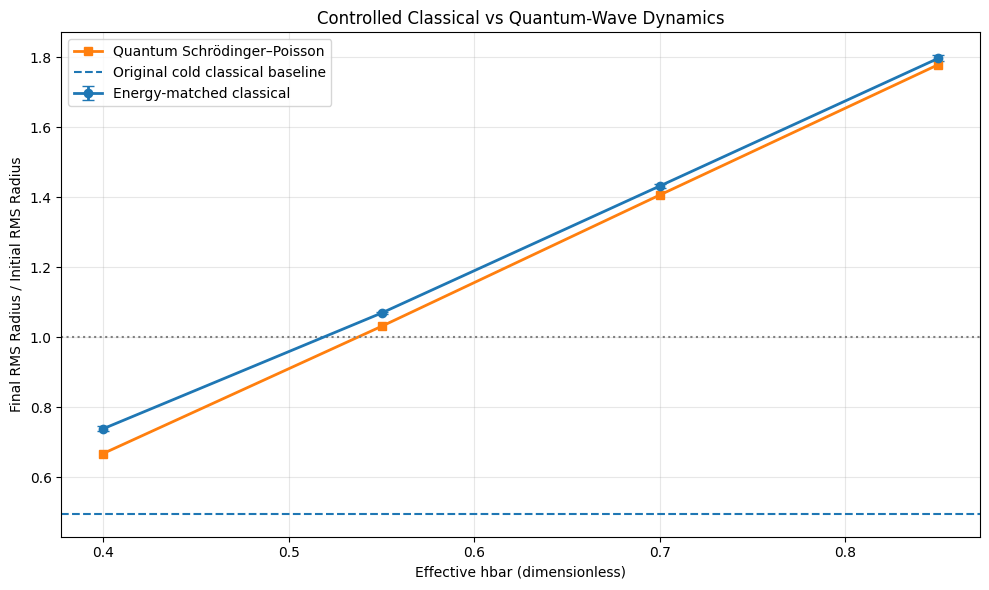


MAXIMUM BOUNDARY PARTICLE FRACTION
0.0025


In [32]:

# ============================================================
# CELL 32: KINETIC-ENERGY-MATCHED CLASSICAL CONTROL
# Same project, same gravity, same box and same simulation time
# Existing results are NOT modified
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

required32 = [
    "results24", "HBAR_VALUES24", "TIME24",
    "classical_results27", "NCLASS27", "SEEDS27",
    "DT27", "STEPS27", "LQ", "MASS_Q", "SIGMA_Q", "NQ"
]

assert all(x in globals() for x in required32), (
    "Run Cells 22-27 first."
)

# Support either version of the successful Cell 31
force32 = globals().get(
    "gravity31",
    globals().get("pm_gravity31")
)

assert callable(force32), "Run Cell 31 first."

SEEDS32 = list(SEEDS27)
HBARS32 = list(HBAR_VALUES24)

GRID32 = NQ
N32 = NCLASS27
DT32 = DT27
STEPS32 = STEPS27
TIME32 = DT32 * STEPS32

assert np.isclose(TIME32, TIME24[-1])


def run_control32(hbar, seed):

    # ------------------------------------------
    # Same initial Gaussian positions as Cell 27
    # ------------------------------------------

    rng_pos = np.random.default_rng(seed)

    pos = rng_pos.normal(
        0.0, SIGMA_Q, (N32, 3)
    )

    pos -= pos.mean(axis=0)

    # ------------------------------------------
    # Gaussian velocity distribution matching
    # initial quantum-wave kinetic energy
    # ------------------------------------------

    rng_vel = np.random.default_rng(100000 + seed)

    velocity_sigma = hbar / (2.0 * SIGMA_Q)

    vel = rng_vel.normal(
        0.0, velocity_sigma, (N32, 3)
    )

    vel -= vel.mean(axis=0)

    mp = MASS_Q / N32
    dx = LQ / GRID32

    # Gravity-OFF quantum energy is purely kinetic
    quantum_K = float(
        results24[(hbar, False)]["initial_energy"]
    )

    sampled_K = 0.5 * mp * np.sum(vel**2)

    # Match kinetic energies exactly
    vel *= np.sqrt(quantum_K / sampled_K)

    actual_K = 0.5 * mp * np.sum(vel**2)

    assert np.isclose(
        actual_K, quantum_K, rtol=1e-12
    )

    initial_radius = np.sqrt(
        np.mean(np.sum(pos**2, axis=1))
    )

    # ------------------------------------------
    # Free-motion control
    # ------------------------------------------

    free_pos = (
        pos + TIME32 * vel + LQ / 2
    ) % LQ - LQ / 2

    free_radius = np.sqrt(
        np.mean(np.sum(free_pos**2, axis=1))
    )

    free_ratio = free_radius / initial_radius

    # ------------------------------------------
    # Self-gravitating classical evolution
    # ------------------------------------------

    acc, rho, phi = force32(pos, GRID32)

    def total_energy32():

        kinetic = (
            0.5 * mp * np.sum(vel**2)
        )

        potential = (
            0.5 * np.sum(rho * phi) * dx**3
        )

        return kinetic + potential

    E0 = total_energy32()

    max_energy_error = 0.0
    max_boundary = 0.0

    for step in range(STEPS32):

        # Kick-drift-kick integration
        vel += 0.5 * DT32 * acc

        pos += DT32 * vel

        pos[:] = (
            (pos + LQ/2) % LQ
        ) - LQ/2

        acc, rho, phi = force32(pos, GRID32)

        vel += 0.5 * DT32 * acc

        if (
            (step + 1) % 20 == 0
            or step == STEPS32 - 1
        ):

            E = total_energy32()

            error = (
                100 * abs(E-E0)
                / max(abs(E0), 1e-12)
            )

            max_energy_error = max(
                max_energy_error, error
            )

            boundary = np.mean(
                np.any(
                    np.abs(pos) > LQ/2 - 2*dx,
                    axis=1
                )
            )

            max_boundary = max(
                max_boundary, boundary
            )

    final_radius = np.sqrt(
        np.mean(np.sum(pos**2, axis=1))
    )

    return {
        "hbar": hbar,
        "seed": seed,
        "radius_ratio": final_radius / initial_radius,
        "free_ratio": free_ratio,
        "quantum_K": quantum_K,
        "classical_K": actual_K,
        "max_energy_error": max_energy_error,
        "max_boundary": max_boundary
    }


# ============================================================
# RUN MATCHED EXPERIMENTS
# ============================================================

results32 = []

for hbar in HBARS32:

    for seed in SEEDS32:

        print(
            f"Running matched classical experiment: "
            f"hbar={hbar:.2f}, seed={seed}"
        )

        results32.append(
            run_control32(hbar, seed)
        )


# ============================================================
# PRINT SCIENTIFIC COMPARISON
# ============================================================

print("\nKINETIC-ENERGY-MATCHED CLASSICAL VS QUANTUM")
print("=" * 82)

print(
    f"{'hbar':<10}"
    f"{'Classical R/R0':<23}"
    f"{'Quantum R/R0':<18}"
    f"{'Max E error (%)'}"
)

classical_means32 = []
classical_stds32 = []
quantum_radii32 = []

for hbar in HBARS32:

    subset = [
        r for r in results32
        if r["hbar"] == hbar
    ]

    classical_values = np.array([
        r["radius_ratio"] for r in subset
    ])

    mean_r = np.mean(classical_values)

    std_r = np.std(
        classical_values, ddof=1
    )

    quantum_r = (
        results24[(hbar, True)]["radius"][-1]
        / results24[(hbar, True)]["radius"][0]
    )

    classical_free = np.mean([
        r["free_ratio"] for r in subset
    ])

    quantum_free = (
        results24[(hbar, False)]["radius"][-1]
        / results24[(hbar, False)]["radius"][0]
    )

    max_error = max(
        r["max_energy_error"] for r in subset
    )

    classical_means32.append(mean_r)
    classical_stds32.append(std_r)
    quantum_radii32.append(quantum_r)

    print(
        f"{hbar:<10.2f}"
        f"{mean_r:.6f} +/- {std_r:.6f}    "
        f"{quantum_r:<18.6f}"
        f"{max_error:.6f}"
    )

    free_difference = (
        100 * abs(classical_free - quantum_free)
        / quantum_free
    )

    print(
        f"  Free-motion difference: "
        f"{free_difference:.4f}%"
    )

    if free_difference > 5:
        print("  REVIEW: Free-motion agreement exceeds 5%.")

    if max_error > 1:
        print("  REVIEW: Energy drift exceeds 1%.")


# ============================================================
# FINAL COMPARISON GRAPH
# ============================================================

cold_mean32 = np.mean([
    classical_results27[s]["radius"][-1]
    for s in SEEDS27
])

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    HBARS32,
    classical_means32,
    yerr=classical_stds32,
    fmt="o-",
    capsize=4,
    linewidth=2,
    label="Energy-matched classical"
)

ax.plot(
    HBARS32,
    quantum_radii32,
    "s-",
    linewidth=2,
    label="Quantum Schrödinger–Poisson"
)

ax.axhline(
    cold_mean32,
    linestyle="--",
    label="Original cold classical baseline"
)

ax.axhline(
    1.0,
    linestyle=":",
    color="gray"
)

ax.set_title(
    "Controlled Classical vs Quantum-Wave Dynamics"
)

ax.set_xlabel(
    "Effective hbar (dimensionless)"
)

ax.set_ylabel(
    "Final RMS Radius / Initial RMS Radius"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("\nMAXIMUM BOUNDARY PARTICLE FRACTION")

print(
    max(r["max_boundary"] for r in results32)
)



Clean export directory initialized; previous generated outputs cleared.


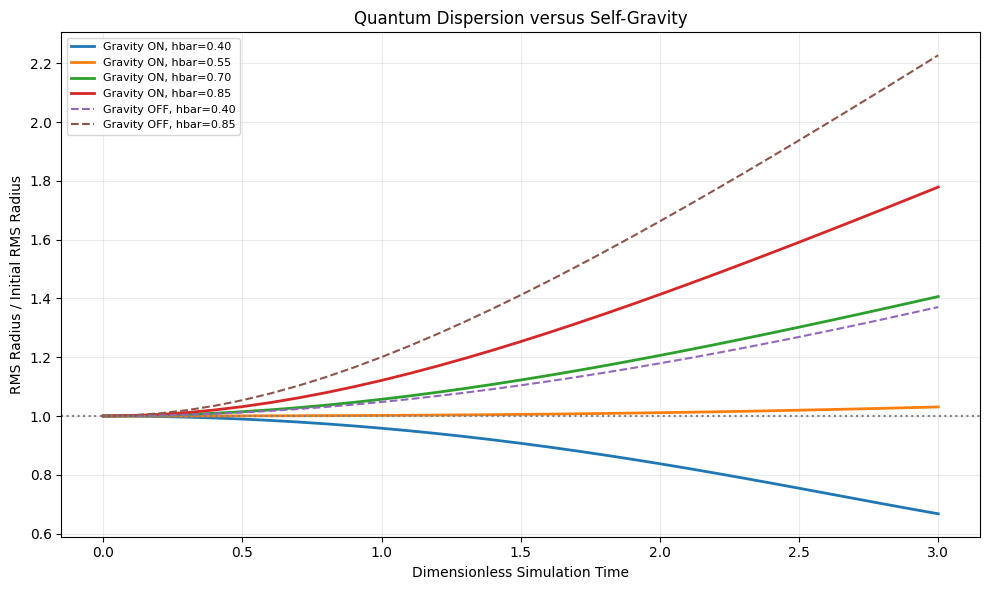

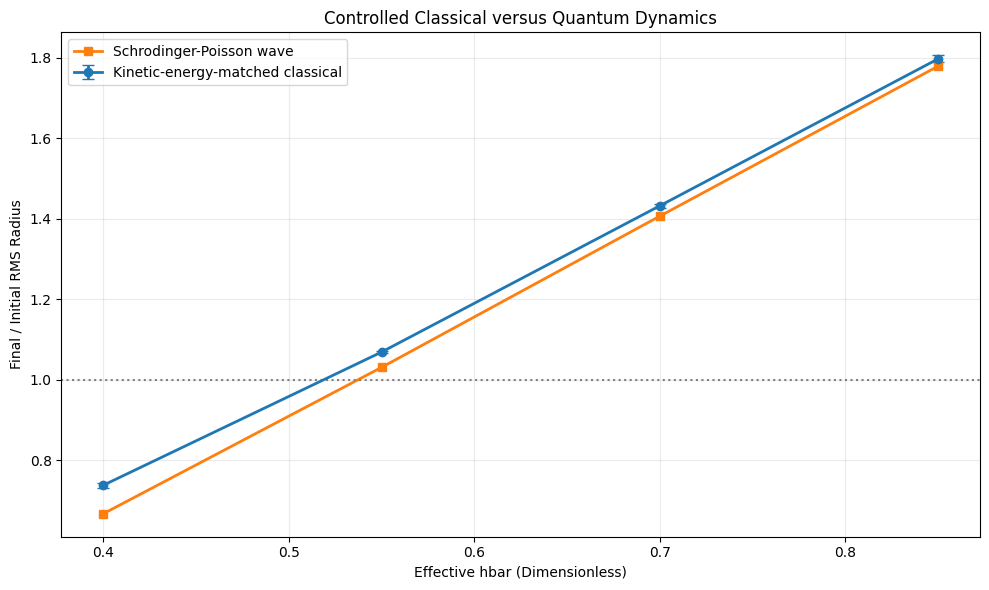

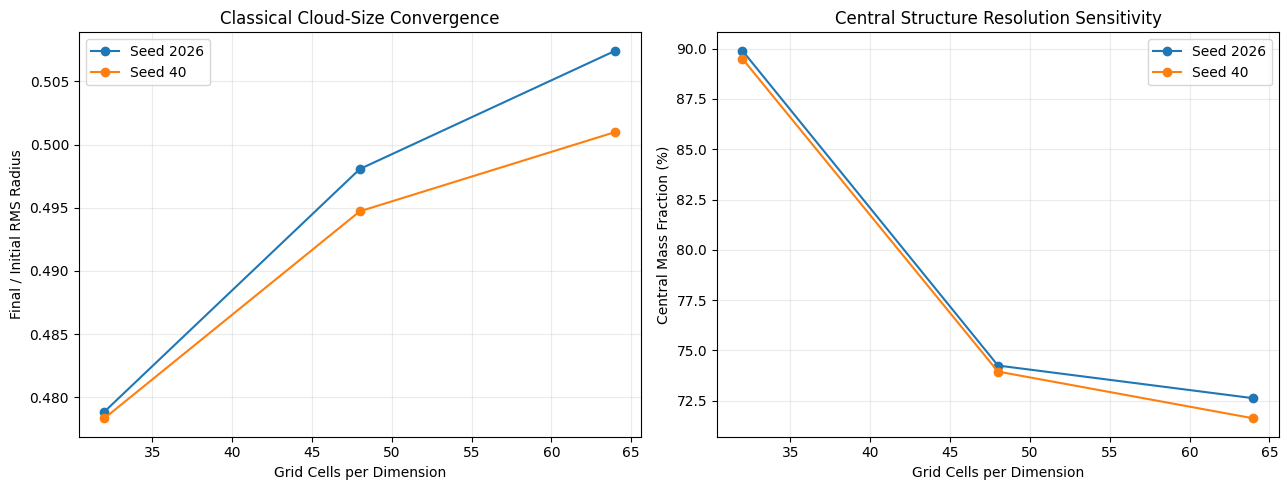

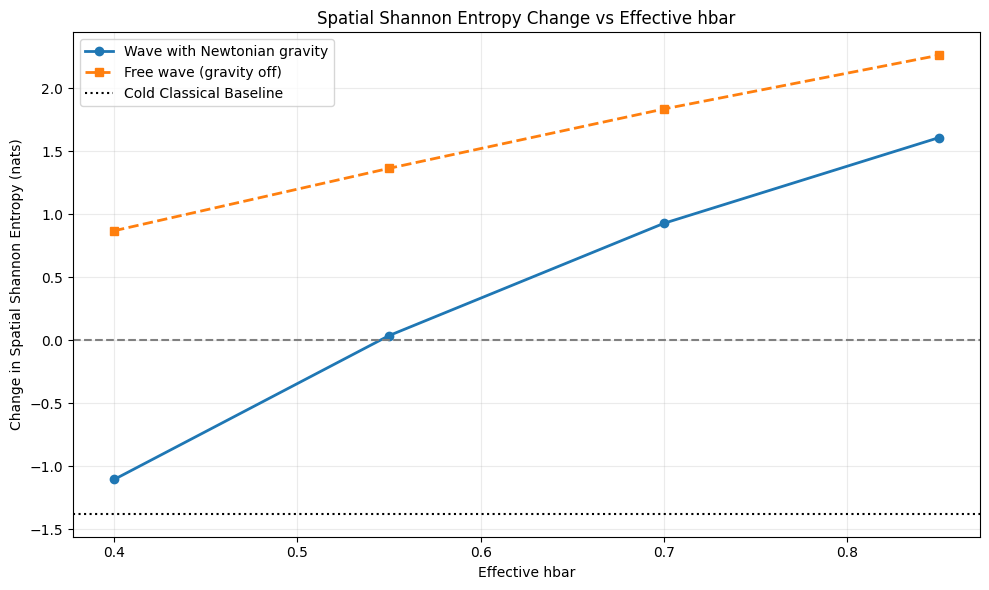

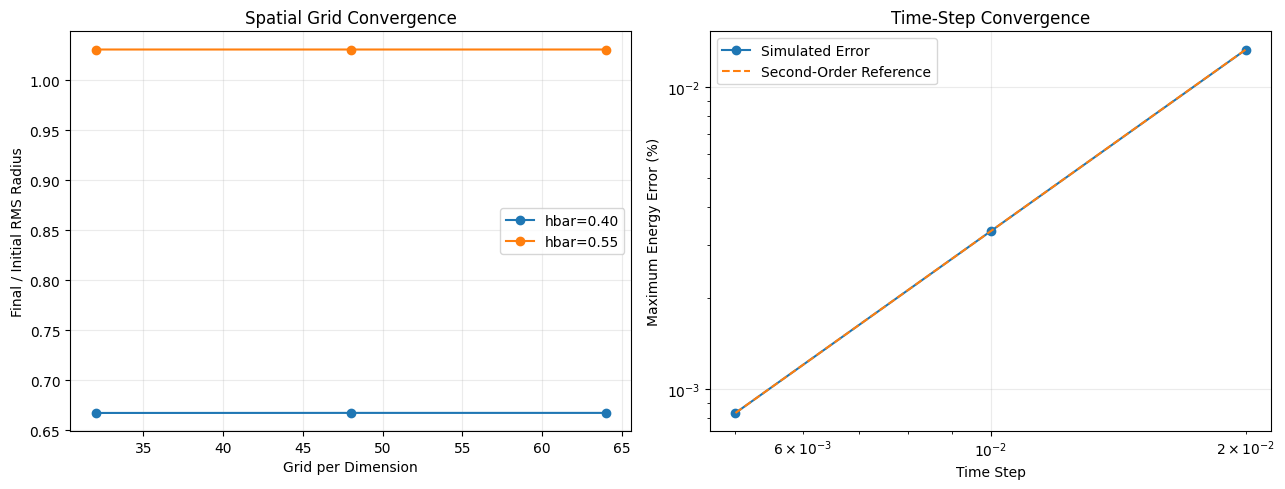

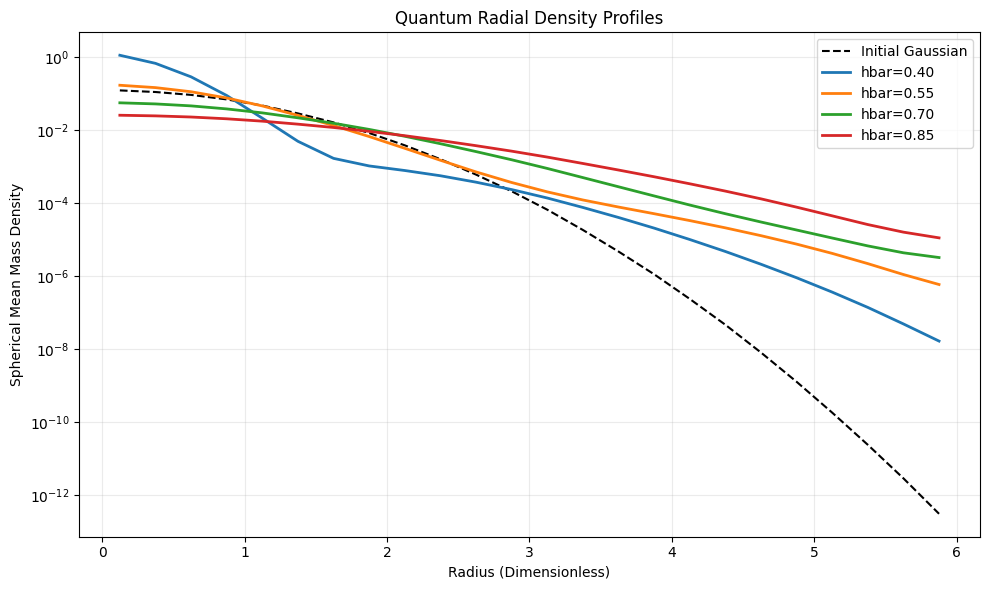

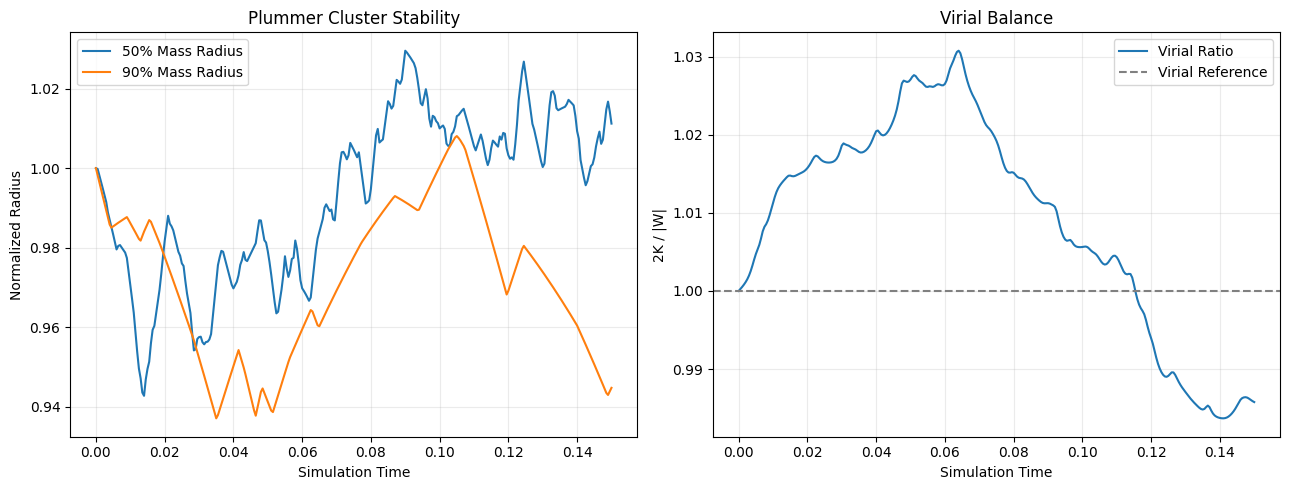

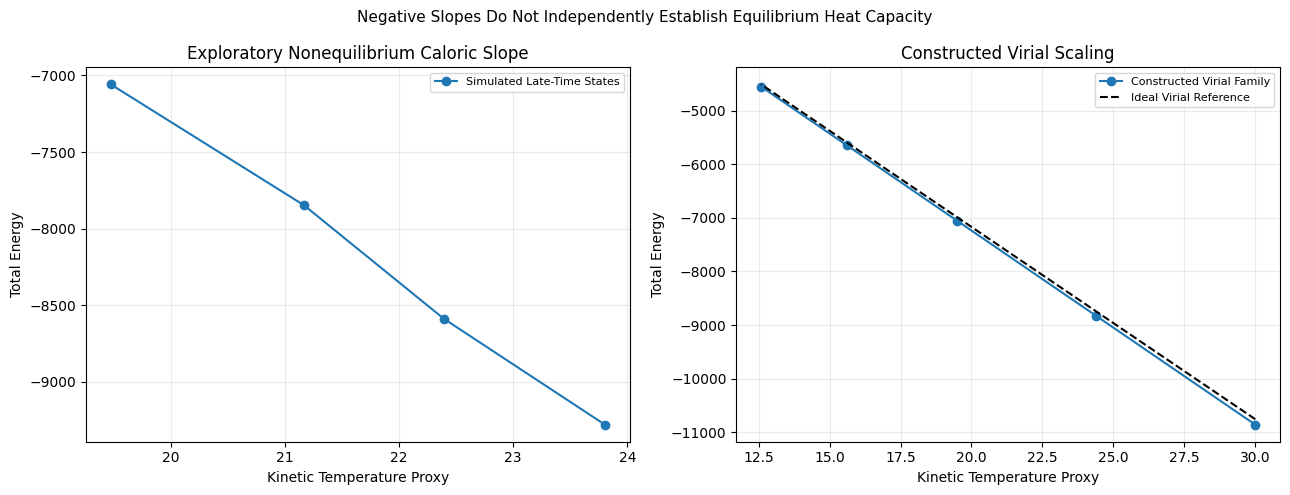

Saved datasets: 9
Saved PNG figures: 8
Saved PDF figures: 8
Matched-classical max energy error (%): 0.033964
Matched-classical max boundary fraction: 0.002500


In [33]:

# ============================================================
# CELL 33 - CORRECTED FINAL RESEARCH EXPORT
# Preserves every existing simulation
# Uses energy-matched Cell 32 as the main comparison
# ============================================================

import csv
import json
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# ---------- VERIFY REQUIRED RESULTS ----------

required33 = [
    "results24", "TIME24", "HBAR_VALUES24",
    "grid_results25", "dt_results25",
    "initial26", "structure26",
    "shell_radii26", "valid_shells26",
    "results31", "results32",
    "entropy_results28", "audit29",
    "time18", "r50_18", "r90_18",
    "virial18", "error18",
    "factors20", "energies20", "mean_T20",
    "mean_Q20", "temperature_drift20",
    "T21", "E21", "C_ideal21"
]

missing33 = [
    name for name in required33
    if name not in globals()
]

if missing33:
    raise RuntimeError(
        "Missing notebook variables: "
        + ", ".join(missing33)
        + ". Run the corresponding earlier cells."
    )

# ---------- OUTPUT FOLDERS ----------

ROOT33 = Path("/content/Gravity_Quantum_Final")

# Rebuild from scratch so stale datasets and figures from previous runs
# cannot affect counts, provenance, or the downloaded archive.
import shutil
if ROOT33.exists():
    shutil.rmtree(ROOT33)
print("Clean export directory initialized; previous generated outputs cleared.")
DATA33 = ROOT33 / "datasets"
FIG33 = ROOT33 / "figures"
DOC33 = ROOT33 / "documentation"

for folder in [DATA33, FIG33, DOC33]:
    folder.mkdir(parents=True, exist_ok=True)


def save_csv33(filename, rows):

    if not rows:
        raise ValueError("Empty dataset: " + filename)

    with (DATA33 / filename).open(
        "w", newline="", encoding="utf-8"
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=list(rows[0].keys())
        )

        writer.writeheader()
        writer.writerows(rows)


def save_figure33(fig, name):

    fig.tight_layout()

    fig.savefig(
        FIG33 / (name + ".png"),
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        FIG33 / (name + ".pdf"),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


HBARS33 = [float(h) for h in HBAR_VALUES24]

# ---------- VALIDATE MATCHED RUNS ----------

for h in HBARS33:

    assert (h, True) in results24
    assert (h, False) in results24

    matched_count = sum(
        np.isclose(r["hbar"], h)
        for r in results32
    )

    assert matched_count >= 2, (
        f"Insufficient classical runs for hbar={h}"
    )

# ============================================================
# DATASET 1 - ENERGY-MATCHED CLASSICAL VS QUANTUM
# ============================================================

comparison33 = []
individual33 = []

for h in HBARS33:

    classical_runs = [
        r for r in results32
        if np.isclose(r["hbar"], h)
    ]

    classical_radii = np.array([
        r["radius_ratio"]
        for r in classical_runs
    ])

    quantum = results24[(h, True)]
    quantum_free = results24[(h, False)]

    quantum_radius = (
        quantum["radius"][-1]
        / quantum["radius"][0]
    )

    quantum_free_radius = (
        quantum_free["radius"][-1]
        / quantum_free["radius"][0]
    )

    classical_free_radius = np.mean([
        r["free_ratio"]
        for r in classical_runs
    ])

    free_error = (
        100 * abs(
            classical_free_radius - quantum_free_radius
        ) / quantum_free_radius
    )

    comparison33.append({
        "effective_hbar": h,
        "quantum_final_R_over_R0": float(quantum_radius),
        "classical_matched_mean_R_over_R0": float(
            classical_radii.mean()
        ),
        "classical_matched_sd": float(
            classical_radii.std(ddof=1)
        ),
        "quantum_free_R_over_R0": float(
            quantum_free_radius
        ),
        "classical_free_mean_R_over_R0": float(
            classical_free_radius
        ),
        "free_control_difference_percent": float(free_error),
        "max_classical_energy_error_percent": float(
            max(r["max_energy_error"] for r in classical_runs)
        )
    })

    for run in classical_runs:

        individual33.append({
            "effective_hbar": h,
            "seed": int(run["seed"]),
            "final_R_over_R0": float(run["radius_ratio"]),
            "free_R_over_R0": float(run["free_ratio"]),
            "initial_classical_K": float(run["classical_K"]),
            "initial_quantum_K": float(run["quantum_K"]),
            "max_energy_error_percent": float(
                run["max_energy_error"]
            ),
            "max_boundary_fraction": float(
                run["max_boundary"]
            )
        })

save_csv33(
    "energy_matched_comparison.csv",
    comparison33
)

save_csv33(
    "individual_matched_classical_runs.csv",
    individual33
)

# ============================================================
# DATASET 2 - QUANTUM TIME SERIES
# ============================================================

quantum_series33 = []

for h in HBARS33:

    for gravity in [True, False]:

        result = results24[(h, gravity)]

        assert len(result["radius"]) == len(TIME24)

        for i, time in enumerate(TIME24):

            quantum_series33.append({
                "effective_hbar": h,
                "gravity_on": gravity,
                "time": float(time),
                "normalized_RMS_radius": float(
                    result["radius"][i]
                    / result["radius"][0]
                ),
                "peak_density": float(
                    result["peak"][i]
                ),
                "energy_error_percent": float(
                    result["energy_error"][i]
                )
            })

save_csv33(
    "quantum_wave_time_series.csv",
    quantum_series33
)

# ============================================================
# DATASET 3 - CLASSICAL CONVERGENCE
# ============================================================

convergence33 = []

for result in results31:

    convergence33.append({
        "grid": int(result["grid"]),
        "particles": int(result["particles"]),
        "seed": int(result["seed"]),
        "final_R_over_R0": float(result["radius"]),
        "central_mass_percent": float(result["central"]),
        "energy_error_percent": float(
            result["energy_error"]
        )
    })

save_csv33(
    "classical_convergence.csv",
    convergence33
)

# ============================================================
# DATASET 4 - SPATIAL SHANNON ENTROPY
# ============================================================

entropy_rows33 = []

for bins, result in sorted(entropy_results28.items()):

    for classical in result["classical"]:

        entropy_rows33.append({
            "model": "cold_classical",
            "hbar": "",
            "gravity_on": True,
            "bins_per_dimension": bins,
            "initial_H": float(classical["H_initial"]),
            "final_H": float(classical["H_final"]),
            "delta_H": float(classical["delta_H"]),
            "JS_divergence": float(classical["JS"])
        })

    for h in HBARS33:

        for gravity in [True, False]:

            quantum = result["quantum"][(h, gravity)]

            entropy_rows33.append({
                "model": "quantum_wave",
                "hbar": h,
                "gravity_on": gravity,
                "bins_per_dimension": bins,
                "initial_H": float(
                    result["quantum_H_initial"]
                ),
                "final_H": float(quantum["H_final"]),
                "delta_H": float(quantum["delta_H"]),
                "JS_divergence": float(quantum["JS"])
            })

save_csv33(
    "spatial_shannon_entropy.csv",
    entropy_rows33
)

# ============================================================
# DATASET 5 - QUANTUM CONVERGENCE
# ============================================================

grid_rows33 = []

for (h, n), result in sorted(grid_results25.items()):

    grid_rows33.append({
        "hbar": float(h),
        "grid": int(n),
        "final_R_over_R0": float(result["R_ratio"]),
        "final_peak_ratio": float(result["P_ratio"]),
        "energy_error_percent": float(
            result["energy_error"]
        )
    })

save_csv33(
    "quantum_grid_convergence.csv",
    grid_rows33
)

dt_rows33 = []

for dt, result in sorted(dt_results25.items()):

    dt_rows33.append({
        "time_step": float(dt),
        "final_R_over_R0": float(result["R_ratio"]),
        "final_peak_ratio": float(result["P_ratio"]),
        "energy_error_percent": float(
            result["energy_error"]
        )
    })

save_csv33(
    "quantum_timestep_convergence.csv",
    dt_rows33
)

# ============================================================
# FIGURE 1 - WAVE SELF-GRAVITY AND FREE-WAVE CONTROL
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

for h in HBARS33:

    result = results24[(h, True)]

    ax.plot(
        TIME24,
        result["radius"] / result["radius"][0],
        linewidth=2,
        label=f"Gravity ON, hbar={h:.2f}"
    )

for h in [HBARS33[0], HBARS33[-1]]:

    result = results24[(h, False)]

    ax.plot(
        TIME24,
        result["radius"] / result["radius"][0],
        "--",
        label=f"Gravity OFF, hbar={h:.2f}"
    )

ax.axhline(1.0, color="gray", linestyle=":")

ax.set(
    xlabel="Dimensionless Simulation Time",
    ylabel="RMS Radius / Initial RMS Radius",
    title="Quantum Dispersion versus Self-Gravity"
)

ax.grid(alpha=0.25)
ax.legend(fontsize=8)

save_figure33(
    fig, "01_quantum_gravity_dispersion"
)

# ============================================================
# FIGURE 2 - CORRECTED CLASSICAL-QUANTUM COMPARISON
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

classical_mean33 = [
    r["classical_matched_mean_R_over_R0"]
    for r in comparison33
]

classical_sd33 = [
    r["classical_matched_sd"]
    for r in comparison33
]

quantum_radius33 = [
    r["quantum_final_R_over_R0"]
    for r in comparison33
]

ax.errorbar(
    HBARS33,
    classical_mean33,
    yerr=classical_sd33,
    fmt="o-",
    capsize=4,
    linewidth=2,
    label="Kinetic-energy-matched classical"
)

ax.plot(
    HBARS33,
    quantum_radius33,
    "s-",
    linewidth=2,
    label="Schrodinger-Poisson wave"
)

ax.axhline(1.0, color="gray", linestyle=":")

ax.set(
    xlabel="Effective hbar (Dimensionless)",
    ylabel="Final / Initial RMS Radius",
    title="Controlled Classical versus Quantum Dynamics"
)

ax.grid(alpha=0.25)
ax.legend()

save_figure33(
    fig, "02_corrected_classical_quantum"
)

# ============================================================
# FIGURE 3 - CLASSICAL MESH CONVERGENCE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for seed in [2026, 40]:

    subset = sorted(
        [
            r for r in results31
            if r["seed"] == seed
            and r["particles"] == 4000
        ],
        key=lambda r: r["grid"]
    )

    axes[0].plot(
        [r["grid"] for r in subset],
        [r["radius"] for r in subset],
        "o-",
        label=f"Seed {seed}"
    )

    axes[1].plot(
        [r["grid"] for r in subset],
        [r["central"] for r in subset],
        "o-",
        label=f"Seed {seed}"
    )

axes[0].set(
    xlabel="Grid Cells per Dimension",
    ylabel="Final / Initial RMS Radius",
    title="Classical Cloud-Size Convergence"
)

axes[1].set(
    xlabel="Grid Cells per Dimension",
    ylabel="Central Mass Fraction (%)",
    title="Central Structure Resolution Sensitivity"
)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

save_figure33(
    fig, "03_classical_convergence"
)

# ============================================================
# FIGURE 4 - SPATIAL ENTROPY
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

main_entropy33 = entropy_results28[12]

for gravity, style in [
    (True, "o-"),
    (False, "s--")
]:

    changes = [
        main_entropy33["quantum"][
            (h, gravity)
        ]["delta_H"]
        for h in HBARS33
    ]

    ax.plot(
        HBARS33,
        changes,
        style,
        linewidth=2,
        label=(
            "Wave with Newtonian gravity"
            if gravity
            else "Free wave (gravity off)"
        )
    )

cold_entropy33 = np.mean([
    r["delta_H"]
    for r in main_entropy33["classical"]
])

ax.axhline(
    cold_entropy33,
    color="black",
    linestyle=":",
    label="Cold Classical Baseline"
)

ax.axhline(0.0, color="gray", linestyle="--")

ax.set(
    xlabel="Effective hbar",
    ylabel="Change in Spatial Shannon Entropy (nats)",
    title="Spatial Shannon Entropy Change vs Effective hbar"
)

ax.legend()
ax.grid(alpha=0.25)

save_figure33(
    fig, "04_spatial_shannon_entropy"
)

# ============================================================
# FIGURE 5 - QUANTUM NUMERICAL CONVERGENCE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for h in [0.40, 0.55]:

    grids = [32, 48, 64]

    radii = [
        grid_results25[(h, n)]["R_ratio"]
        for n in grids
    ]

    axes[0].plot(
        grids, radii, "o-",
        label=f"hbar={h:.2f}"
    )

dt_values33 = np.array(
    sorted(dt_results25)
)

errors33 = np.array([
    dt_results25[dt]["energy_error"]
    for dt in dt_values33
])

axes[1].loglog(
    dt_values33,
    errors33,
    "o-",
    label="Simulated Error"
)

axes[1].loglog(
    dt_values33,
    errors33[0] * (
        dt_values33 / dt_values33[0]
    )**2,
    "--",
    label="Second-Order Reference"
)

axes[0].set(
    xlabel="Grid per Dimension",
    ylabel="Final / Initial RMS Radius",
    title="Spatial Grid Convergence"
)

axes[1].set(
    xlabel="Time Step",
    ylabel="Maximum Energy Error (%)",
    title="Time-Step Convergence"
)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

save_figure33(
    fig, "05_quantum_numerical_convergence"
)

# ============================================================
# FIGURE 6 - QUANTUM RADIAL DENSITY
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogy(
    shell_radii26[valid_shells26],
    np.maximum(
        initial26["profile"][valid_shells26],
        1e-15
    ),
    "k--",
    label="Initial Gaussian"
)

for h in HBARS33:

    profile = structure26[(h, True)]["profile"]

    ax.semilogy(
        shell_radii26[valid_shells26],
        np.maximum(profile[valid_shells26], 1e-15),
        linewidth=2,
        label=f"hbar={h:.2f}"
    )

ax.set(
    xlabel="Radius (Dimensionless)",
    ylabel="Spherical Mean Mass Density",
    title="Quantum Radial Density Profiles"
)

ax.grid(alpha=0.25)
ax.legend()

save_figure33(
    fig, "06_quantum_radial_density"
)

# ============================================================
# FIGURE 7 - PLUMMER CLUSTER STABILITY
# ============================================================

plummer_rows33 = []

for t, r50, r90, q, error in zip(
    time18, r50_18, r90_18, virial18, error18
):

    plummer_rows33.append({
        "time": float(t),
        "R50_normalized": float(r50/r50_18[0]),
        "R90_normalized": float(r90/r90_18[0]),
        "virial_ratio": float(q),
        "energy_error_percent": float(error)
    })

save_csv33(
    "plummer_cluster_stability.csv",
    plummer_rows33
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    time18,
    r50_18/r50_18[0],
    label="50% Mass Radius"
)

axes[0].plot(
    time18,
    r90_18/r90_18[0],
    label="90% Mass Radius"
)

axes[1].plot(
    time18,
    virial18,
    label="Virial Ratio"
)

axes[1].axhline(
    1.0,
    linestyle="--",
    color="gray",
    label="Virial Reference"
)

axes[0].set(
    xlabel="Simulation Time",
    ylabel="Normalized Radius",
    title="Plummer Cluster Stability"
)

axes[1].set(
    xlabel="Simulation Time",
    ylabel="2K / |W|",
    title="Virial Balance"
)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

save_figure33(
    fig, "07_plummer_cluster_stability"
)

# ============================================================
# FIGURE 8 - QUALIFIED GRAVITATIONAL CALORIC RELATION
# ============================================================

thermal_rows33 = []

for f, E, T, Q, drift in zip(
    factors20,
    energies20,
    mean_T20,
    mean_Q20,
    temperature_drift20
):

    thermal_rows33.append({
        "initial_velocity_factor": float(f),
        "total_energy": float(E),
        "late_kinetic_temperature_proxy": float(T),
        "late_virial_ratio": float(Q),
        "late_temperature_drift_percent": float(drift),
        "equilibrium_heat_capacity_verified": False
    })

save_csv33(
    "exploratory_gravitational_caloric.csv",
    thermal_rows33
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    mean_T20,
    energies20,
    "o-",
    label="Simulated Late-Time States"
)

axes[1].plot(
    T21,
    E21,
    "o-",
    label="Constructed Virial Family"
)

axes[1].plot(
    T21,
    C_ideal21*np.asarray(T21),
    "k--",
    label="Ideal Virial Reference"
)

axes[0].set(
    xlabel="Kinetic Temperature Proxy",
    ylabel="Total Energy",
    title="Exploratory Nonequilibrium Caloric Slope"
)

axes[1].set(
    xlabel="Kinetic Temperature Proxy",
    ylabel="Total Energy",
    title="Constructed Virial Scaling"
)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "Negative Slopes Do Not Independently "
    "Establish Equilibrium Heat Capacity",
    fontsize=11
)

save_figure33(
    fig, "08_qualified_gravitational_caloric"
)

# ============================================================
# SCIENTIFIC AUDIT AND LIMITATIONS
# ============================================================

def json_safe33(value):

    if isinstance(value, dict):
        return {
            str(k): json_safe33(v)
            for k, v in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [json_safe33(v) for v in value]

    if isinstance(value, np.ndarray):
        return json_safe33(value.tolist())

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    return value


with (DOC33 / "scientific_audit.json").open(
    "w", encoding="utf-8"
) as file:

    json.dump(
        json_safe33(audit29),
        file,
        indent=2,
        allow_nan=False
    )


limitations33 = """
# Scientific Interpretation and Limitations

## Main findings

The three-dimensional Schrodinger-Poisson model shows
finite-time contraction or expansion depending on
the effective quantum parameter.

The energy-matched classical particle experiment
provides a more controlled comparison than the
original cold-particle baseline.

The spatial Shannon entropy calculation describes
coarse-grained mass distribution, not total
thermodynamic entropy.

## Important limitations

1. All model values are in dimensionless units.
2. Effective hbar is a simulation parameter.
3. The quantum-wave model is not quantum gravity.
4. The Poisson model uses periodic boundaries.
5. The classical central mass estimate remains
   sensitive to mesh resolution.
6. Kinetic-energy matching improves the comparison,
   but classical particles and quantum matter waves
   are still different physical descriptions.
7. The contraction-expansion crossover applies to
   the simulated initial conditions and final time.
8. Spatial Shannon entropy does not establish
   the Second Law of Thermodynamics.
9. The Plummer virial-scaling family is constructed,
   rather than an independent experimental discovery.
10. Equilibrium negative heat capacity has not
    been independently established.
11. All conclusions require the stated numerical
    and physical assumptions.
12. Results have not been observationally calibrated.

## Reproducibility

The complete Google Colab notebook is the source
code and must accompany these results.

A clean, sequential notebook run should be
performed before final submission.
"""

(DOC33 / "interpretation_and_limitations.md").write_text(
    limitations33,
    encoding="utf-8"
)

readme33 = """
# Classical and Quantum-Wave Self-Gravitating Systems

This package contains:

- Numerical CSV datasets
- Eight selected research figures in PNG and PDF
- Scientific audit results
- Interpretation and limitations document

The authoritative source code is the original
Google Colab notebook, which must be saved separately.

The primary classical-quantum comparison is the
kinetic-energy-matched experiment from Cell 32.

The original cold classical simulation remains a
separate initial-condition experiment.

These results constitute a dimensionless computational
investigation, not an observational prediction.
"""

(DOC33 / "initial_export_notes.md").write_text(
    readme33,
    encoding="utf-8"
)

# ============================================================
# RESULTS EXPORT SUMMARY (FINAL ZIP IS CREATED IN LAST CELL)
# ============================================================

print("Saved datasets:", len(list(DATA33.glob("*.csv"))))
print("Saved PNG figures:", len(list(FIG33.glob("*.png"))))
print("Saved PDF figures:", len(list(FIG33.glob("*.pdf"))))
print("Matched-classical max energy error (%):", f"{max(r['max_energy_error'] for r in results32):.6f}")
print("Matched-classical max boundary fraction:", f"{max(r['max_boundary'] for r in results32):.6f}")


Running effective hbar=0.40, box=12^3
Running effective hbar=0.40, box=16^3
Running effective hbar=0.40, box=20^3
Running effective hbar=0.55, box=12^3
Running effective hbar=0.55, box=16^3
Running effective hbar=0.55, box=20^3
Running effective hbar=0.70, box=12^3
Running effective hbar=0.70, box=16^3
Running effective hbar=0.70, box=20^3
Running effective hbar=0.85, box=12^3
Running effective hbar=0.85, box=16^3
Running effective hbar=0.85, box=20^3

FINAL 3D SCHRODINGER-POISSON NUMERICAL AUDIT
Poisson residual: 5.847e-14
Time-reversal error: 9.010e-15
Maximum mass error (%): 2.23154828e-11
Maximum energy error (%): 0.010106
Maximum free-Gaussian error (%): 0.082805
Time-step convergence order: 1.9998

FINITE-BOX RESULTS
hbar     L=12          L=16          L=20          Difference %
0.40     0.667327      0.662028      0.660150      1.0872
0.55     1.030831      1.025403      1.023474      0.7188
0.70     1.406418      1.400969      1.398975      0.5320
0.85     1.778899      1.7737

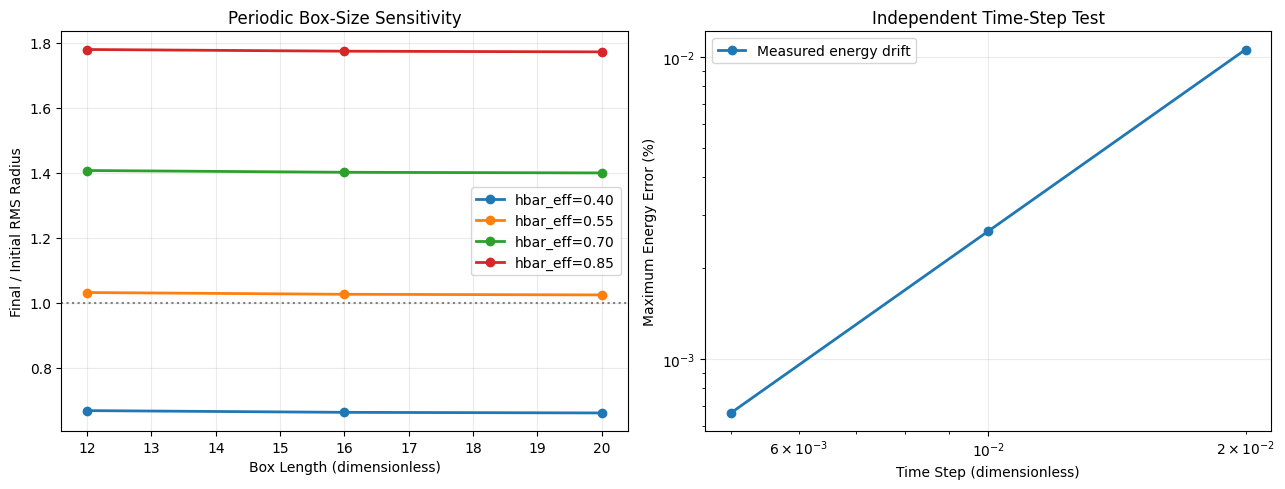


NUMERICAL CHECK RESULTS ARE LISTED ABOVE
NUMERICAL VALIDATION FILES SAVED
Output folder: /content/Gravity_Quantum_Final/additional_validation
Existing simulation data were not overwritten.
END OF VALIDATION


In [34]:

# ============================================================
# FINAL 3D SCHRODINGER-POISSON VALIDATION — CORRECTED CELL
# Dimensionless model; periodic Newtonian gravity
# Independent box-size and time-step validation.
# ============================================================

import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft

G_VALIDATION, MASS_VALIDATION, SIGMA_VALIDATION = 1.0, 1.0, 0.8
EFFECTIVE_HBARS = (0.40, 0.55, 0.70, 0.85)
BOX_LENGTHS = (12.0, 16.0, 20.0)
GRID_SPACING = 0.25
FINAL_TIME, TIME_STEP = 3.0, 0.01


# ============================================================
# 1. THREE-DIMENSIONAL GRAVITATIONAL WAVE MODEL
# ============================================================

class GravityWave3D:

    def __init__(self, length):
        self.L = float(length)
        self.dx = GRID_SPACING
        self.n = round(self.L / self.dx)

        assert self.n % 2 == 0 and np.isclose(
            self.n * self.dx, self.L
        )

        c = (np.arange(self.n) - self.n // 2) * self.dx

        self.radius_squared = (
            c[:, None, None]**2
            + c[None, :, None]**2
            + c[None, None, :]**2
        )

        k = 2 * np.pi * fft.fftfreq(self.n, d=self.dx)

        self.k2 = (
            k[:, None, None]**2
            + k[None, :, None]**2
            + k[None, None, :]**2
        )

        self.poisson_kernel = np.zeros_like(self.k2)
        nonzero = self.k2 > 0

        self.poisson_kernel[nonzero] = (
            -4 * np.pi * G_VALIDATION / self.k2[nonzero]
        )

        edge = np.abs(c) >= self.L / 2 - 2 * self.dx

        self.boundary_mask = (
            edge[:, None, None]
            | edge[None, :, None]
            | edge[None, None, :]
        )

    def initial_state(self):

        psi = np.exp(
            -self.radius_squared / (4 * SIGMA_VALIDATION**2)
        ).astype(np.complex128)

        initial_mass = (
            np.sum(np.abs(psi)**2) * self.dx**3
        )

        return psi * np.sqrt(MASS_VALIDATION / initial_mass)

    def potential(self, rho):

        # Periodic Poisson equation with mean-density subtraction
        return fft.ifftn(
            fft.fftn(rho) * self.poisson_kernel
        ).real

    def measure(self, psi, phi, hbar):

        rho = np.abs(psi)**2
        mass = np.sum(rho) * self.dx**3
        psi_k = fft.fftn(psi)

        kinetic = (
            0.5 * hbar**2 * self.dx**3 / self.n**3
            * np.sum(self.k2 * np.abs(psi_k)**2)
        )

        gravitational = (
            0.5 * np.sum(rho * phi) * self.dx**3
        )

        rms_radius = np.sqrt(
            np.sum(rho * self.radius_squared)
            * self.dx**3 / mass
        )

        boundary_fraction = (
            np.sum(rho[self.boundary_mask])
            * self.dx**3 / mass
        )

        return tuple(map(float, (
            mass,
            kinetic + gravitational,
            rms_radius,
            np.max(rho),
            boundary_fraction
        )))

    def step(self, psi, phi, hbar, dt):

        # Symmetric Strang splitting
        psi = psi * np.exp(
            -0.5j * dt * phi / hbar
        )

        psi = fft.ifftn(
            fft.fftn(psi)
            * np.exp(-0.5j * hbar * self.k2 * dt)
        )

        phi = self.potential(np.abs(psi)**2)

        psi = psi * np.exp(
            -0.5j * dt * phi / hbar
        )

        return psi, phi


# ============================================================
# 2. FULL SIMULATION AND CONSERVATION CHECKS
# ============================================================

def simulate(length, hbar, dt=TIME_STEP, gravity=True):

    model = GravityWave3D(length)
    steps = round(FINAL_TIME / dt)

    assert np.isclose(steps * dt, FINAL_TIME)

    psi = model.initial_state()

    if gravity:
        phi = model.potential(np.abs(psi)**2)
    else:
        phi = np.zeros_like(psi.real)

    mass0, energy0, radius0, peak0, _ = (
        model.measure(psi, phi, hbar)
    )

    history = []

    kinetic_operator = (
        None if gravity
        else np.exp(-0.5j * hbar * model.k2 * dt)
    )

    for step in range(steps + 1):

        if (
            step == 0
            or step == steps
            or step % max(1, steps // 30) == 0
        ):

            mass, energy, radius, peak, edge = (
                model.measure(psi, phi, hbar)
            )

            history.append([
                step * dt,
                radius / radius0,
                peak / peak0,
                100 * abs(mass - mass0) / mass0,
                100 * abs(energy - energy0)
                / max(abs(energy0), 1e-12),
                edge
            ])

        if step == steps:
            break

        if gravity:
            psi, phi = model.step(
                psi, phi, hbar, dt
            )
        else:
            psi = fft.ifftn(
                fft.fftn(psi) * kinetic_operator
            )

    history = np.asarray(history)

    assert np.all(np.isfinite(history))

    return {
        "length": float(length),
        "hbar": float(hbar),
        "dt": float(dt),
        "radius_ratio": float(history[-1, 1]),
        "peak_ratio": float(history[-1, 2]),
        "mass_error": float(np.max(history[:, 3])),
        "energy_error": float(np.max(history[:, 4])),
        "boundary_fraction": float(np.max(history[:, 5])),
        "final_radius": float(
            history[-1, 1] * radius0
        ),
        "history": history
    }


# ============================================================
# 3. INDEPENDENT POISSON SOLVER TEST
# ============================================================

test_model = GravityWave3D(12.0)

psi0 = test_model.initial_state()
rho0 = np.abs(psi0)**2
phi0 = test_model.potential(rho0)

laplacian = fft.ifftn(
    -test_model.k2 * fft.fftn(phi0)
).real

rhs = (
    4 * np.pi * G_VALIDATION
    * (rho0 - np.mean(rho0))
)

poisson_error = float(
    np.linalg.norm(laplacian - rhs)
    / np.linalg.norm(rhs)
)

assert poisson_error < 1e-10


# ============================================================
# 4. NONLINEAR TIME-REVERSAL TEST
# ============================================================

psi_reverse = psi0.copy()
phi_reverse = phi0.copy()

for _ in range(10):
    psi_reverse, phi_reverse = test_model.step(
        psi_reverse, phi_reverse, 0.40, 0.01
    )

for _ in range(10):
    psi_reverse, phi_reverse = test_model.step(
        psi_reverse, phi_reverse, 0.40, -0.01
    )

reversibility_error = float(
    np.linalg.norm(psi_reverse - psi0)
    / np.linalg.norm(psi0)
)

assert reversibility_error < 1e-9


# ============================================================
# 5. PERIODIC BOX-SIZE SENSITIVITY
# ============================================================

results = {}

for hbar in EFFECTIVE_HBARS:

    for length in BOX_LENGTHS:

        print(
            f"Running effective hbar={hbar:.2f}, "
            f"box={length:g}^3"
        )

        results[(hbar, length)] = simulate(
            length, hbar
        )


# ============================================================
# 6. ANALYTICAL FREE-GAUSSIAN BENCHMARK
# ============================================================

free_errors = {}

for hbar in EFFECTIVE_HBARS:

    numerical = simulate(
        12.0, hbar, gravity=False
    )

    sigma_t = np.sqrt(
        SIGMA_VALIDATION**2
        + (hbar * FINAL_TIME / (2 * SIGMA_VALIDATION))**2
    )

    analytical_radius = np.sqrt(3) * sigma_t

    free_errors[hbar] = float(
        100
        * abs(
            numerical["final_radius"]
            - analytical_radius
        )
        / analytical_radius
    )


# ============================================================
# 7. INDEPENDENT TIME-STEP CONVERGENCE
# ============================================================

dt_results = {}

for dt in (0.020, 0.010, 0.005):

    if dt == 0.010:
        dt_results[dt] = results[(0.40, 20.0)]
    else:
        dt_results[dt] = simulate(
            20.0, 0.40, dt=dt
        )

r1, r2, r3 = (
    dt_results[d]["radius_ratio"]
    for d in (0.020, 0.010, 0.005)
)

difference_1 = abs(r1 - r2)
difference_2 = abs(r2 - r3)

if difference_1 > 1e-14 and difference_2 > 1e-14:

    convergence_order = float(
        np.log2(difference_1 / difference_2)
    )

else:
    convergence_order = float("nan")


# ============================================================
# 8. NUMERICAL AUDIT
# ============================================================

max_mass_error = max(
    r["mass_error"]
    for r in results.values()
)

max_energy_error = max(
    r["energy_error"]
    for r in results.values()
)

max_free_error = max(free_errors.values())

# All booleans explicitly converted to Python bool
checks = {
    "Poisson solver": bool(
        poisson_error < 1e-10
    ),
    "Time reversibility": bool(
        reversibility_error < 1e-9
    ),
    "Mass conservation": bool(
        max_mass_error < 1e-7
    ),
    "Energy conservation": bool(
        max_energy_error < 0.1
    ),
    "Analytical Gaussian benchmark": bool(
        max_free_error < 1.0
    ),
    "Second-order time-step convergence": bool(
        1.7 < convergence_order < 2.3
    )
}

print("\n" + "=" * 68)
print("FINAL 3D SCHRODINGER-POISSON NUMERICAL AUDIT")
print("=" * 68)

print(
    f"Poisson residual: {poisson_error:.3e}"
)

print(
    f"Time-reversal error: {reversibility_error:.3e}"
)

print(
    f"Maximum mass error (%): {max_mass_error:.8e}"
)

print(
    f"Maximum energy error (%): {max_energy_error:.6f}"
)

print(
    f"Maximum free-Gaussian error (%): "
    f"{max_free_error:.6f}"
)

print(
    f"Time-step convergence order: "
    f"{convergence_order:.4f}"
)


# ============================================================
# 9. FINITE-BOX RESULTS
# ============================================================

print("\nFINITE-BOX RESULTS")

print(
    f"{'hbar':<9}"
    f"{'L=12':<14}"
    f"{'L=16':<14}"
    f"{'L=20':<14}"
    f"Difference %"
)

rows = []

for hbar in EFFECTIVE_HBARS:

    radii = [
        results[(hbar, L)]["radius_ratio"]
        for L in BOX_LENGTHS
    ]

    difference = float(
        100 * abs(radii[0] - radii[-1])
        / abs(radii[-1])
    )

    print(
        f"{hbar:<9.2f}"
        f"{radii[0]:<14.6f}"
        f"{radii[1]:<14.6f}"
        f"{radii[2]:<14.6f}"
        f"{difference:.4f}"
    )

    rows.append({
        "effective_hbar": float(hbar),
        "R_ratio_L12": radii[0],
        "R_ratio_L16": radii[1],
        "R_ratio_L20": radii[2],
        "L12_vs_L20_percent": difference,
        "free_gaussian_error_percent": free_errors[hbar]
    })

print("\nVALIDATION CHECKLIST")

for label, passed in checks.items():

    print(
        ("PASS" if passed else "REVIEW"),
        "|", label
    )


# ============================================================
# 10. RESEARCH FIGURES
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5)
)

for hbar in EFFECTIVE_HBARS:

    axes[0].plot(
        BOX_LENGTHS,
        [
            results[(hbar, L)]["radius_ratio"]
            for L in BOX_LENGTHS
        ],
        "o-",
        linewidth=2,
        label=f"hbar_eff={hbar:.2f}"
    )

axes[0].axhline(
    1.0,
    linestyle=":",
    color="gray"
)

axes[0].set_title(
    "Periodic Box-Size Sensitivity"
)

axes[0].set_xlabel(
    "Box Length (dimensionless)"
)

axes[0].set_ylabel(
    "Final / Initial RMS Radius"
)

axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].loglog(
    (0.005, 0.010, 0.020),
    [
        dt_results[d]["energy_error"]
        for d in (0.005, 0.010, 0.020)
    ],
    "o-",
    linewidth=2,
    label="Measured energy drift"
)

axes[1].set_title(
    "Independent Time-Step Test"
)

axes[1].set_xlabel(
    "Time Step (dimensionless)"
)

axes[1].set_ylabel(
    "Maximum Energy Error (%)"
)

axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()


# ============================================================
# 11. SAVE FINAL VALIDATION OUTPUTS
# ============================================================

project = Path(
    "/content/Gravity_Quantum_Final"
)

if project.is_dir():

    output_dir = (
        project / "additional_validation"
    )

else:

    output_dir = Path(
        "/content/Gravity_Quantum_Validation"
    )

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    output_dir / "box_size_and_timestep_validation.png",
    dpi=220,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "box_size_and_timestep_validation.pdf",
    bbox_inches="tight"
)

plt.show()

with (
    output_dir / "box_size_results.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(rows[0])
    )

    writer.writeheader()
    writer.writerows(rows)


# ============================================================
# 12. PERMANENT JSON ERROR FIX
# ============================================================

audit = {
    "model": "3D dimensionless Schrodinger-Poisson",
    "gravity": "Periodic Newtonian gravity",

    "checks": {
        str(k): bool(v)
        for k, v in checks.items()
    },

    "poisson_residual": float(poisson_error),

    "time_reversal_error": float(reversibility_error),

    "convergence_order": float(convergence_order),

    "max_mass_error_percent": float(max_mass_error),

    "max_energy_error_percent": float(max_energy_error),

    "max_free_gaussian_error_percent": float(max_free_error),

    "all_checks_passed": bool(all(checks.values()))
}

with (
    output_dir / "numerical_audit.json"
).open("w", encoding="utf-8") as file:

    json.dump(
        audit,
        file,
        indent=2,
        allow_nan=False
    )


# ============================================================
# 13. SCIENTIFIC INTERPRETATION
# ============================================================

limitations = """
# Model Definition and Scientific Limitations

This is a three-dimensional, dimensionless numerical
investigation of classical and quantum-wave self-gravity,
not quantum gravity.

The wave model uses the Schrodinger-Poisson equations,
periodic boundary conditions and a Fourier Poisson solver
with mean-density subtraction.

Effective hbar is dimensionless and not physically calibrated.

Finite-box sensitivity is measured; a periodic box is not
an isolated gravitational system.

Numerical conservation tests do not prove physical completeness.

Spatial Shannon entropy describes coarse-grained structure,
not total thermodynamic entropy.

The negative caloric slope is exploratory and does not
establish equilibrium heat capacity.

The original cold classical baseline differs from the
kinetic-energy-matched classical control.

Classical particle-mesh central concentration is
resolution-sensitive.

Findings apply to the stated assumptions, parameters
and simulation duration.
"""

(
    output_dir / "scientific_interpretation.md"
).write_text(
    limitations,
    encoding="utf-8"
)


# ============================================================
# 14. FINAL STATUS
# ============================================================

print("\n" + "=" * 68)

if all(checks.values()):

    print("NUMERICAL CHECK RESULTS ARE LISTED ABOVE")

else:

    print("NUMERICAL REVIEW REQUIRED")

print("NUMERICAL VALIDATION FILES SAVED")

print("Output folder:", output_dir)

print("Existing simulation data were not overwritten.")

print("END OF VALIDATION")


INITIAL ENERGY BALANCE VS CLOUD EVOLUTION
hbar_eff    K/|U|          Final R/R0     
0.40        0.396029       0.667327       
0.55        0.748743       1.030831       
0.70        1.212840       1.406418       
0.85        1.788320       1.778899       


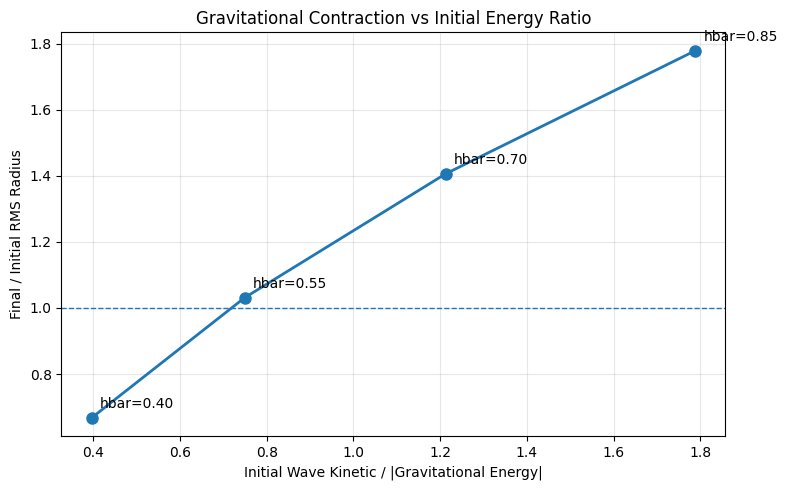


INTERPRETATION:
Low initial energy ratio: contraction observed.
Higher initial energy ratios: expansion observed.
This is a finite-time result, not a universal threshold.


In [35]:

# ============================================================
# PHYSICAL INTERPRETATION: INITIAL ENERGY RATIO
# Uses existing Schrödinger-Poisson simulation results.
# No gravitational simulations are rerun.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import csv
from pathlib import Path

required = [
    "initial_psi24", "results24", "HBAR_VALUES24",
    "solve_poisson_Q", "K2Q", "DXQ", "NQ"
]

missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError("Run previous cells first: " + str(missing))

psi0 = initial_psi24.copy()
rho0 = np.abs(psi0)**2
phi0 = solve_poisson_Q(rho0)

# Initial gravitational potential energy
U0 = float(
    0.5 * np.sum(rho0 * phi0) * DXQ**3
)

# Initial wave kinetic energy = hbar_eff^2 * K_coefficient
K_coefficient = float(
    0.5 * DXQ**3 / NQ**3
    * np.sum(K2Q * np.abs(np.fft.fftn(psi0))**2)
)

assert U0 < 0
assert K_coefficient > 0

rows = []

for hbar in HBAR_VALUES24:
    hbar = float(hbar)

    K0 = hbar**2 * K_coefficient
    chi0 = K0 / abs(U0)

    result = results24[(hbar, True)]
    radius = np.asarray(result["radius"], dtype=float)

    radius_ratio = float(radius[-1] / radius[0])

    rows.append({
        "effective_hbar": hbar,
        "initial_wave_kinetic_energy": K0,
        "initial_gravitational_energy": U0,
        "initial_energy_ratio": chi0,
        "final_over_initial_rms_radius": radius_ratio
    })

print("INITIAL ENERGY BALANCE VS CLOUD EVOLUTION")
print("=" * 65)
print(f"{'hbar_eff':<12}{'K/|U|':<15}{'Final R/R0':<15}")

for r in rows:
    print(
        f"{r['effective_hbar']:<12.2f}"
        f"{r['initial_energy_ratio']:<15.6f}"
        f"{r['final_over_initial_rms_radius']:<15.6f}"
    )

x = np.array([r["initial_energy_ratio"] for r in rows])
y = np.array([r["final_over_initial_rms_radius"] for r in rows])

assert np.all(np.isfinite(x))
assert np.all(np.isfinite(y))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y, "o-", linewidth=2, markersize=8)
ax.axhline(1, linestyle="--", linewidth=1)

for r in rows:
    ax.annotate(
        f"hbar={r['effective_hbar']:.2f}",
        (
            r["initial_energy_ratio"],
            r["final_over_initial_rms_radius"]
        ),
        xytext=(6, 7),
        textcoords="offset points"
    )

ax.set_xlabel("Initial Wave Kinetic / |Gravitational Energy|")
ax.set_ylabel("Final / Initial RMS Radius")
ax.set_title("Gravitational Contraction vs Initial Energy Ratio")
ax.grid(alpha=0.3)
fig.tight_layout()

root = Path("/content/Gravity_Quantum_Final")
data_dir = root / "datasets"
fig_dir = root / "figures"

data_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

with (data_dir / "initial_energy_ratio.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

fig.savefig(
    fig_dir / "09_initial_energy_ratio.png",
    dpi=300, bbox_inches="tight"
)

fig.savefig(
    fig_dir / "09_initial_energy_ratio.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nINTERPRETATION:")
print("Low initial energy ratio: contraction observed.")
print("Higher initial energy ratios: expansion observed.")
print("This is a finite-time result, not a universal threshold.")



TWO-SCALE WAVE STRUCTURE | dimensionless t = 3
hbar    R/R0    Fcore/Fcore0    peak/peak0    expansion + core growth
0.40     0.6673   3.3704          9.1826        False
0.55     1.0308   1.2157          1.3849        True
0.70     1.4064   0.5029          0.4572        False
0.85     1.7789   0.2507          0.2089        False


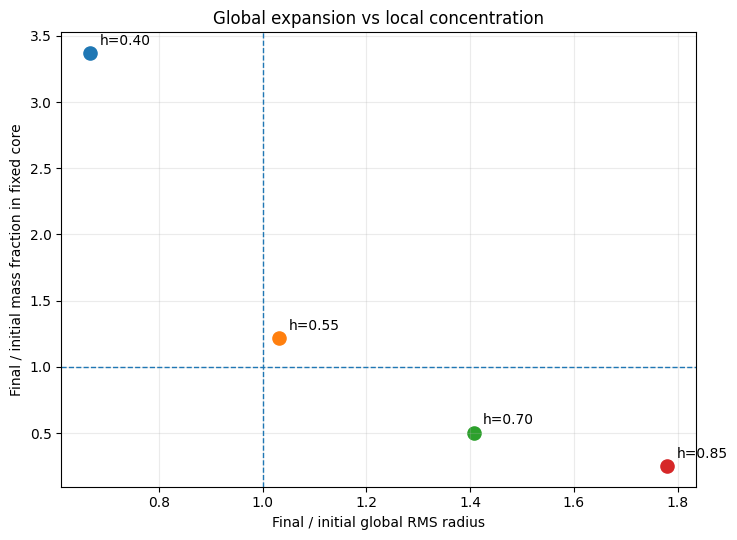

This diagnostic finds candidate behaviour only; verify at finer hbar, grid and box sizes.


In [36]:
# =============================================================
# TWO-SCALE DIAGNOSTIC: LOCAL CONCENTRATION VS GLOBAL EXPANSION
# Uses stored 3D Schrodinger-Poisson runs; no simulation rerun.
# =============================================================

import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

needed = ["results24", "HBAR_VALUES24", "R2_24", "SIGMA_Q", "DXQ", "initial_psi24"]
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError("Run the earlier 3D wave cells first: " + ", ".join(missing))

# A core means radius <= initial Gaussian width. This is a fixed diagnostic,
# not a fitted soliton radius or proof of a gravitationally bound object.
core_mask = R2_24 <= SIGMA_Q**2
rho_initial = np.abs(initial_psi24)**2
initial_total = np.sum(rho_initial) * DXQ**3
initial_core = (np.sum(rho_initial[core_mask]) * DXQ**3) / initial_total

rows_core = []
for hbar in HBAR_VALUES24:
    result = results24[(hbar, True)]
    rho = np.asarray(result["final_density"])
    mass = np.sum(rho) * DXQ**3
    core_final = (np.sum(rho[core_mask]) * DXQ**3) / mass
    radius_ratio = float(result["radius"][-1] / result["radius"][0])
    peak_ratio = float(result["peak"][-1] / result["peak"][0])
    core_ratio = float(core_final / initial_core)

    rows_core.append({
        "effective_hbar": float(hbar),
        "global_radius_ratio": radius_ratio,
        "central_mass_fraction_initial": float(initial_core),
        "central_mass_fraction_final": float(core_final),
        "central_mass_fraction_ratio": core_ratio,
        "peak_density_ratio": peak_ratio,
        "global_expansion_with_core_growth": bool(radius_ratio > 1 and core_ratio > 1),
    })

print("TWO-SCALE WAVE STRUCTURE | dimensionless t = 3")
print("hbar    R/R0    Fcore/Fcore0    peak/peak0    expansion + core growth")
for r in rows_core:
    print(f"{r['effective_hbar']:.2f}     {r['global_radius_ratio']:.4f}   "
          f"{r['central_mass_fraction_ratio']:.4f}          "
          f"{r['peak_density_ratio']:.4f}        "
          f"{r['global_expansion_with_core_growth']}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for r in rows_core:
    ax.scatter(r["global_radius_ratio"], r["central_mass_fraction_ratio"], s=90)
    ax.annotate(f"h={r['effective_hbar']:.2f}",
                (r["global_radius_ratio"], r["central_mass_fraction_ratio"]),
                xytext=(7, 6), textcoords="offset points")
ax.axvline(1, linestyle="--", linewidth=1)
ax.axhline(1, linestyle="--", linewidth=1)
ax.set_xlabel("Final / initial global RMS radius")
ax.set_ylabel("Final / initial mass fraction in fixed core")
ax.set_title("Global expansion vs local concentration")
ax.grid(alpha=0.25)
fig.tight_layout()

project = Path("/content/Gravity_Quantum_Final")
data_dir, figure_dir = project / "datasets", project / "figures"
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
with (data_dir / "two_scale_structure.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows_core[0]))
    writer.writeheader()
    writer.writerows(rows_core)
fig.savefig(figure_dir / "10_two_scale_structure.png", dpi=300, bbox_inches="tight")
fig.savefig(figure_dir / "10_two_scale_structure.pdf", bbox_inches="tight")
plt.show()

print("This diagnostic finds candidate behaviour only; verify at finer hbar, grid and box sizes.")


In [37]:

# ============================================================
# FINAL PROJECT INTEGRITY CHECK AND CLEANUP
# Classical and Quantum-Wave Self-Gravitating Systems
#
# Checks existing results.
# Does not rewrite scientific claims or the README.
# Does not modify simulation datasets or figures.
# ============================================================

from pathlib import Path
import csv
import json
import numpy as np

root = Path("/content/Gravity_Quantum_Final")
validation = root / "additional_validation"

# ---------- CHECK NOTEBOOK RESULTS ----------

required_variables = [
    "results24",
    "results32",
    "HBAR_VALUES24",
    "TIME24"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Earlier simulations must run first. Missing: "
        + ", ".join(missing_variables)
    )

# ---------- CHECK EXPORTED FILES ----------

required_files = {
    "Numerical audit": validation / "numerical_audit.json",
    "Box-size results": validation / "box_size_results.csv",
    "Validation figure": validation / "box_size_and_timestep_validation.png",
    "Validation PDF": validation / "box_size_and_timestep_validation.pdf",
    "Scientific interpretation": validation / "scientific_interpretation.md",
    "Energy-ratio dataset": root / "datasets" / "initial_energy_ratio.csv",
    "Energy-ratio figure": root / "figures" / "09_initial_energy_ratio.png"
}

missing_files = [
    name for name, path in required_files.items()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing project files: " + ", ".join(missing_files)
    )

# ---------- CHECK NUMERICAL VALIDATION ----------

with required_files["Numerical audit"].open(
    encoding="utf-8"
) as file:
    audit = json.load(file)

checks = audit.get("checks", {})

assert len(checks) == 6, "Expected six numerical checks."

assert all(
    type(result) is bool
    for result in checks.values()
), "Invalid validation-result types."

assert all(checks.values()), (
    "Numerical validation contains failed checks: "
    + str(checks)
)

assert np.isfinite(
    float(audit["max_energy_error_percent"])
)

assert abs(
    float(audit["convergence_order"]) - 2.0
) < 0.3

# ---------- CROSS-CHECK QUANTUM RESULTS ----------

with required_files["Box-size results"].open(
    newline="",
    encoding="utf-8"
) as file:
    box_data = list(csv.DictReader(file))

hbars = [float(h) for h in HBAR_VALUES24]

assert len(box_data) == len(hbars)

for hbar in hbars:

    assert (hbar, True) in results24
    assert (hbar, False) in results24

    quantum = results24[(hbar, True)]

    radius = np.asarray(
        quantum["radius"],
        dtype=float
    )

    assert radius.size >= 2
    assert np.all(np.isfinite(radius))
    assert radius[0] > 0

    measured_ratio = radius[-1] / radius[0]

    box_result = next(
        (
            row for row in box_data
            if np.isclose(
                float(row["effective_hbar"]),
                hbar
            )
        ),
        None
    )

    assert box_result is not None

    exported_ratio = float(
        box_result["R_ratio_L12"]
    )

    assert np.isclose(
        measured_ratio,
        exported_ratio,
        rtol=1e-5
    ), f"Quantum output mismatch at hbar={hbar}"

    classical = [
        run for run in results32
        if np.isclose(
            float(run["hbar"]),
            hbar
        )
    ]

    assert len(classical) >= 2

    assert all(
        np.isfinite(float(run["radius_ratio"]))
        for run in classical
    )

# ---------- CHECK RESEARCH FIGURES ----------

png_files = list(
    (root / "figures").glob("*.png")
)

pdf_files = list(
    (root / "figures").glob("*.pdf")
)

csv_files = list(
    (root / "datasets").glob("*.csv")
)

assert len(png_files) >= 8, "Missing PNG figures."
assert len(pdf_files) >= 8, "Missing PDF figures."
assert len(csv_files) >= 9, "Missing CSV datasets."

# ---------- FINAL STATUS ----------

print("\n" + "=" * 60)
print("FINAL PROJECT INTEGRITY AUDIT")
print("=" * 60)

print("Stored numerical checks:", len(checks), "(all True)")
print("Quantum output/export consistency checked")
print("Classical control datasets checked")

print("CSV datasets:", len(csv_files))
print("PNG figures:", len(png_files))
print("PDF figures:", len(pdf_files))

print("Original exploratory-classical G remains:", G)

print("\nSpecified integrity assertions completed; this is not a proof of physical correctness.")

print(
    "\nFull reproducibility still requires "
    "one fresh top-to-bottom notebook execution."
)



FINAL PROJECT INTEGRITY AUDIT
Stored numerical checks: 6 (all True)
Quantum output/export consistency checked
Classical control datasets checked
CSV datasets: 11
PNG figures: 10
PDF figures: 10
Original exploratory-classical G remains: 2.0

Specified integrity assertions completed; this is not a proof of physical correctness.

Full reproducibility still requires one fresh top-to-bottom notebook execution.


hbar=0.52 | Radius=0.9559 | Core=1.4880 | Energy error=0.0007%
hbar=0.54 | Radius=1.0058 | Core=1.2993 | Energy error=0.0006%
hbar=0.55 | Radius=1.0308 | Core=1.2157 | Energy error=0.0006%
hbar=0.56 | Radius=1.0559 | Core=1.1385 | Energy error=0.0006%
hbar=0.58 | Radius=1.1060 | Core=1.0014 | Energy error=0.0007%
hbar=0.60 | Radius=1.1561 | Core=0.8844 | Energy error=0.0009%


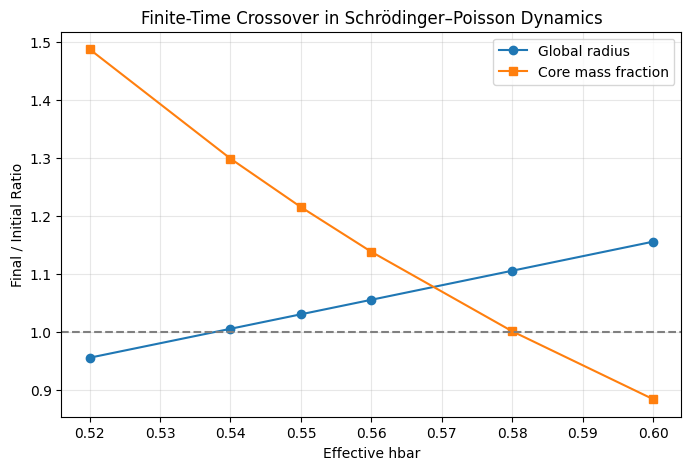

This is not quantum gravity or a thermodynamic phase transition.


In [38]:

# VALIDATION: FINITE-TIME PARAMETER CROSSOVER (NOT PHASE TRANSITION)

import numpy as np
import matplotlib.pyplot as plt

hbar_test = [0.52, 0.54, 0.55, 0.56, 0.58, 0.60]

core_mask = R2_24 <= SIGMA_Q**2
rho0 = np.abs(initial_psi24)**2
core0 = rho0[core_mask].sum() / rho0.sum()

radius_ratios = []
core_ratios = []

for h in hbar_test:
    if (h, True) in results24:
        r = results24[(h, True)]
    else:
        r = run_quantum24(h, gravity_on=True)

    rho = r["final_density"]

    radius_ratio = r["radius"][-1] / r["radius"][0]
    core_ratio = (rho[core_mask].sum() / rho.sum()) / core0

    radius_ratios.append(radius_ratio)
    core_ratios.append(core_ratio)

    print(
        f"hbar={h:.2f} | "
        f"Radius={radius_ratio:.4f} | "
        f"Core={core_ratio:.4f} | "
        f"Energy error={np.max(r['energy_error']):.4f}%"
    )

plt.figure(figsize=(8, 5))
plt.plot(hbar_test, radius_ratios, "o-", label="Global radius")
plt.plot(hbar_test, core_ratios, "s-", label="Core mass fraction")
plt.axhline(1, linestyle="--", color="gray")
plt.xlabel("Effective hbar")
plt.ylabel("Final / Initial Ratio")
plt.title("Finite-Time Crossover in Schrödinger–Poisson Dynamics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("This is not quantum gravity or a thermodynamic phase transition.")


GRID | RADIUS RATIO | CORE MASS RATIO
 32  | 1.030834    | 1.239620
 48  | 1.030831    | 1.215669
 64  | 1.030830    | 1.217586

48 vs 64 core difference: 0.1575%
Core growth on every grid: True
NOTE: Fixed-radius core is a diagnostic, not a bound core/soliton.


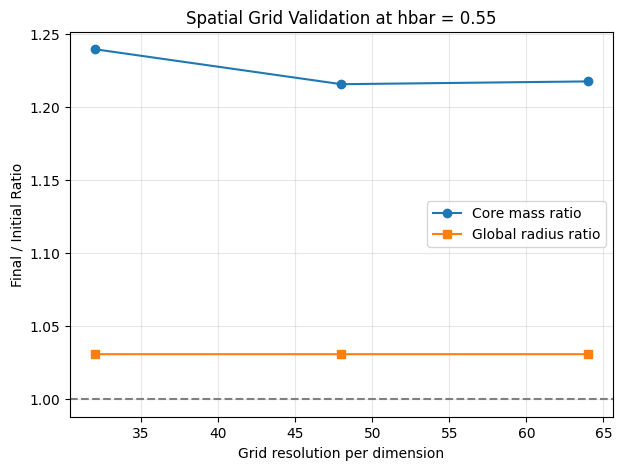

In [39]:

# GRID-SENSITIVITY TEST: CENTRAL MASS FRACTION
# hbar = 0.55, time = 3.0

import numpy as np
import matplotlib.pyplot as plt

def core_grid_test(n, hbar=0.55):
    dx = LQ / n
    coords = (np.arange(n) - n//2) * dx
    x, y, z = np.meshgrid(coords, coords, coords, indexing="ij")
    r2 = x*x + y*y + z*z
    core = r2 <= SIGMA_Q**2

    psi = np.exp(-r2/(4*SIGMA_Q**2)).astype(complex)
    psi *= np.sqrt(MASS_Q / (np.sum(abs(psi)**2)*dx**3))

    rho0 = abs(psi)**2
    initial_core = rho0[core].sum() / rho0.sum()
    initial_radius = np.sqrt((r2*rho0).sum()/rho0.sum())

    k = 2*np.pi*np.fft.fftfreq(n, d=dx)
    kx, ky, kz = np.meshgrid(k, k, k, indexing="ij")
    k2 = kx*kx + ky*ky + kz*kz

    kernel = np.zeros_like(k2)
    kernel[k2 > 0] = -4*np.pi*GQ/k2[k2 > 0]

    def potential(wave):
        return np.fft.ifftn(
            np.fft.fftn(abs(wave)**2)*kernel
        ).real

    phi = potential(psi)
    kinetic = np.exp(-0.5j*hbar*k2*DT24)

    for _ in range(STEPS24):
        psi *= np.exp(-0.5j*DT24*phi/hbar)
        psi = np.fft.ifftn(np.fft.fftn(psi)*kinetic)
        phi = potential(psi)
        psi *= np.exp(-0.5j*DT24*phi/hbar)

    rho = abs(psi)**2
    final_core = rho[core].sum()/rho.sum()
    final_radius = np.sqrt((r2*rho).sum()/rho.sum())

    return final_radius/initial_radius, final_core/initial_core

# Reuse existing N=48 results
rho48 = results24[(0.55, True)]["final_density"]
mask48 = R2_24 <= SIGMA_Q**2
rho_initial48 = abs(initial_psi24)**2

core_initial48 = (
    rho_initial48[mask48].sum()/rho_initial48.sum()
)
core_final48 = rho48[mask48].sum()/rho48.sum()

grid_results = {
    32: core_grid_test(32),
    48: (
        results24[(0.55, True)]["radius"][-1] /
        results24[(0.55, True)]["radius"][0],
        core_final48/core_initial48
    ),
    64: core_grid_test(64)
}

print("GRID | RADIUS RATIO | CORE MASS RATIO")

for n, (radius, core) in grid_results.items():
    print(f"{n:3d}  | {radius:.6f}    | {core:.6f}")

core_difference = (
    100*abs(grid_results[48][1]-grid_results[64][1])
    /grid_results[64][1]
)

print(f"\n48 vs 64 core difference: {core_difference:.4f}%")
print("Core growth on every grid:",
      all(v[1] > 1 for v in grid_results.values()))
print("NOTE: Fixed-radius core is a diagnostic, not a bound core/soliton.")

grids = sorted(grid_results)
plt.figure(figsize=(7, 5))
plt.plot(grids, [grid_results[n][1] for n in grids],
         "o-", label="Core mass ratio")
plt.plot(grids, [grid_results[n][0] for n in grids],
         "s-", label="Global radius ratio")
plt.axhline(1, color="gray", linestyle="--")
plt.xlabel("Grid resolution per dimension")
plt.ylabel("Final / Initial Ratio")
plt.title("Spatial Grid Validation at hbar = 0.55")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [40]:

# SAVE FINAL VALIDATION RESULTS AND EXPORT

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import shutil
try:
    from google.colab import files
except ImportError:
    files = None  # Also allows execution in a local Jupyter kernel

root = Path("/content/Gravity_Quantum_Final")
data_dir = root / "datasets"
fig_dir = root / "figures"
doc_dir = root / "documentation"

data_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)
doc_dir.mkdir(parents=True, exist_ok=True)

# Save transition validation
pd.DataFrame({
    "effective_hbar": hbar_test,
    "radius_ratio": radius_ratios,
    "core_mass_ratio": core_ratios
}).to_csv(data_dir / "transition_validation.csv", index=False)

# Save grid validation
pd.DataFrame([
    {
        "grid": n,
        "radius_ratio": grid_results[n][0],
        "core_mass_ratio": grid_results[n][1]
    }
    for n in sorted(grid_results)
]).to_csv(data_dir / "core_grid_validation.csv", index=False)

# Save transition figure
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(hbar_test, radius_ratios, "o-", label="Global radius")
ax.plot(hbar_test, core_ratios, "s-", label="Core mass fraction")
ax.axhline(1, color="gray", linestyle="--")
ax.set(xlabel="Effective hbar", ylabel="Final / Initial Ratio",
       title="Finite-Time Structural Crossover")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(fig_dir / "11_transition_validation.png", dpi=300)
fig.savefig(fig_dir / "11_transition_validation.pdf", bbox_inches="tight")
plt.close(fig)

# Save grid figure
grids = sorted(grid_results)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(grids, [grid_results[n][0] for n in grids],
        "o-", label="Global radius")
ax.plot(grids, [grid_results[n][1] for n in grids],
        "s-", label="Core mass fraction")
ax.axhline(1, color="gray", linestyle="--")
ax.set(xlabel="Grid points per dimension",
       ylabel="Final / Initial Ratio",
       title="Spatial Grid Sensitivity at Effective hbar = 0.55")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(fig_dir / "12_core_grid_validation.png", dpi=300)
fig.savefig(fig_dir / "12_core_grid_validation.pdf", bbox_inches="tight")
plt.close(fig)

print("Final validation datasets and figures saved.")
# Download occurs after final README and audit are written.


# ---------- AUTHORITATIVE FINAL README (AFTER NEW VALIDATION) ----------
# This supersedes the README written by the earlier export cell.
wave055 = results24[(0.55, True)]
R055 = float(wave055["radius"][-1] / wave055["radius"][0])
C055 = float(next(r["central_mass_fraction_ratio"] for r in rows_core if abs(r["effective_hbar"] - 0.55) < 1e-12))
from textwrap import dedent
pm_energy_error = max(float(r["max_energy_error"]) for r in results32)
finite_time = float(TIME24[-1])
core_grid_error = float(core_difference)
core_peak_ratio = float(wave055["peak"][-1] / wave055["peak"][0])
validation_passes = sum(bool(v) for v in checks.values())
validation_total = len(checks)

final_readme = dedent(f"""
# Classical and Quantum-Wave Dynamics of Self-Gravitating Systems

**Author: Kanak** | Python / Google Colab | Dimensionless computational study

## Research question
Can a self-gravitating wave cloud grow in overall size while its mass becomes
more centrally concentrated over a fixed simulation interval? How does this
compare with classical particle dynamics and coarse-grained spatial entropy?

## Main finite-time result
At **effective ℏ = 0.55**, dimensionless **t = {finite_time:g}**, and with an
initially Gaussian cloud in a periodic Newtonian Schrödinger–Poisson model:

| Measured diagnostic | Final / initial value |
|---|---:|
| Global RMS radius | **{R055:.6f}** |
| Mass fraction within the fixed initial Gaussian width | **{C055:.6f}** |
| Maximum density | **{core_peak_ratio:.6f}** |

A larger global RMS radius together with a larger *fraction* of mass in the
fixed central volume is observed for these tested conditions. The inner
fraction is **not** a new mass source: the total mass is conserved and mass
is redistributed. The result is not proof of a bound soliton or a new
astrophysical phenomenon.

![Global expansion vs local concentration](figures/10_two_scale_structure.png)

## Parameter study
The closer parameter sweep **0.52–0.60** finds an intermediate range in which
both measures increase. This is a **finite-time crossover** under a specified
model, **not** a thermodynamic or quantum-gravity phase transition.

![Finite-time structural crossover](figures/11_transition_validation.png)

## Grid check
At ℏ = 0.55 the fixed-core ratio is compared on 32³, 48³, and 64³ grids.
The relative difference between the two finer grids is **{core_grid_error:.4f}%**;
this checks sensitivity to these three spatial discretizations, not the
complete continuum limit. The sharp core-radius cutoff introduces some
resolution dependence of its own.

![Spatial grid sensitivity](figures/12_core_grid_validation.png)

## Methods and controls
- Softened Newtonian N-body dynamics and velocity-Verlet integration;
  the early *planar* particles interact via a 3D inverse-square force law,
  **not** the fundamental 2D gravitational Poisson problem.
- 3D Plummer-cluster response to initial-velocity perturbations.
- A classical 3D cloud-in-cell particle-mesh model and an energy-matched
  comparison to a Gaussian Schrödinger–Poisson wave field. Energy matching
  does **not** make the classical and wave models identical.
- FFT solution of the periodic Poisson equation with mean-density subtraction
  and a second-order Strang splitting algorithm for wave dynamics.
- Coarse-grained spatial Shannon entropy as a distributional diagnostic.
- Poisson residual, time-reversal, free Gaussian benchmark, mass/energy
  conservation, time-step, grid, and finite-box checks.

## Recorded checks and limitations
The auxiliary periodic-wave audit reports **{validation_passes}/{validation_total}**
checks passing under its documented thresholds. The energy-matched classical
particle-mesh experiments have a worst reported relative energy deviation of
approximately **{pm_energy_error:.4f}%**; that is less accurate than the wave
runs and should not be concealed. No test rules out every modelling or
numerical uncertainty.

- All parameters are **dimensionless**; no astronomical measurement or
  observation is being fitted.
- The Schrödinger–Poisson model uses Newtonian gravity; it does **not**
  simulate quantum gravity.
- Its potential is periodic, and edge effects, grid spacing, sharp core
  mask, finite run time, and selected initial conditions limit conclusions.
- Spatial Shannon entropy is **not** a measurement of total thermodynamic
  entropy.
- Plummer kinetic-temperature curves and finite-time energy–temperature
  fits are **non-equilibrium diagnostics**, not confirmed negative heat
  capacity of an equilibrium cluster.
- A constructed virial-scaling family is a mathematical illustration, not
  an independent discovery or experiment.
- No claim of scientific novelty, universal stability, or experimental
  detection is made.

## Reproducibility
1. Open the accompanying `.ipynb` in Google Colab (Python 3).
2. Select **Runtime → Disconnect and delete runtime** before a clean rerun.
3. Run all cells sequentially with NumPy, SciPy, Pandas, Matplotlib.
4. The *last* code cell writes the authoritative README, CSV datasets,
   figures, numerical audit summaries, and final results ZIP.
5. Include the source `.ipynb` separately when sharing the exported ZIP.

## Repository layout
- `*.ipynb` — complete, executable simulation source
- `datasets/` — numerical CSV exports
- `figures/` — saved PNG and PDF visualizations
- `additional_validation/` — independent box/timestep reports
- `documentation/` — scientific audit and limitations

**For all figures, compare the stated parameters, time interval, and
boundary conditions before drawing a physical conclusion.**
""").strip() + "\n"
(root / "README.md").write_text(final_readme, encoding="utf-8")

# Record the exact two-scale and grid summaries in the exported documentation.
from datetime import datetime, timezone
scientific_summary = {
    "model": "dimensionless Newtonian Schrödinger–Poisson, periodic box",
    "effective_hbar": 0.55,
    "final_time": float(TIME24[-1]),
    "rms_radius_final_over_initial": R055,
    "fixed_core_fraction_final_over_initial": C055,
    "grid_48_vs_64_core_relative_difference_percent": float(core_difference),
    "core_defined_by": "radius <= initial Gaussian sigma",
    "heat_capacity_equilibrium_confirmed": False,
    "phase_transition_claimed": False,
    "max_kinetic_matched_pm_energy_error_percent": pm_energy_error,
    "periodic_wave_audit_checks_passed": validation_passes,
    "periodic_wave_audit_checks_total": validation_total,
    "full_run_rechecked_on_current_revision": "Must execute all cells in fresh runtime"
}
import json
(root / "documentation" / "key_results.json").write_text(
    json.dumps(scientific_summary, indent=2), encoding="utf-8"
)

# Rebuild ZIP so the latest README and summary are actually included.
archive = shutil.make_archive(
    "/content/Gravity_Quantum_Final_COMPLETE", "zip",
    root_dir=str(root.parent), base_dir=root.name
)
print("Final archive refreshed with revised README and scientific summary.")

print("Export files:", len(list(data_dir.glob("*.csv"))), "CSVs,",
      len(list(fig_dir.glob("*.png"))), "PNGs,",
      len(list(fig_dir.glob("*.pdf"))), "PDFs")
print("Notebook source is kept separately and must be uploaded alongside the ZIP.")
if files is not None:
    files.download(archive)
else:
    print("Saved ZIP:", archive)


Final validation datasets and figures saved.
Final archive refreshed with revised README and scientific summary.
Export files: 13 CSVs, 12 PNGs, 12 PDFs
Notebook source is kept separately and must be uploaded alongside the ZIP.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>